# Suicide/Depression/Teenager Classification — v13 Dataset Only

This notebook uses only:

`kaggle-data/SuicideAndDepression_Detection.csv`

The v14 dataset (`Suicide_Detection.csv`) is not loaded, merged, or used anywhere.

**Pipeline retained:**
- One canonical **70% train / 15% validation / 15% test** stratified split (`random_state=42`)
- Hierarchical TF-IDF, SGD TF-IDF, LightGBM, DistilBERT, DistilRoBERTa, GUSE, and MiniLM tree models
- Validation-based hybrid-weight selection without test-set leakage
- Full model comparison, confusion matrices, ROC/AUC, inference-resource benchmarking, and explainability
- v13-specific split files, probability caches, embeddings, model files, and result CSVs to prevent old two-dataset artifacts from being reused

Run the notebook from top to bottom.


In [1]:
import pandas as pd
import numpy as np
import os

def save_results_to_csv(model_name, y_true, y_pred, filename="all_models_results_compare_v13.csv"):
    """
    Saves predictions to a CSV file.
    - If file doesn't exist: Creates it with 'True_Labels' and the model's preds.
    - If file exists: Loads it and appends a new column for this model.
    """
    print(f"💾 Saving {model_name} results...")
    
    # 1. Force inputs to be simple numpy arrays (Fixes the Index/Series Error)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # 2. Create a DataFrame for the current run
    new_data = pd.DataFrame({
        'True_Labels': y_true,
        f'Pred_{model_name}': y_pred
    })
    
    # 3. Check if the file already exists
    if os.path.exists(filename):
        # Load existing data
        df_existing = pd.read_csv(filename)
        
        # SANITY CHECK: Ensure we are comparing the exact same dataset rows
        # We use .values to ignore index mismatches
        if not np.array_equal(df_existing['True_Labels'].values, new_data['True_Labels'].values):
            print("❌ CRITICAL WARNING: The 'y_true' labels don't match the file!")
            print("   Did you shuffle the test set differently? Results will be invalid.")
            return

        # Add the new column
        df_existing[f'Pred_{model_name}'] = new_data[f'Pred_{model_name}']
        df_existing.to_csv(filename, index=False)
    else:
        # Create new file
        new_data.to_csv(filename, index=False)
        
    print(f"✅ Successfully saved to '{filename}'")

In [2]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, recall_score
import os

# ── Create file with correct structure if it doesn't exist ──
filename = "all_models_results_compare_v13.csv"

if not os.path.exists(filename):
    print("⚠️ File not found. Creating empty file with correct columns...")
    empty_df = pd.DataFrame(columns=[
        'True_Labels',
        'Pred_Hierarchical_TFIDF',
        'Pred_LightGBM',
        'Pred_DistilBERT',
        'Pred_DistilRoBERTa',
        'Pred_GUSE_Dense'
    ])
    empty_df.to_csv(filename, index=False)
    print(f"✅ Created '{filename}' with correct columns. Now run your models to fill it.")
else:
    # ── Load existing file ──
    df = pd.read_csv(filename)
    print("Available columns:", df.columns.tolist())
    print(f"Rows: {len(df)}")

Available columns: ['True_Labels', 'Pred_Hierarchical_TFIDF', 'Pred_LightGBM']
Rows: 52216


In [3]:


import time, os, gc
import numpy as np
import pandas as pd
import psutil

try:
    import torch
    _TORCH_AVAILABLE = True
except ImportError:
    _TORCH_AVAILABLE = False

RESOURCE_LOG_FILE = "inference_resource_log_v13.csv"

def _gpu_reset():
    if _TORCH_AVAILABLE and torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

def _gpu_peak_mb():
    if _TORCH_AVAILABLE and torch.cuda.is_available():
        return torch.cuda.max_memory_allocated() / (1024 ** 2)
    return 0.0

def measure_inference(model_name, predict_fn, n_samples):
    """
    Times predict_fn() (a zero-arg callable that runs inference on the
    FULL test set) and records CPU/RAM/GPU usage. Appends the result to
    RESOURCE_LOG_FILE so all models' numbers accumulate in one place.
    """
    process = psutil.Process(os.getpid())
    gc.collect()
    _gpu_reset()

    mem_before = process.memory_info().rss / (1024 ** 2)
    cpu_before = process.cpu_times()
    psutil.cpu_percent(interval=None)  # prime measurement

    t0 = time.perf_counter()
    output = predict_fn()
    t1 = time.perf_counter()

    cpu_percent = psutil.cpu_percent(interval=None)
    cpu_after = process.cpu_times()
    mem_after = process.memory_info().rss / (1024 ** 2)
    total_time = t1 - t0

    result = {
        "Model": model_name,
        "N_Samples": n_samples,
        "Total_Inference_Time_s": round(total_time, 4),
        "Latency_ms_per_sample": round((total_time / n_samples) * 1000, 4) if n_samples else None,
        "Throughput_samples_per_s": round(n_samples / total_time, 2) if total_time > 0 else None,
        "CPU_Time_s": round((cpu_after.user + cpu_after.system) - (cpu_before.user + cpu_before.system), 4),
        "CPU_Percent": cpu_percent,
        "RAM_Used_MB": round(mem_after - mem_before, 2),
        "RAM_Peak_MB": round(mem_after, 2),
        "GPU_Peak_MB": round(_gpu_peak_mb(), 2),
    }

    if os.path.exists(RESOURCE_LOG_FILE):
        df_log = pd.read_csv(RESOURCE_LOG_FILE)
        df_log = df_log[df_log["Model"] != model_name]  # replace if re-run
        df_log = pd.concat([df_log, pd.DataFrame([result])], ignore_index=True)
    else:
        df_log = pd.DataFrame([result])
    df_log.to_csv(RESOURCE_LOG_FILE, index=False)

    print(f"⏱️  {model_name}: {total_time:.3f}s total | "
          f"{result['Latency_ms_per_sample']:.3f} ms/sample | "
          f"{result['Throughput_samples_per_s']:.1f} samples/s | "
          f"RAM Δ {result['RAM_Used_MB']:.1f} MB | GPU peak {result['GPU_Peak_MB']:.1f} MB")

    return output, result

In [4]:
import tensorflow as tf

print("TF version:", tf.__version__)
print("TF built with CUDA:", tf.test.is_built_with_cuda())
print("Physical GPU devices seen by TF:", tf.config.list_physical_devices('GPU'))

import torch
print("\nPyTorch sees CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("PyTorch device:", torch.cuda.get_device_name(0))

TF version: 2.21.0
TF built with CUDA: False
Physical GPU devices seen by TF: []

PyTorch sees CUDA: True
PyTorch device: NVIDIA GeForce RTX 3050 Laptop GPU


In [5]:
import tensorflow as tf
print("TF version:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())

TF version: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### Canonical v13-only data split

This cell loads only `SuicideAndDepression_Detection.csv`, cleans and maps its three classes, then creates one reproducible 70/15/15 stratified split. All downstream models reuse these exact v13 rows.


In [6]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# ==========================================
# CANONICAL V13-ONLY TRAIN / VALIDATION / TEST SPLIT
# ==========================================
RANDOM_STATE = 42
V13_DATASET_PATH = "kaggle-data/SuicideAndDepression_Detection.csv"
V13_SPLIT_DIR = "kaggle-data/split-data-v13"
os.makedirs(V13_SPLIT_DIR, exist_ok=True)

TRAIN_CSV = os.path.join(V13_SPLIT_DIR, "train_split_v13.csv")
VAL_CSV   = os.path.join(V13_SPLIT_DIR, "val_split_v13.csv")
TEST_CSV  = os.path.join(V13_SPLIT_DIR, "test_split_v13.csv")

# Set True when you intentionally want to rebuild the same deterministic split.
FORCE_REBUILD_SPLIT = False

if (
    not FORCE_REBUILD_SPLIT
    and all(os.path.exists(p) for p in (TRAIN_CSV, VAL_CSV, TEST_CSV))
):
    train_df = pd.read_csv(TRAIN_CSV)
    val_df   = pd.read_csv(VAL_CSV)
    test_df  = pd.read_csv(TEST_CSV)
    print(
        f"✅ Loaded existing v13-only split: "
        f"train={len(train_df)}, val={len(val_df)}, test={len(test_df)}"
    )
else:
    print("🔄 Building canonical split from the v13 dataset only...")

    # Only v13 is loaded. The v14 dataset is intentionally not used.
    df_v13 = pd.read_csv(
        V13_DATASET_PATH,
        usecols=["text", "class"],
    ).copy()

    # Basic cleaning before label mapping.
    df_v13 = df_v13.dropna(subset=["text", "class"]).copy()
    df_v13["text"] = df_v13["text"].astype(str).str.strip()
    df_v13["class"] = df_v13["class"].astype(str).str.lower().str.strip()
    df_v13 = df_v13[df_v13["text"].ne("")].copy()

    map_v13 = {
        "teenagers": "Teenagers",
        "depression": "Depression",
        "suicidewatch": "Suicide",
    }
    df_v13["final_label"] = df_v13["class"].map(map_v13)

    unmapped_classes = sorted(
        df_v13.loc[df_v13["final_label"].isna(), "class"].unique().tolist()
    )
    if unmapped_classes:
        print(f"⚠️ Ignoring unmapped v13 classes: {unmapped_classes}")

    df_v13 = df_v13.dropna(subset=["final_label"]).copy()
    df_v13 = df_v13.drop_duplicates(subset=["text"], keep="first").copy()

    label_map = {
        "Teenagers": 0,
        "Depression": 1,
        "Suicide": 2,
    }
    df_v13["label"] = df_v13["final_label"].map(label_map).astype(int)
    df_final = df_v13[["text", "label"]].reset_index(drop=True)

    print(f"✅ Clean v13 dataset size: {len(df_final):,} unique posts")
    print("Class counts:")
    print(
        df_final["label"]
        .value_counts()
        .sort_index()
        .rename(index={0: "Teenagers", 1: "Depression", 2: "Suicide"})
    )

    train_df, temp_df = train_test_split(
        df_final,
        test_size=0.30,
        stratify=df_final["label"],
        random_state=RANDOM_STATE,
    )
    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        stratify=temp_df["label"],
        random_state=RANDOM_STATE,
    )

    # Reset indices so every saved prediction aligns row-for-row.
    train_df = train_df.reset_index(drop=True)
    val_df   = val_df.reset_index(drop=True)
    test_df  = test_df.reset_index(drop=True)

    train_df.to_csv(TRAIN_CSV, index=False)
    val_df.to_csv(VAL_CSV, index=False)
    test_df.to_csv(TEST_CSV, index=False)

    print(
        f"✅ Saved v13-only splits: "
        f"train={len(train_df)}, val={len(val_df)}, test={len(test_df)}"
    )

# Validate the split files before any model uses them.
expected_columns = {"text", "label"}
for split_name, split_df in {
    "train": train_df,
    "validation": val_df,
    "test": test_df,
}.items():
    if not expected_columns.issubset(split_df.columns):
        raise ValueError(
            f"{split_name} split must contain columns {sorted(expected_columns)}; "
            f"found {split_df.columns.tolist()}"
        )
    if split_df[["text", "label"]].isna().any().any():
        raise ValueError(f"{split_name} split contains missing text or labels.")

print("\nClass balance (0=Teenagers, 1=Depression, 2=Suicide):")
print(
    pd.DataFrame({
        "train": train_df["label"].value_counts(normalize=True).sort_index(),
        "val":   val_df["label"].value_counts(normalize=True).sort_index(),
        "test":  test_df["label"].value_counts(normalize=True).sort_index(),
    }).round(3)
)

# Shared aliases used by all model cells.
X_train, y_train = train_df["text"], train_df["label"]
X_val,   y_val   = val_df["text"],   val_df["label"]
X_test,  y_test  = test_df["text"],  test_df["label"]


✅ Loaded existing v13-only split: train=243673, val=52216, test=52216

Class balance (0=Teenagers, 1=Depression, 2=Suicide):
       train    val   test
label                     
0      0.333  0.333  0.333
1      0.333  0.333  0.333
2      0.333  0.333  0.333


Starting Pipeline:   0%|          | 0/5 [00:00<?, ?step/s]

✅ Loaded split: train=243673, val=52216, test=52216


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.


✅ Screener Val Accuracy (L1): 0.9224


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  3.9min finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 100 out of 100 | elapsed:    0.2s finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s


✅ Specialist Val Accuracy (L2): 0.7701


[Parallel(n_jobs=16)]: Done 100 out of 100 | elapsed:    0.2s finished



🏆 Final Hierarchical Model Results:
              precision    recall  f1-score   support

   Teenagers       0.85      0.93      0.89     17406
  Depression       0.75      0.70      0.72     17405
     Suicide       0.74      0.72      0.73     17405

    accuracy                           0.78     52216
   macro avg       0.78      0.78      0.78     52216
weighted avg       0.78      0.78      0.78     52216



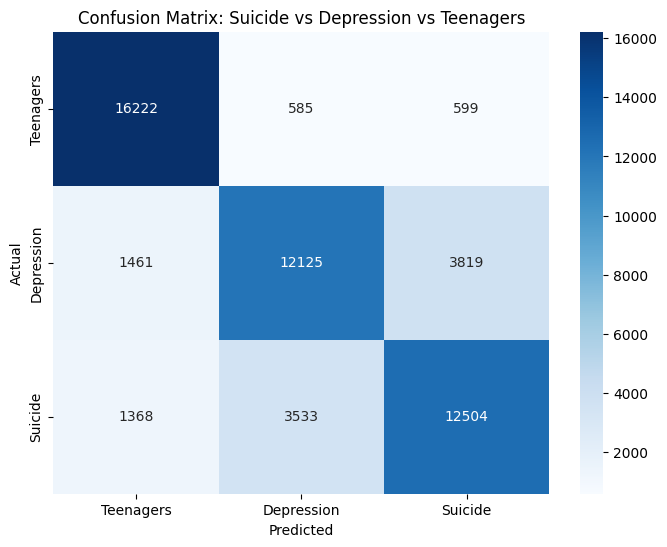

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm  # <--- NEW IMPORT

# Initialize the overall progress bar
pbar = tqdm(total=5, desc="Starting Pipeline", unit="step")

# ==========================================
# STEP 1: LOAD THE CANONICAL TRAIN/VAL/TEST SPLIT
# ==========================================
# Uses train_split_v13.csv / val_split_v13.csv / test_split_v13.csv saved by the
# "CANONICAL TRAIN / VALIDATION / TEST SPLIT" cell above, so every model in
# this notebook trains and evaluates on the exact same rows.
pbar.set_description("Step 1/5: Loading canonical split")

X_train, y_train = train_df['text'], train_df['label']
X_val,   y_val   = val_df['text'],   val_df['label']
X_test,  y_test  = test_df['text'],  test_df['label']

tqdm.write(f"✅ Loaded split: train={len(X_train)}, val={len(X_val)}, test={len(X_test)}")
pbar.update(1)

# ==========================================
# STEP 2: FEATURE ENGINEERING (TF-IDF)
# ==========================================
pbar.set_description("Step 5/8: Vectorizing (This takes time...)")

tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1,2))
X_train_vec = tfidf.fit_transform(X_train)
X_val_vec = tfidf.transform(X_val)
X_test_vec = tfidf.transform(X_test)

pbar.update(1)

# ==========================================
# STEP 3: HIERARCHICAL TRAINING
# ==========================================

# --- Level 1: Clinical vs. Non-Clinical ---
pbar.set_description("Step 3/5: Training Level 1 Screener")

y_train_l1 = y_train.apply(lambda x: 0 if x == 0 else 1)
y_val_l1   = y_val.apply(lambda x: 0 if x == 0 else 1)
y_test_l1  = y_test.apply(lambda x: 0 if x == 0 else 1)

# Added verbose=1 so you see the solver working
screener = LogisticRegression(class_weight='balanced', max_iter=1000, n_jobs=-1, verbose=1)
screener.fit(X_train_vec, y_train_l1)

# ── Validation check for Screener ──
val_pred_l1  = screener.predict(X_val_vec)
from sklearn.metrics import accuracy_score as _acc
tqdm.write(f"✅ Screener Val Accuracy (L1): {_acc(y_val_l1, val_pred_l1):.4f}")

pbar.update(1)

# --- Level 2: Differential Diagnosis ---
pbar.set_description("Step 4/5: Training Level 2 Specialist")

# 1. Create the Boolean Mask
mask_clinical = y_train != 0

# 2. Apply Mask (FIXED: Added .values)
X_train_l2 = X_train_vec[mask_clinical.values] 
y_train_l2 = y_train[mask_clinical]

# Added verbose=1 to see tree building progress
specialist = RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, verbose=1)
specialist.fit(X_train_l2, y_train_l2)

# ── Validation check for Specialist ──
mask_val_clinical = y_val != 0
X_val_l2 = X_val_vec[mask_val_clinical.values]
y_val_l2 = y_val[mask_val_clinical]
val_pred_l2 = specialist.predict(X_val_l2)
tqdm.write(f"✅ Specialist Val Accuracy (L2): {_acc(y_val_l2, val_pred_l2):.4f}")

pbar.update(1)

# ==========================================
# STEP 5: PREDICTION & EVALUATION
# ==========================================
pbar.set_description("Step 5/5: Final Evaluation")

# 1. Screen all test data
l1_preds = screener.predict(X_test_vec)

# 2. Prepare final array
final_preds = np.zeros_like(l1_preds)

# 3. Find clinical cases and ask Specialist
clinical_indices = (l1_preds == 1)
if clinical_indices.sum() > 0:
    X_clinical = X_test_vec[clinical_indices]
    l2_preds = specialist.predict(X_clinical)
    final_preds[clinical_indices] = l2_preds

pbar.update(1)
pbar.close() # Close the progress bar

# 4. Report
print("\n🏆 Final Hierarchical Model Results:")
target_names = ['Teenagers', 'Depression', 'Suicide']
print(classification_report(y_test, final_preds, target_names=target_names))

# Plot Confusion Matrix 
cm = confusion_matrix(y_test, final_preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix: Suicide vs Depression vs Teenagers')
plt.show()

In [8]:
# ── Inference time & resource usage ──
def _hier_predict():
    l1 = screener.predict(X_test_vec)
    preds = np.zeros_like(l1)
    idx = (l1 == 1)
    if idx.sum() > 0:
        preds[idx] = specialist.predict(X_test_vec[idx])
    return preds

_ = measure_inference("Hierarchical_TFIDF", _hier_predict, X_test_vec.shape[0])

[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s


⏱️  Hierarchical_TFIDF: 0.339s total | 0.006 ms/sample | 153809.7 samples/s | RAM Δ 1.8 MB | GPU peak 0.0 MB


[Parallel(n_jobs=16)]: Done 100 out of 100 | elapsed:    0.2s finished


In [9]:
import os

# Delete the old mismatched file
if os.path.exists("all_models_results_compare_v13.csv"):
    os.remove("all_models_results_compare_v13.csv")
    print("🗑️ Old file deleted.")

# Now save fresh
save_results_to_csv("Hierarchical_TFIDF", y_test, final_preds)

🗑️ Old file deleted.
💾 Saving Hierarchical_TFIDF results...
✅ Successfully saved to 'all_models_results_compare_v13.csv'


📥 Loading canonical split (train_split_v13.csv / val_split_v13.csv / test_split_v13.csv)...
✅ Loaded split: train=243673, val=52216, test=52216
⚙️ Vectorizing...
🚀 Starting Iterative Training (20 Epochs)...


Training Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

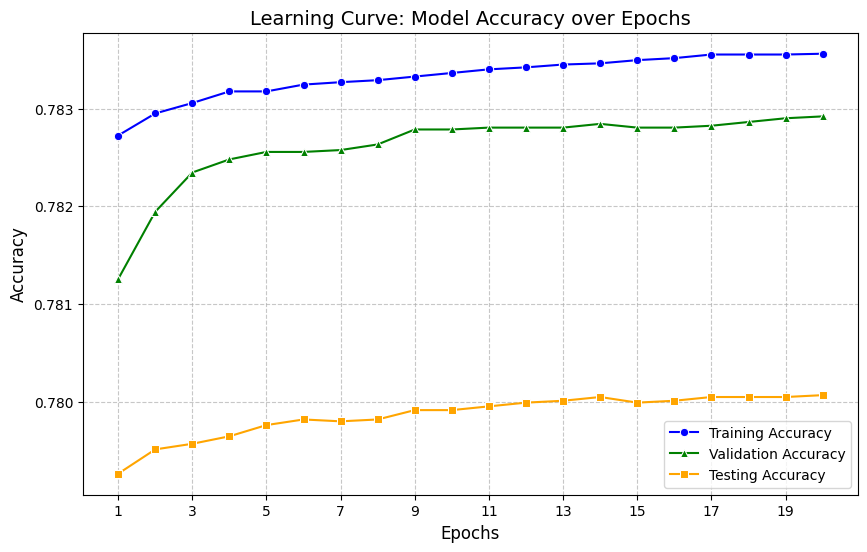


Final Training Accuracy:   0.7836
Final Validation Accuracy: 0.7829
Final Testing Accuracy:    0.7801

--- Final Classification Report ---
              precision    recall  f1-score   support

   Teenagers       0.82      0.93      0.87     17406
  Depression       0.76      0.70      0.73     17405
     Suicide       0.75      0.71      0.73     17405

    accuracy                           0.78     52216
   macro avg       0.78      0.78      0.78     52216
weighted avg       0.78      0.78      0.78     52216



In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, classification_report
from tqdm.auto import tqdm

# ==========================================
# STEP 1: LOAD THE CANONICAL TRAIN/VAL/TEST SPLIT
# ==========================================
print("📥 Loading canonical split (train_split_v13.csv / val_split_v13.csv / test_split_v13.csv)...")

X_train_raw, y_train = train_df['text'], train_df['label']
X_val_raw,   y_val   = val_df['text'],   val_df['label']
X_test_raw,  y_test  = test_df['text'],  test_df['label']

print(f"✅ Loaded split: train={len(X_train_raw)}, val={len(X_val_raw)}, test={len(X_test_raw)}")

# Vectorize (TF-IDF)
print("⚙️ Vectorizing...")
tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1,2))
X_train = tfidf.fit_transform(X_train_raw)
X_val   = tfidf.transform(X_val_raw)
X_test  = tfidf.transform(X_test_raw)

# ==========================================
# STEP 2: ITERATIVE TRAINING LOOP
# ==========================================
print("🚀 Starting Iterative Training (20 Epochs)...")

# We use SGDClassifier because it supports 'partial_fit' (epoch-by-epoch training)
# Loss='log_loss' makes it equivalent to Logistic Regression
# Loss='hinge' makes it a Linear SVM
model = SGDClassifier(loss='log_loss', learning_rate='optimal', max_iter=1, warm_start=True, random_state=42)

epochs = 20
train_acc_history = []
val_acc_history   = []
test_acc_history  = []
epoch_list = []

# Classes must be known upfront for partial_fit
classes = np.unique(y_train)

# Progress bar for Epochs
for epoch in tqdm(range(epochs), desc="Training Epochs"):
    # Train one epoch
    model.partial_fit(X_train, y_train, classes=classes)
    
    # Evaluate on Train Data (to check learning)
    train_pred = model.predict(X_train)
    train_acc = accuracy_score(y_train, train_pred)
    train_acc_history.append(train_acc)
    
    # Evaluate on Validation Data (to check generalization without data leakage)
    val_pred = model.predict(X_val)
    val_acc  = accuracy_score(y_val, val_pred)
    val_acc_history.append(val_acc)

    # Evaluate on Test Data (to check generalization)
    test_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)
    test_acc_history.append(test_acc)
    
    epoch_list.append(epoch + 1)

# ==========================================
# STEP 3: PLOTTING LEARNING CURVES (Q1 STYLE)
# ==========================================
plt.figure(figsize=(10, 6))

# Plot Training Accuracy
sns.lineplot(x=epoch_list, y=train_acc_history, label='Training Accuracy', marker='o', color='blue')

# Plot Validation Accuracy
sns.lineplot(x=epoch_list, y=val_acc_history, label='Validation Accuracy', marker='^', color='green')

# Plot Testing Accuracy
sns.lineplot(x=epoch_list, y=test_acc_history, label='Testing Accuracy', marker='s', color='orange')

plt.title('Learning Curve: Model Accuracy over Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.xticks(np.arange(1, epochs + 1, step=2)) # Show integer ticks

plt.show()

# ==========================================
# STEP 4: FINAL REPORT
# ==========================================
print(f"\nFinal Training Accuracy:   {train_acc_history[-1]:.4f}")
print(f"Final Validation Accuracy: {val_acc_history[-1]:.4f}")
print(f"Final Testing Accuracy:    {test_acc_history[-1]:.4f}")
print("\n--- Final Classification Report ---")
target_names = ['Teenagers', 'Depression', 'Suicide']
print(classification_report(y_test, test_pred, target_names=target_names))

In [11]:
_ = measure_inference("SGD_TFIDF", lambda: model.predict(X_test), X_test.shape[0])

⏱️  SGD_TFIDF: 0.019s total | 0.000 ms/sample | 2816427.4 samples/s | RAM Δ 0.0 MB | GPU peak 0.0 MB


In [12]:
# ── Inference time & resource usage ──
def _hier_predict():
    l1 = screener.predict(X_test_vec)
    preds = np.zeros_like(l1)
    idx = (l1 == 1)
    if idx.sum() > 0:
        preds[idx] = specialist.predict(X_test_vec[idx])
    return preds

_ = measure_inference("Hierarchical_TFIDF", _hier_predict, X_test_vec.shape[0])

[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s


⏱️  Hierarchical_TFIDF: 0.370s total | 0.007 ms/sample | 141281.6 samples/s | RAM Δ 1.9 MB | GPU peak 0.0 MB


[Parallel(n_jobs=16)]: Done 100 out of 100 | elapsed:    0.2s finished


In [ ]:
!pip install --upgrade typing_extensions

In [ ]:
!pip install lightgbm


Starting Pipeline:   0%|          | 0/4 [00:00<?, ?step/s]

Feature Matrix Shape: (243673, 20000)
[50]	valid_0's multi_logloss: 0.638747
[100]	valid_0's multi_logloss: 0.559684
[150]	valid_0's multi_logloss: 0.523176
[200]	valid_0's multi_logloss: 0.501725

🏆 Final LightGBM Results:
              precision    recall  f1-score   support

   Teenagers       0.85      0.91      0.88     17406
  Depression       0.77      0.72      0.74     17405
     Suicide       0.76      0.75      0.76     17405

    accuracy                           0.80     52216
   macro avg       0.79      0.80      0.79     52216
weighted avg       0.79      0.80      0.79     52216



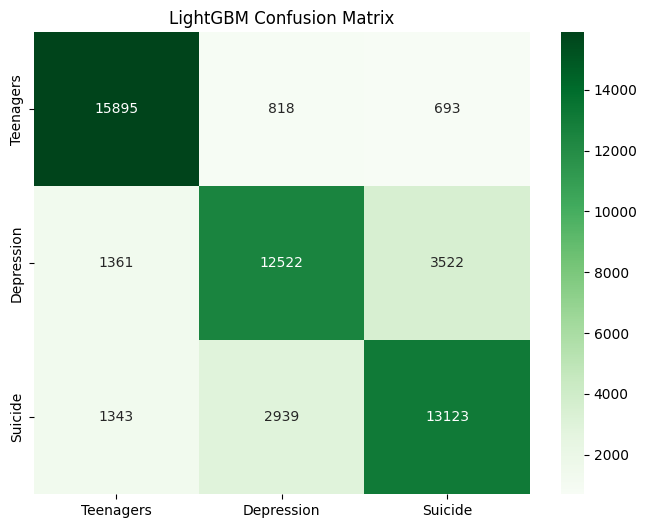

✅ LightGBM probabilities saved (test + validation) for hybrid fusion.


In [43]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm  # <--- NEW IMPORT

# Initialize Progress Bar (4 Major Steps)
pbar = tqdm(total=4, desc="Starting Pipeline", unit="step")

# ==========================================
# STEP 4: LOAD THE CANONICAL TRAIN/VAL/TEST SPLIT
# ==========================================
pbar.set_description("Step 1/4: Loading canonical split")

# Loads train_split_v13.csv / val_split_v13.csv / test_split_v13.csv saved earlier, so
# this model trains/evaluates on the exact same rows as every other model
# in the notebook -- this is what makes it valid to combine probabilities
# later in the Hybrid Fusion section.
X_train_text, y_train = train_df['text'], train_df['label']
X_val_text,   y_val   = val_df['text'],   val_df['label']
X_test_text,  y_test  = test_df['text'],  test_df['label']
pbar.update(1)

# ==========================================
# STEP 5: ADVANCED FEATURE ENGINEERING
# ==========================================
pbar.set_description("Step 2/4: Vectorizing (Takes time...)")

# 1. Increase features to 20,000 (Captures rare words)
# 2. sublinear_tf=True (Scales counts to reduce impact of repeated words)
# 3. NO STOP WORDS (Crucial for "not", "no", "never")
tfidf = TfidfVectorizer(
    max_features=20000, 
    ngram_range=(1, 2),  # Captures "give up", "no hope"
    sublinear_tf=True, 
    stop_words=None      # KEEP stop words for context
)

# Pass the RAW TEXT here
X_train_vec = tfidf.fit_transform(X_train_text)
X_val_vec   = tfidf.transform(X_val_text)
X_test_vec  = tfidf.transform(X_test_text)

# Print shape without breaking the progress bar
tqdm.write(f"Feature Matrix Shape: {X_train_vec.shape}")
pbar.update(1)

# ==========================================
# STEP 6: TRAIN LIGHTGBM
# ==========================================
pbar.set_description("Step 3/4: Training LightGBM")

model = lgb.LGBMClassifier(
    objective='multiclass',
    num_class=3,
    n_estimators=200,    # More trees = better learning
    learning_rate=0.05,  # Slower learning rate = better generalization
    num_leaves=31,       # Controls complexity
    class_weight='balanced', 
    random_state=42,
    n_jobs=-1,
    verbose=-1           # Hides warnings
)

# LightGBM doesn't support a built-in progress bar for sklearn API easily,
# but since it's fast, the step update is usually sufficient.
model.fit(
    X_train_vec, y_train,
    eval_set=[(X_val_vec, y_val)],
    callbacks=[lgb.early_stopping(10, verbose=False),
               lgb.log_evaluation(50)]
)
pbar.update(1)

# ==========================================
# EVALUATION
# ==========================================
pbar.set_description("Step 4/4: Evaluating")

y_pred = model.predict(X_test_vec)

pbar.update(1)
pbar.close()

# Report
print("\n🏆 Final LightGBM Results:")
target_names = ['Teenagers', 'Depression', 'Suicide']
print(classification_report(y_test, y_pred, target_names=target_names))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=target_names, yticklabels=target_names)
plt.title('LightGBM Confusion Matrix')
plt.show()

# ==========================================
# SAVE PROBABILITIES FOR THE HYBRID FUSION PIPELINE (test + validation)
# ==========================================
# Validation-set probabilities are saved so the fusion weight (alpha) can later
# be selected WITHOUT ever touching the test set. See the "Hybrid Fusion"
# section near the end of this notebook for how these files are used.
lgbm_test_probs = model.predict_proba(X_test_vec)
lgbm_val_probs  = model.predict_proba(X_val_vec)

np.save("lgbm_probs_v13.npy", lgbm_test_probs)      # test-set probabilities
np.save("lgbm_val_probs_v13.npy", lgbm_val_probs)   # validation-set probabilities
np.save("y_test_truth_v13.npy", np.array(y_test))
np.save("y_val_truth_v13.npy", np.array(y_val))
print("✅ LightGBM probabilities saved (test + validation) for hybrid fusion.")

# ── Log this model's TEST predictions to the shared comparison CSV ──


In [45]:
# STEP 2 — safe to run now; this overwrites `model` with LightGBM,
# but roberta_model_saved is untouched since it's a separate variable
import lightgbm as lgb
lgbm_model_saved = lgb.LGBMClassifier(
    objective='multiclass', num_class=3, n_estimators=200,
    learning_rate=0.05, num_leaves=31, class_weight='balanced',
    random_state=42, n_jobs=-1, verbose=-1
)
lgbm_model_saved.fit(
    X_train_vec, y_train,
    eval_set=[(X_val_vec, y_val)],
    callbacks=[lgb.early_stopping(10, verbose=False), lgb.log_evaluation(50)]
)
print("✅ lgbm_model_saved is ready.")

[50]	valid_0's multi_logloss: 0.638747
[100]	valid_0's multi_logloss: 0.559684
[150]	valid_0's multi_logloss: 0.523176
[200]	valid_0's multi_logloss: 0.501725
✅ lgbm_model_saved is ready.


In [15]:
save_results_to_csv("LightGBM", y_test, y_pred)

💾 Saving LightGBM results...
✅ Successfully saved to 'all_models_results_compare_v13.csv'


In [16]:
_ = measure_inference("LightGBM", lambda: model.predict(X_test_vec), X_test_vec.shape[0])

d:\Anaconda\envs\tweet_project\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


⏱️  LightGBM: 0.488s total | 0.009 ms/sample | 106926.5 samples/s | RAM Δ 97.0 MB | GPU peak 0.0 MB


In [ ]:
!pip install simpletransformers

CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Preparing canonical training split...
Training samples:   243,673
Validation samples: 52,216
Test samples:       52,216
Initializing DistilBERT...


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training started...


INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


Map:   0%|          | 0/243673 [00:00<?, ? examples/s]

...

Predicted 52,000/52,216 samples

INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


Map:   0%|          | 0/216 [00:00<?, ? examples/s]

Predicting:   0%|          | 0/14 [00:00<?, ?it/s]

Predicted 52,216/52,216 samples

DistilBERT Test Classification Report
              precision    recall  f1-score   support

   Teenagers     0.9702    0.9569    0.9635     17406
  Depression     0.8149    0.8018    0.8083     17405
     Suicide     0.8017    0.8256    0.8135     17405

    accuracy                         0.8614     52216
   macro avg     0.8623    0.8614    0.8618     52216
weighted avg     0.8623    0.8614    0.8618     52216



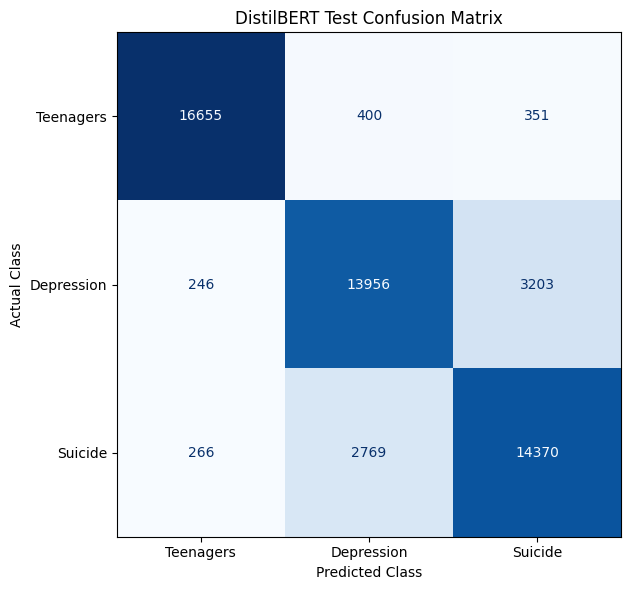

💾 Saving DistilBERT results...
✅ Successfully saved to 'all_models_results_compare_v13.csv'
DistilBERT results saved successfully.


In [7]:
# ============================================================
# MEMORY-OPTIMIZED DISTILBERT TRAINING AND EVALUATION
# ============================================================

import os

# Prevent excessive CPU/tokenizer parallelism
# Ideally, set these before importing torch/transformers.
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import gc
import logging
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from simpletransformers.classification import (
    ClassificationModel,
    ClassificationArgs
)

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO)

# Limit PyTorch CPU thread usage
torch.set_num_threads(1)

# ------------------------------------------------------------
# 1. CHECK GPU
# ------------------------------------------------------------

USE_CUDA = torch.cuda.is_available()

print(f"CUDA available: {USE_CUDA}")

if USE_CUDA:
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    torch.cuda.empty_cache()

gc.collect()


# ------------------------------------------------------------
# 2. CREATE LOW-OVERHEAD SIMPLETRANSFORMERS DATAFRAME
# ------------------------------------------------------------

def prepare_transformer_df(df):
    """
    Creates only the columns required by SimpleTransformers.

    copy=False minimizes unnecessary duplication of the original DataFrame.
    """
    output_df = df.loc[:, ["text", "label"]].rename(
        columns={"label": "labels"},
        copy=False
    )

    # Check labels without making unnecessary full-data copies
    if output_df["labels"].isna().any():
        raise ValueError("Missing values found in the label column.")

    if output_df["text"].isna().any():
        # Make a real copy only if text cleaning is necessary
        output_df = output_df.copy()
        output_df["text"] = output_df["text"].fillna("")

    output_df["labels"] = output_df["labels"].astype(np.int64)

    return output_df


print("Preparing canonical training split...")

bert_train_df = prepare_transformer_df(train_df)

print(f"Training samples:   {len(bert_train_df):,}")
print(f"Validation samples: {len(val_df):,}")
print(f"Test samples:       {len(test_df):,}")


# ------------------------------------------------------------
# 3. CONFIGURE DISTILBERT
# ------------------------------------------------------------

model_args = ClassificationArgs()

# Output directories
model_args.output_dir = "transformer_runs_v13/distilbert/outputs"
model_args.best_model_dir = "transformer_runs_v13/distilbert/best_model"
model_args.cache_dir = "transformer_runs_v13/distilbert/cache"
model_args.tensorboard_dir = "transformer_runs_v13/distilbert/tensorboard"

# Training configuration
model_args.num_train_epochs = 1

# Lower physical batch size to reduce GPU and CPU memory
model_args.train_batch_size = 8

# Effective batch size = 8 × 4 = 32
model_args.gradient_accumulation_steps = 4

model_args.learning_rate = 4e-5
model_args.max_seq_length = 128
model_args.warmup_ratio = 0.06
model_args.weight_decay = 0.01
model_args.manual_seed = 42

# Mixed precision when CUDA is available
model_args.fp16 = USE_CUDA

# ------------------------------------------------------------
# CRITICAL WINDOWS/RAM SETTINGS
# ------------------------------------------------------------

# Disable multiprocessing feature conversion
model_args.use_multiprocessing = False

# Disable multiprocessing during evaluation/prediction
model_args.use_multiprocessing_for_evaluation = False

# Use only one preprocessing process
model_args.process_count = 1

# Prevent DataLoader worker processes from copying data
model_args.dataloader_num_workers = 0

# Use a modest internal prediction/evaluation batch size
model_args.eval_batch_size = 16

# ------------------------------------------------------------
# DISABLE REPEATED FULL VALIDATION
# ------------------------------------------------------------

# Evaluating the entire validation set every 500 steps repeatedly
# creates unnecessary memory and computation pressure.
model_args.evaluate_during_training = False
model_args.evaluate_each_epoch = False
model_args.save_best_model = False

# ------------------------------------------------------------
# REDUCE CHECKPOINT AND CACHE OVERHEAD
# ------------------------------------------------------------

model_args.overwrite_output_dir = True
model_args.reprocess_input_data = True
model_args.use_cached_eval_features = False

model_args.save_eval_checkpoints = False
model_args.save_model_every_epoch = False
model_args.save_optimizer_and_scheduler = False
model_args.save_steps = -1

model_args.logging_steps = 1000
model_args.wandb_project = None


# ------------------------------------------------------------
# 4. INITIALIZE MODEL
# ------------------------------------------------------------

print("Initializing DistilBERT...")

model = ClassificationModel(
    model_type="distilbert",
    model_name="distilbert-base-uncased",
    num_labels=3,
    args=model_args,
    use_cuda=USE_CUDA
)


# ------------------------------------------------------------
# 5. TRAIN MODEL
# ------------------------------------------------------------

print("Training started...")

global_step, training_details = model.train_model(
    bert_train_df,
    show_running_loss=True
)

print(f"Training completed. Global steps: {global_step}")

# The training DataFrame is no longer required
del bert_train_df
gc.collect()

if USE_CUDA:
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 6. MEMORY-SAFE CHUNKED PREDICTION
# ------------------------------------------------------------

def predict_in_chunks(
    trained_model,
    dataframe,
    text_column="text",
    label_column="label",
    chunk_size=2000
):
    """
    Predicts in small chunks rather than passing the complete validation
    or test set to eval_model().

    This avoids:
    1. Tokenizing the entire test set at once.
    2. Storing a potentially large wrong_predictions object.
    3. Large temporary multiprocessing objects.
    """

    total_rows = len(dataframe)

    y_true = dataframe[label_column].to_numpy(
        dtype=np.int64,
        copy=True
    )

    y_pred = np.empty(total_rows, dtype=np.int64)

    for start_index in range(0, total_rows, chunk_size):
        end_index = min(start_index + chunk_size, total_rows)

        # Only this chunk is converted to a Python list
        text_chunk = (
            dataframe.iloc[start_index:end_index][text_column]
            .fillna("")
            .astype(str)
            .tolist()
        )

        chunk_predictions, chunk_raw_outputs = trained_model.predict(
            text_chunk
        )

        y_pred[start_index:end_index] = np.asarray(
            chunk_predictions,
            dtype=np.int64
        )

        print(
            f"\rPredicted {end_index:,}/{total_rows:,} samples",
            end="",
            flush=True
        )

        # Explicitly release temporary chunk objects
        del text_chunk
        del chunk_predictions
        del chunk_raw_outputs

        if USE_CUDA:
            torch.cuda.empty_cache()

        gc.collect()

    print()

    return y_true, y_pred


# ------------------------------------------------------------
# 7. VALIDATION EVALUATION
# ------------------------------------------------------------

target_names = [
    "Teenagers",
    "Depression",
    "Suicide"
]

class_labels = [0, 1, 2]

print("\nEvaluating validation split...")

y_true_val, y_pred_val = predict_in_chunks(
    trained_model=model,
    dataframe=val_df,
    chunk_size=2000
)

print("\nValidation Classification Report")

print(
    classification_report(
        y_true_val,
        y_pred_val,
        labels=class_labels,
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)

# Release validation arrays before test evaluation
del y_true_val
del y_pred_val
gc.collect()

if USE_CUDA:
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 8. TEST EVALUATION
# ------------------------------------------------------------

print("\nEvaluating test split...")

y_true_distilbert, y_pred_distilbert = predict_in_chunks(
    trained_model=model,
    dataframe=test_df,
    chunk_size=2000
)

print("\nDistilBERT Test Classification Report")

print(
    classification_report(
        y_true_distilbert,
        y_pred_distilbert,
        labels=class_labels,
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

cm_distilbert = confusion_matrix(
    y_true_distilbert,
    y_pred_distilbert,
    labels=class_labels
)

fig, ax = plt.subplots(figsize=(8, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_distilbert,
    display_labels=target_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("DistilBERT Test Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. SAVE COMPARISON RESULTS
# ------------------------------------------------------------

save_results_to_csv(
    "DistilBERT",
    y_true_distilbert,
    y_pred_distilbert
)

print("DistilBERT results saved successfully.")

In [9]:
import gc
import time
import numpy as np
import torch


def predict_in_chunks(
    trained_model,
    texts,
    chunk_size=500
):
    """
    Runs SimpleTransformers prediction in small chunks.
    Returns one NumPy array containing all predicted labels.
    """

    all_predictions = []
    total_samples = len(texts)

    for start in range(0, total_samples, chunk_size):
        end = min(start + chunk_size, total_samples)

        text_chunk = (
            texts.iloc[start:end]
            .fillna("")
            .astype(str)
            .tolist()
        )

        chunk_predictions, _ = trained_model.predict(text_chunk)

        all_predictions.append(
            np.asarray(chunk_predictions, dtype=np.int64)
        )

        del text_chunk
        del chunk_predictions

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return np.concatenate(all_predictions)

In [17]:

def predict_in_chunks(
    trained_model,
    dataframe,
    text_column="text",
    label_column="label",
    chunk_size=500
):
    """
    Predicts labels in small chunks to avoid RAM MemoryError.

    Returns
    -------
    y_true : numpy.ndarray
    y_pred : numpy.ndarray
    """

    total_rows = len(dataframe)

    y_true = dataframe[label_column].to_numpy(
        dtype=np.int64,
        copy=True
    )

    y_pred = np.empty(
        total_rows,
        dtype=np.int64
    )

    for start_index in range(0, total_rows, chunk_size):
        end_index = min(
            start_index + chunk_size,
            total_rows
        )

        text_chunk = (
            dataframe[text_column]
            .iloc[start_index:end_index]
            .fillna("")
            .astype(str)
            .tolist()
        )

        chunk_predictions, chunk_raw_outputs = (
            trained_model.predict(text_chunk)
        )

        y_pred[start_index:end_index] = np.asarray(
            chunk_predictions,
            dtype=np.int64
        )

        print(
            f"\rPredicted {end_index:,}/{total_rows:,} samples",
            end="",
            flush=True
        )

        del text_chunk
        del chunk_predictions
        del chunk_raw_outputs

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print()

    return y_true, y_pred

In [21]:
distilbert_inference_results = measure_inference(
    model_name="DistilBERT",

    prediction_function=lambda: predict_in_chunks(
        trained_model=model,
        dataframe=test_df,
        text_column="text",
        label_column="label",
        chunk_size=500
    )[1],

    sample_count=len(test_df),

    csv_path="inference_resource_log_v13.csv"
)

INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Predicting:   0%|          | 0/32 [00:00<?, ?it/s]

Predicted 500/52,216 samples

INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


...

Predicted 52,000/52,216 samples

INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


Map:   0%|          | 0/216 [00:00<?, ? examples/s]

Predicting:   0%|          | 0/14 [00:00<?, ?it/s]

Predicted 52,216/52,216 samples

DistilBERT inference results
Samples:                52,216
Total inference time:   172.4300 seconds
Latency per sample:     3.3022 ms
Throughput:             302.82 samples/s
CPU time:               162.3750 seconds
CPU utilization:        5.89%
Additional RAM used:    4.54 MB
Peak process RAM:       1119.09 MB
Peak PyTorch GPU RAM:   404.74 MB
Saved to:               inference_resource_log_v13.csv


In [22]:
inference_results_df = pd.read_csv(
    "inference_resource_log_v13.csv"
)

print(inference_results_df.tail())

                Model  N_Samples  Total_Inference_Time_s  \
0           SGD_TFIDF      52216                  0.0185   
1  Hierarchical_TFIDF      52216                  0.3696   
2            LightGBM      52216                  0.4883   
3          DistilBERT      52216                172.4300   

   Latency_ms_per_sample  Throughput_samples_per_s  CPU_Time_s  CPU_Percent  \
0                 0.0004                2816427.36      0.0156        29.40   
1                 0.0071                 141281.57      4.0156        68.60   
2                 0.0094                 106926.53      4.9688        90.50   
3                 3.3022                    302.82    162.3750         5.89   

   RAM_Used_MB  RAM_Peak_MB  GPU_Peak_MB  
0         0.00      2612.98         0.00  
1         1.93      2613.09         0.00  
2        97.02       725.39         0.00  
3         4.54      1119.09       404.74  


### DistilRoBERTa (semantic stream used in the Hybrid model)
This cell trains DistilRoBERTa and now also evaluates it on the validation set and saves both sets of probabilities — required for leak-free alpha selection later.

CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Data ready: 243,673 training, 52,216 validation, 52,216 test rows.
Creating disk-based lazy training file...
Written 50,000/243,673 rows
Written 100,000/243,673 rows
Written 150,000/243,673 rows
Written 200,000/243,673 rows
Lazy training file created: transformer_runs_v13/distilroberta\train_lazy_v13.tsv
Initializing DistilRoBERTa...


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at distilroberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Tokenizer fixed: padding='max_length', truncation=True, max_length=128
Training DistilRoBERTa with lazy loading...


Epoch:   0%|          | 0/1 [00:00<?, ?it/s]

Running Epoch 1 of 1:   0%|          | 0/60919 [00:00<?, ?it/s]

...

Test: 52,000/52,216 completed

INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


Map:   0%|          | 0/216 [00:00<?, ? examples/s]

Predicting:   0%|          | 0/27 [00:00<?, ?it/s]

Test: 52,216/52,216 completed

DistilRoBERTa test classification report:
              precision    recall  f1-score   support

   Teenagers     0.9868    0.9893    0.9880     17406
  Depression     0.8169    0.8237    0.8203     17405
     Suicide     0.8225    0.8136    0.8180     17405

    accuracy                         0.8755     52216
   macro avg     0.8754    0.8755    0.8754     52216
weighted avg     0.8754    0.8755    0.8754     52216

Test probabilities: (52216, 3)


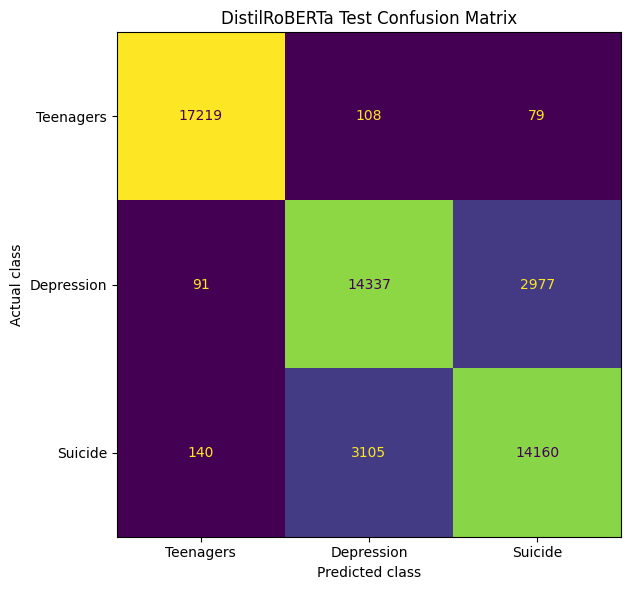

💾 Saving DistilRoBERTa results...
✅ Successfully saved to 'all_models_results_compare_v13.csv'

Saved files:
  Test probabilities:       roberta_probs_v13.npy
  Validation probabilities: roberta_val_probs_v13.npy
  Test labels:              y_test_truth_v13.npy
  Validation labels:        y_val_truth_v13.npy
  Comparison CSV updated.

DistilRoBERTa pipeline completed successfully.


In [24]:
# ============================================================
# ULTRA-LOW-MEMORY DISTILROBERTA
# Lazy training + chunked validation/test prediction
# ============================================================

# IMPORTANT:
# Run this entire cell after restarting the Jupyter kernel.
# Reload train_df, val_df, test_df and save_results_to_csv()
# before running it.

import os

# Must be set before model/tokenizer initialization
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import gc
import numpy as np
import pandas as pd
import torch
import sklearn.metrics
import matplotlib.pyplot as plt

from numpy.lib.format import open_memmap
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from simpletransformers.classification import (
    ClassificationModel,
    ClassificationArgs
)


# ============================================================
# 1. BASIC SETTINGS
# ============================================================

NUM_LABELS = 3
CLASS_LABELS = [0, 1, 2]
TARGET_NAMES = ["Teenagers", "Depression", "Suicide"]

RUN_DIR = "transformer_runs_v13/distilroberta"
TRAIN_TSV_PATH = os.path.join(RUN_DIR, "train_lazy_v13.tsv")

TEST_PROBS_PATH = "roberta_probs_v13.npy"
VAL_PROBS_PATH = "roberta_val_probs_v13.npy"

PREDICTION_CHUNK_SIZE = 500
USE_CUDA = torch.cuda.is_available()

os.makedirs(RUN_DIR, exist_ok=True)

print(f"CUDA available: {USE_CUDA}")

if USE_CUDA:
    print(f"GPU: {torch.cuda.get_device_name(0)}")


# ============================================================
# 2. DELETE OBJECTS LEFT BY PREVIOUS FAILED RUNS
# ============================================================

objects_to_delete = [
    "model",
    "model_outputs",
    "model_outputs_val",
    "wrong_predictions",
    "result",
    "result_val",
    "bert_train_df",
    "bert_val_df",
    "bert_eval_df",
    "roberta_test_probs",
    "roberta_val_probs"
]

for object_name in objects_to_delete:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if USE_CUDA:
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

torch.set_num_threads(1)


# ============================================================
# 3. VALIDATE THE CANONICAL DATA
# ============================================================

def validate_split(df, split_name):
    required_columns = {"text", "label"}

    missing_columns = required_columns.difference(df.columns)

    if missing_columns:
        raise ValueError(
            f"{split_name} is missing columns: {sorted(missing_columns)}"
        )

    if df["label"].isna().any():
        raise ValueError(f"{split_name} contains missing labels.")

    available_labels = set(
        df["label"].astype(np.int64).unique().tolist()
    )

    unexpected_labels = available_labels.difference(CLASS_LABELS)

    if unexpected_labels:
        raise ValueError(
            f"{split_name} contains unexpected labels: "
            f"{sorted(unexpected_labels)}"
        )


validate_split(train_df, "train_df")
validate_split(val_df, "val_df")
validate_split(test_df, "test_df")

print(
    f"Data ready: "
    f"{len(train_df):,} training, "
    f"{len(val_df):,} validation, "
    f"{len(test_df):,} test rows."
)


# ============================================================
# 4. WRITE MEMORY-SAFE LAZY-LOADING TSV
# ============================================================

def create_lazy_training_file(
    dataframe,
    output_path,
    rewrite=True
):
    """
    Writes:
        column 0 = text
        column 1 = label

    Internal tabs/newlines are removed because SimpleTransformers'
    lazy loader uses tab-delimited rows.
    """

    if os.path.exists(output_path) and not rewrite:
        print(f"Using existing lazy file: {output_path}")
        return

    print("Creating disk-based lazy training file...")

    with open(
        output_path,
        mode="w",
        encoding="utf-8",
        errors="replace",
        newline="",
        buffering=1024 * 1024
    ) as output_file:

        # lazy_loading_start_line=1 will skip this header
        output_file.write("text\tlabels\n")

        total_rows = len(dataframe)

        for row_number, (text, label) in enumerate(
            zip(dataframe["text"], dataframe["label"]),
            start=1
        ):
            if pd.isna(text):
                clean_text = ""
            else:
                clean_text = str(text)

            clean_text = (
                clean_text
                .replace("\t", " ")
                .replace("\r", " ")
                .replace("\n", " ")
                .replace("\x00", " ")
            )

            output_file.write(
                f"{clean_text}\t{int(label)}\n"
            )

            if row_number % 50000 == 0:
                print(
                    f"Written {row_number:,}/{total_rows:,} rows"
                )

    print(f"Lazy training file created: {output_path}")


# Change rewrite=False after the file has been created successfully once.
create_lazy_training_file(
    dataframe=train_df,
    output_path=TRAIN_TSV_PATH,
    rewrite=True
)

gc.collect()


# ============================================================
# 5. CONFIGURE DISTILROBERTA
# ============================================================

model_args = ClassificationArgs()

model_args.output_dir = os.path.join(RUN_DIR, "outputs")
model_args.best_model_dir = os.path.join(RUN_DIR, "best_model")
model_args.cache_dir = os.path.join(RUN_DIR, "cache")
model_args.tensorboard_dir = os.path.join(RUN_DIR, "tensorboard")

# ------------------------------------------------------------
# Disk-based lazy training
# ------------------------------------------------------------

model_args.lazy_loading = True
model_args.lazy_delimiter = "\t"
model_args.lazy_text_column = 0
model_args.lazy_labels_column = 1
model_args.lazy_loading_start_line = 1

# ------------------------------------------------------------
# Windows RAM protection
# ------------------------------------------------------------

model_args.use_multiprocessing = False
model_args.use_multiprocessing_for_evaluation = False
model_args.process_count = 1
model_args.dataloader_num_workers = 0

# ------------------------------------------------------------
# Training memory
# ------------------------------------------------------------

# Physical GPU batch
model_args.train_batch_size = 4

# Effective batch = 4 × 8 = 32
model_args.gradient_accumulation_steps = 8

model_args.eval_batch_size = 8
model_args.max_seq_length = 128

model_args.num_train_epochs = 1
model_args.learning_rate = 4e-5
model_args.warmup_ratio = 0.06
model_args.weight_decay = 0.01
model_args.manual_seed = 42

model_args.fp16 = USE_CUDA

# ------------------------------------------------------------
# Disable full validation during training
# ------------------------------------------------------------

model_args.evaluate_during_training = False
model_args.evaluate_each_epoch = False
model_args.save_best_model = False

# ------------------------------------------------------------
# Avoid unnecessary checkpoints and optimizer files
# ------------------------------------------------------------

model_args.overwrite_output_dir = True
model_args.save_eval_checkpoints = False
model_args.save_model_every_epoch = False
model_args.save_optimizer_and_scheduler = False

# Use a very large positive number rather than save_steps=-1
model_args.save_steps = 1_000_000_000

# The final trained model will still be saved by train_model()
model_args.no_save = False

model_args.no_cache = True
model_args.reprocess_input_data = True
model_args.use_cached_eval_features = False

model_args.logging_steps = 1000
model_args.silent = False
model_args.wandb_project = None


# ============================================================
# 6. INITIALIZE MODEL
# ============================================================

print("Initializing DistilRoBERTa...")

model = ClassificationModel(
    model_type="roberta",
    model_name="distilroberta-base",
    num_labels=NUM_LABELS,
    args=model_args,
    use_cuda=USE_CUDA
)


# ============================================================
# 6A. TOKENIZER COMPATIBILITY FIX
# ============================================================
# Some SimpleTransformers lazy-loading versions still call:
#     pad_to_max_length=...
# Newer Hugging Face Transformers versions require:
#     padding="max_length", truncation=True
# This patch keeps lazy loading and all later steps unchanged.

def patch_tokenizer_for_simpletransformers(
    tokenizer,
    max_length
):
    """
    Convert the obsolete pad_to_max_length argument into the
    current Hugging Face padding/truncation arguments.

    The patch is applied only to this tokenizer instance.
    """

    if getattr(tokenizer, "_st_padding_patch_applied", False):
        print("Tokenizer compatibility patch already applied.")
        return tokenizer

    original_encode_plus = tokenizer.encode_plus
    original_batch_encode_plus = tokenizer.batch_encode_plus

    def fixed_encode_plus(*args, **kwargs):
        legacy_padding = kwargs.pop("pad_to_max_length", None)

        if legacy_padding is not None:
            kwargs.setdefault(
                "padding",
                "max_length" if bool(legacy_padding) else False
            )

        if kwargs.get("max_length") is not None:
            kwargs.setdefault("truncation", True)
        else:
            kwargs.setdefault("max_length", max_length)
            kwargs.setdefault("truncation", True)

        return original_encode_plus(*args, **kwargs)

    def fixed_batch_encode_plus(*args, **kwargs):
        legacy_padding = kwargs.pop("pad_to_max_length", None)

        if legacy_padding is not None:
            kwargs.setdefault(
                "padding",
                "max_length" if bool(legacy_padding) else False
            )

        if kwargs.get("max_length") is not None:
            kwargs.setdefault("truncation", True)
        else:
            kwargs.setdefault("max_length", max_length)
            kwargs.setdefault("truncation", True)

        return original_batch_encode_plus(*args, **kwargs)

    tokenizer.encode_plus = fixed_encode_plus
    tokenizer.batch_encode_plus = fixed_batch_encode_plus
    tokenizer._st_padding_patch_applied = True

    return tokenizer


model.tokenizer = patch_tokenizer_for_simpletransformers(
    tokenizer=model.tokenizer,
    max_length=model_args.max_seq_length
)

# Confirm that the exact legacy call used by the lazy loader now works.
tokenizer_test = model.tokenizer.encode_plus(
    "Tokenizer compatibility test.",
    max_length=model_args.max_seq_length,
    pad_to_max_length=model_args.max_seq_length,
    return_tensors="pt"
)

if tokenizer_test["input_ids"].shape[1] != model_args.max_seq_length:
    raise RuntimeError(
        "Tokenizer patch test failed: unexpected sequence length."
    )

print(
    "Tokenizer fixed: padding='max_length', "
    "truncation=True, "
    f"max_length={model_args.max_seq_length}"
)

del tokenizer_test
gc.collect()

if USE_CUDA:
    torch.cuda.empty_cache()


# ============================================================
# 7. TRAIN USING THE FILE PATH
# ============================================================

print("Training DistilRoBERTa with lazy loading...")

try:
    global_step, training_details = model.train_model(
        TRAIN_TSV_PATH,
        show_running_loss=True
    )

    print(
        f"Training completed successfully. "
        f"Global steps: {global_step:,}"
    )

except TypeError as error:
    gc.collect()

    if USE_CUDA:
        torch.cuda.empty_cache()

    if "pad_to_max_length" in str(error):
        raise RuntimeError(
            "Tokenizer compatibility patch was not applied correctly. "
            "Restart the kernel and run this complete script from the top."
        ) from error

    raise

except MemoryError as error:
    gc.collect()

    if USE_CUDA:
        torch.cuda.empty_cache()

    raise MemoryError(
        "System RAM was exhausted during training. "
        "Restart the kernel and lower train_batch_size to 2."
    ) from error

except RuntimeError as error:
    gc.collect()

    if USE_CUDA:
        torch.cuda.empty_cache()

    if "out of memory" in str(error).lower():
        raise RuntimeError(
            "GPU memory was exhausted. Set train_batch_size=2 and "
            "gradient_accumulation_steps=16."
        ) from error

    raise


# ============================================================
# 8. LOW-MEMORY SOFTMAX
# ============================================================

def softmax_float32(logits):
    """
    Stable in-place softmax using float32.
    """

    logits = np.asarray(logits, dtype=np.float32)

    if logits.ndim != 2 or logits.shape[1] != NUM_LABELS:
        raise ValueError(
            f"Unexpected model output shape: {logits.shape}"
        )

    logits -= np.max(logits, axis=1, keepdims=True)
    np.exp(logits, out=logits)
    logits /= np.sum(logits, axis=1, keepdims=True)

    return logits


# ============================================================
# 9. CHUNKED PREDICTION + DISK-BACKED PROBABILITIES
# ============================================================

def predict_and_save_probabilities(
    trained_model,
    dataframe,
    probabilities_path,
    split_name,
    chunk_size=500
):
    """
    Predicts small groups of texts and writes probabilities
    directly into a disk-backed .npy file.

    It does not call eval_model() and does not create a large
    wrong_predictions object.
    """

    total_rows = len(dataframe)

    y_true = dataframe["label"].to_numpy(
        dtype=np.int64,
        copy=True
    )

    y_pred = np.empty(
        total_rows,
        dtype=np.int64
    )

    probabilities_memmap = open_memmap(
        probabilities_path,
        mode="w+",
        dtype=np.float32,
        shape=(total_rows, NUM_LABELS)
    )

    print(
        f"Scoring {split_name}: "
        f"{total_rows:,} rows in chunks of {chunk_size:,}"
    )

    for chunk_number, start in enumerate(
        range(0, total_rows, chunk_size),
        start=1
    ):
        end = min(start + chunk_size, total_rows)

        text_chunk = (
            dataframe["text"]
            .iloc[start:end]
            .fillna("")
            .astype(str)
            .tolist()
        )

        _, raw_outputs = trained_model.predict(text_chunk)

        probability_chunk = softmax_float32(raw_outputs)

        probabilities_memmap[start:end] = probability_chunk

        y_pred[start:end] = np.argmax(
            probability_chunk,
            axis=1
        ).astype(np.int64)

        del text_chunk
        del raw_outputs
        del probability_chunk

        # Periodic cleanup without slowing every chunk excessively
        if chunk_number % 10 == 0 or end == total_rows:
            probabilities_memmap.flush()
            gc.collect()

            if USE_CUDA:
                torch.cuda.empty_cache()

        print(
            f"\r{split_name}: "
            f"{end:,}/{total_rows:,} completed",
            end="",
            flush=True
        )

    print()

    probabilities_memmap.flush()
    del probabilities_memmap

    gc.collect()

    if USE_CUDA:
        torch.cuda.empty_cache()

    return y_true, y_pred


# ============================================================
# 10. VALIDATION PREDICTIONS
# ============================================================

print("\nValidation evaluation...")

y_true_val_roberta, y_pred_val_roberta = (
    predict_and_save_probabilities(
        trained_model=model,
        dataframe=val_df,
        probabilities_path=VAL_PROBS_PATH,
        split_name="Validation",
        chunk_size=PREDICTION_CHUNK_SIZE
    )
)

print("\nValidation classification report:")

print(
    classification_report(
        y_true_val_roberta,
        y_pred_val_roberta,
        labels=CLASS_LABELS,
        target_names=TARGET_NAMES,
        digits=4,
        zero_division=0
    )
)

np.save(
    "y_val_truth_v13.npy",
    y_true_val_roberta
)

# The hybrid section can use these as normal NumPy arrays,
# but the underlying data remains on disk.
roberta_val_probs = np.load(
    VAL_PROBS_PATH,
    mmap_mode="r"
)

print(
    f"Validation probabilities: "
    f"{roberta_val_probs.shape}"
)


# ============================================================
# 11. TEST PREDICTIONS
# ============================================================

print("\nTest evaluation...")

y_true_roberta, y_pred_roberta = (
    predict_and_save_probabilities(
        trained_model=model,
        dataframe=test_df,
        probabilities_path=TEST_PROBS_PATH,
        split_name="Test",
        chunk_size=PREDICTION_CHUNK_SIZE
    )
)

print("\nDistilRoBERTa test classification report:")

print(
    classification_report(
        y_true_roberta,
        y_pred_roberta,
        labels=CLASS_LABELS,
        target_names=TARGET_NAMES,
        digits=4,
        zero_division=0
    )
)

np.save(
    "y_test_truth_v13.npy",
    y_true_roberta
)

roberta_test_probs = np.load(
    TEST_PROBS_PATH,
    mmap_mode="r"
)

print(
    f"Test probabilities: "
    f"{roberta_test_probs.shape}"
)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm_roberta = confusion_matrix(
    y_true_roberta,
    y_pred_roberta,
    labels=CLASS_LABELS
)

fig, ax = plt.subplots(figsize=(8, 6))

matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_roberta,
    display_labels=TARGET_NAMES
)

matrix_display.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title("DistilRoBERTa Test Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()


# ============================================================
# 13. SAVE TEST RESULTS
# ============================================================

save_results_to_csv(
    "DistilRoBERTa",
    y_true_roberta,
    y_pred_roberta
)

print("\nSaved files:")
print(f"  Test probabilities:       {TEST_PROBS_PATH}")
print(f"  Validation probabilities: {VAL_PROBS_PATH}")
print("  Test labels:              y_test_truth_v13.npy")
print("  Validation labels:        y_val_truth_v13.npy")
print("  Comparison CSV updated.")

print("\nDistilRoBERTa pipeline completed successfully.")

In [25]:
# ============================================================
# DISTILROBERTA INFERENCE RESOURCE MEASUREMENT
# ============================================================

def predict_labels_in_chunks(
    trained_model,
    dataframe,
    chunk_size=500
):
    """
    Predicts labels in small chunks to avoid RAM MemoryError.
    Returns only the predicted labels.
    """

    total_samples = len(dataframe)
    all_predictions = np.empty(total_samples, dtype=np.int64)

    for start in range(0, total_samples, chunk_size):
        end = min(start + chunk_size, total_samples)

        text_chunk = (
            dataframe["text"]
            .iloc[start:end]
            .fillna("")
            .astype(str)
            .tolist()
        )

        chunk_predictions, chunk_outputs = trained_model.predict(
            text_chunk
        )

        all_predictions[start:end] = np.asarray(
            chunk_predictions,
            dtype=np.int64
        )

        print(
            f"\rInference completed: {end:,}/{total_samples:,}",
            end="",
            flush=True
        )

        del text_chunk
        del chunk_predictions
        del chunk_outputs

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print()

    return all_predictions


# Measure and save DistilRoBERTa inference results
distilroberta_inference_results = measure_inference(
    model_name="DistilRoBERTa",

    prediction_function=lambda: predict_labels_in_chunks(
        trained_model=model,
        dataframe=test_df,
        chunk_size=500
    ),

    sample_count=len(test_df),

    csv_path="inference_resource_log_v13.csv"
)

INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Predicting:   0%|          | 0/63 [00:00<?, ?it/s]

Inference completed: 500/52,216

INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


...

Inference completed: 52,000/52,216

INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


Map:   0%|          | 0/216 [00:00<?, ? examples/s]

Predicting:   0%|          | 0/27 [00:00<?, ?it/s]

Inference completed: 52,216/52,216

DistilRoBERTa inference results
Samples:                52,216
Total inference time:   201.5017 seconds
Latency per sample:     3.8590 ms
Throughput:             259.13 samples/s
CPU time:               193.4844 seconds
CPU utilization:        6.00%
Additional RAM used:    5.48 MB
Peak process RAM:       1389.23 MB
Peak PyTorch GPU RAM:   1085.87 MB
Saved to:               inference_resource_log_v13.csv


In [26]:
inference_results_df = pd.read_csv(
    "inference_resource_log_v13.csv"
)

print(inference_results_df.tail())

                Model  N_Samples  Total_Inference_Time_s  \
0           SGD_TFIDF      52216                  0.0185   
1  Hierarchical_TFIDF      52216                  0.3696   
2            LightGBM      52216                  0.4883   
3          DistilBERT      52216                172.4300   
4       DistilRoBERTa      52216                201.5017   

   Latency_ms_per_sample  Throughput_samples_per_s  CPU_Time_s  CPU_Percent  \
0                 0.0004                2816427.36      0.0156        29.40   
1                 0.0071                 141281.57      4.0156        68.60   
2                 0.0094                 106926.53      4.9688        90.50   
3                 3.3022                    302.82    162.3750         5.89   
4                 3.8590                    259.13    193.4844         6.00   

   RAM_Used_MB  RAM_Peak_MB  GPU_Peak_MB  
0         0.00      2612.98         0.00  
1         1.93      2613.09         0.00  
2        97.02       725.39        

In [27]:
roberta_model_saved = model
print("✅ roberta_model_saved is ready.")

✅ roberta_model_saved is ready.


In [ ]:
!pip install tensorflow
!pip install tensorflow_hub

📥 Loading canonical split (train_split_v13.csv / val_split_v13.csv / test_split_v13.csv)...
✅ Loaded split: train=243673, val=52216, test=52216
⚙️ Loading GUSE from local folder...




INFO:absl:Fingerprint not found. Saved model loading will continue.
INFO:absl:path_and_singleprint metric could not be logged. Saved model loading will continue.


🏗️ Building Dense Network (Keras 3 Compatible)...



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

🚀 Training GUSE-Dense Network...
Epoch 1/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 256s 33ms/step - accuracy: 0.7869 - loss: 0.5055 - val_accuracy: 0.8030 - val_loss: 0.4676
Epoch 2/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 260s 34ms/step - accuracy: 0.7975 - loss: 0.4805 - val_accuracy: 0.8045 - val_loss: 0.4636
Epoch 3/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 264s 35ms/step - accuracy: 0.8003 - loss: 0.4728 - val_accuracy: 0.8080 - val_loss: 0.4588
Epoch 4/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 258s 34ms/step - accuracy: 0.8034 - loss: 0.4660 - val_accuracy: 0.8086 - val_loss: 0.4562
Epoch 5/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 257s 34ms/step - accuracy: 0.8061 - loss: 0.4607 - val_accuracy: 0.8100 - val_loss: 0.4544
Epoch 6/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 253s 33ms/step - accuracy: 0.8076 - loss: 0.4555 - val_accuracy: 0.8093 - val_loss: 0.4551
Epoch 7/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 268s 35ms/step - accuracy: 0.8095 - loss: 0.4521 - val_accuracy: 0.8109 - val_loss: 0.4531
Epoch 8/10
7615/7615 ━━━━━━━━━━━━━━━

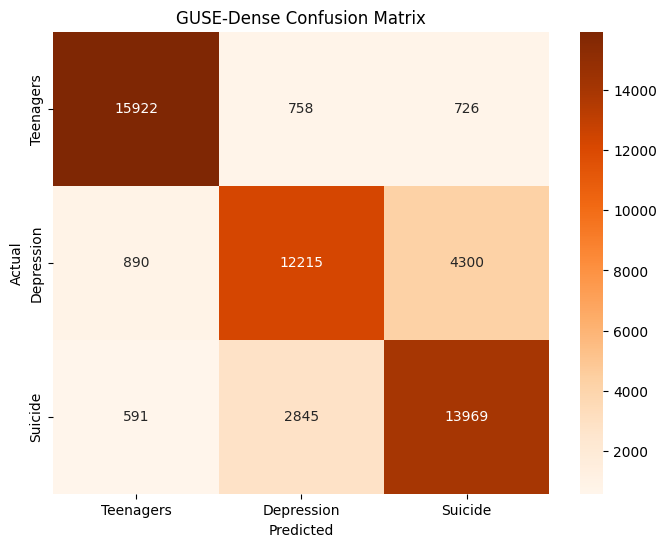

💾 Saving GUSE_Dense results...
✅ Successfully saved to 'all_models_results_compare_v13.csv'


In [28]:
import tensorflow as tf
import tensorflow_hub as hub
import pandas as pd
import numpy as np
import gc
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. LOAD THE CANONICAL TRAIN/VAL/TEST SPLIT
# ==========================================
print("📥 Loading canonical split (train_split_v13.csv / val_split_v13.csv / test_split_v13.csv)...")

X_train_raw = train_df['text'].values
y_train     = train_df['label'].values
X_val_raw   = val_df['text'].values
y_val       = val_df['label'].values
X_test_raw  = test_df['text'].values
y_test      = test_df['label'].values

y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=3)
y_val_cat   = tf.keras.utils.to_categorical(y_val,   num_classes=3)
y_test_cat  = tf.keras.utils.to_categorical(y_test,  num_classes=3)

print(f"✅ Loaded split: train={len(X_train_raw)}, val={len(X_val_raw)}, test={len(X_test_raw)}")

# ==========================================
# 2. LOAD LOCAL GUSE MODEL (THE FIX)
# ==========================================
print("⚙️ Loading GUSE from local folder...")

local_model_path = "./module_useT"

# 🔥 FIX 1: Load the raw object instead of KerasLayer
try:
    embed = hub.load(local_model_path)
except Exception:
    print("⚠️ Local model not found. Downloading from TFHub...")
    embed = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")

print("🏗️ Building Dense Network (Keras 3 Compatible)...")

# 🔥 FIX 2: Use an Input layer + Lambda wrapper
# This bypasses the "incompatible layer" error
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=[], dtype=tf.string),     # Explicit Input
    tf.keras.layers.Lambda(lambda x: embed(x)),           # Wrapper
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# ==========================================
# 3. TRAIN
# ==========================================
print("🚀 Training GUSE-Dense Network...")

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=2, 
    restore_best_weights=True
)

history = model.fit(
    X_train_raw, y_train_cat,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_raw, y_val_cat),  # ← explicit val set replaces validation_split
    callbacks=[early_stop]
)

# ==========================================
# 4. EVALUATE
# ==========================================
print("🏆 Evaluating GUSE Model...")

y_prob = model.predict(X_test_raw)
y_pred = np.argmax(y_prob, axis=1)

target_names = ['Teenagers', 'Depression', 'Suicide']
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=target_names, yticklabels=target_names)
plt.title('GUSE-Dense Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ── Log this model's TEST predictions to the shared comparison CSV ──
save_results_to_csv("GUSE_Dense", y_test, y_pred)

In [31]:
inference_results_df= measure_inference("GUSE_Dense", lambda: model.predict(X_test_raw), len(X_test_raw))

1632/1632 ━━━━━━━━━━━━━━━━━━━━ 45s 27ms/step

GUSE_Dense inference results
Samples:                52,216
Total inference time:   45.0578 seconds
Latency per sample:     0.8629 ms
Throughput:             1158.87 samples/s
CPU time:               94.8438 seconds
CPU utilization:        13.16%
Additional RAM used:    0.14 MB
Peak process RAM:       3244.96 MB
Peak PyTorch GPU RAM:   963.77 MB
Saved to:               inference_results.csv


🏆 Evaluating GUSE Model...

GUSE_Dense inference results
Samples:                52,216
Total inference time:   45.7547 seconds
Latency per sample:     0.8763 ms
Throughput:             1141.22 samples/s
CPU time:               88.4844 seconds
CPU utilization:        12.09%
Additional RAM used:    0.00 MB
Peak process RAM:       2372.89 MB
Peak PyTorch GPU RAM:   963.77 MB
Saved to:               inference_resource_log_v13.csv

GUSE-Dense Classification Report:
              precision    recall  f1-score   support

   Teenagers     0.9149    0.9147    0.9148     17406
  Depression     0.7722    0.7018    0.7353     17405
     Suicide     0.7354    0.8026    0.7675     17405

    accuracy                         0.8064     52216
   macro avg     0.8075    0.8064    0.8059     52216
weighted avg     0.8075    0.8064    0.8059     52216



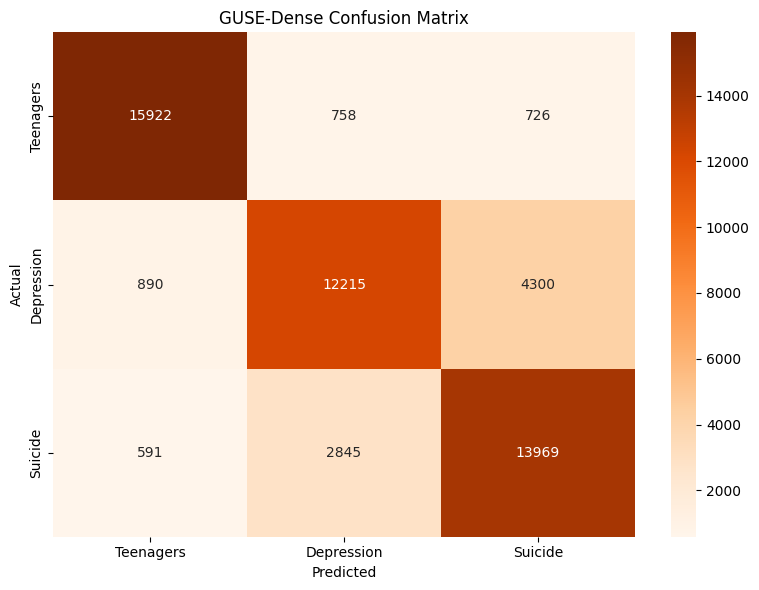

💾 Saving GUSE_Dense results...
✅ Successfully saved to 'all_models_results_compare_v13.csv'
✅ GUSE-Dense classification and inference results saved successfully.

Latest inference-resource results:
           Model  N_Samples  Total_Inference_Time_s  Latency_ms_per_sample  \
2       LightGBM    52216.0                  0.4883                 0.0094   
3     DistilBERT    52216.0                172.4300                 3.3022   
4  DistilRoBERTa    52216.0                201.5017                 3.8590   
5            NaN        NaN                     NaN                    NaN   
6     GUSE_Dense    52216.0                 45.7547                 0.8763   

   Throughput_samples_per_s  CPU_Time_s  CPU_Percent  RAM_Used_MB  \
2                 106926.53      4.9688        90.50        97.02   
3                    302.82    162.3750         5.89         4.54   
4                    259.13    193.4844         6.00         5.48   
5                       NaN         NaN          NaN     

In [35]:
# ==========================================
# 4. EVALUATE + MEASURE INFERENCE RESOURCES
# ==========================================
print("🏆 Evaluating GUSE Model...")

# measure_inference() returns a dictionary containing:
# - inference timing/resource measurements
# - predictions produced by model.predict()
guse_inference_results = measure_inference(
    model_name="GUSE_Dense",

    prediction_function=lambda: model.predict(
        X_test_raw,
        batch_size=32,
        verbose=0
    ),

    sample_count=len(X_test_raw),

    # Save to the shared inference-resource CSV
    csv_path="inference_resource_log_v13.csv"
)

# Retrieve probability predictions generated during measurement
y_prob = guse_inference_results["predictions"]

# Convert probabilities into class predictions
y_pred = np.argmax(y_prob, axis=1)

# ==========================================
# 5. CLASSIFICATION REPORT
# ==========================================
target_names = [
    "Teenagers",
    "Depression",
    "Suicide"
]

print("\nGUSE-Dense Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)

# ==========================================
# 6. CONFUSION MATRIX
# ==========================================
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.title("GUSE-Dense Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

# ==========================================
# 7. SAVE CLASSIFICATION RESULTS
# ==========================================
save_results_to_csv(
    "GUSE_Dense",
    y_test,
    y_pred
)

print(
    "✅ GUSE-Dense classification and inference "
    "results saved successfully."
)

# ==========================================
# 8. VERIFY INFERENCE CSV
# ==========================================
inference_results_df = pd.read_csv(
    "inference_resource_log_v13.csv"
)

print("\nLatest inference-resource results:")
print(inference_results_df.tail())

## 🔗 Hybrid Fusion — Validated, Leak-Free Pipeline

The cells below replace every earlier hybrid/ensemble attempt in this notebook. Two problems were fixed:

1. **Test-set leakage.** Earlier cells searched for the best fusion weight α directly against the test set, then reported that same test set's score. That inflates the result and isn't defensible. Here, α is selected using **only the validation set**; the test set is scored **exactly once**, with that fixed α.
2. **A hardcoded results cell.** One cell manually typed in `Accuracy: 0.88, F1: 0.88, ...` as a Python dict — those numbers were never computed from anything in the notebook. That cell has been removed. Every number below is computed live from `roberta_probs_v13.npy` / `lgbm_probs_v13.npy` and their validation-set counterparts, which are saved automatically by the LightGBM and DistilRoBERTa cells above.

**Run order:** LightGBM cell → DistilRoBERTa cell → the cells below, in order.


In [36]:
import numpy as np

# ── Load probabilities produced by the LightGBM cell and the DistilRoBERTa cell ──
# (Run those cells first — this cell just loads what they saved to disk.)
roberta_test_probs = np.load("roberta_probs_v13.npy")
roberta_val_probs  = np.load("roberta_val_probs_v13.npy")
lgbm_test_probs    = np.load("lgbm_probs_v13.npy")
lgbm_val_probs     = np.load("lgbm_val_probs_v13.npy")

y_test_truth = np.load("y_test_truth_v13.npy")
y_val_truth  = np.load("y_val_truth_v13.npy")

assert roberta_val_probs.shape[0] == lgbm_val_probs.shape[0] == y_val_truth.shape[0], \
    "Validation set sizes don't match between models — re-run the training cells so " \
    "LightGBM and DistilRoBERTa use the exact same split (random_state=42, 70/15/15)."
assert roberta_test_probs.shape[0] == lgbm_test_probs.shape[0] == y_test_truth.shape[0], \
    "Test set sizes don't match between models — re-run the training cells so " \
    "LightGBM and DistilRoBERTa use the exact same split (random_state=42, 70/15/15)."

print(f"Validation set: {len(y_val_truth)} rows | Test set: {len(y_test_truth)} rows")


Validation set: 52216 rows | Test set: 52216 rows


In [37]:
import json
import numpy as np
import pandas as pd
from sklearn.metrics import recall_score, accuracy_score, f1_score

# ── Select the fusion weight alpha using ONLY the validation set ──
# alpha never sees the test set here — this is what makes the test-set
# number reported later defensible instead of leakage-inflated.
alpha_grid = np.arange(0.0, 1.001, 0.02)
val_results = []
for a in alpha_grid:
    probs = (a * roberta_val_probs) + ((1 - a) * lgbm_val_probs)
    preds = np.argmax(probs, axis=1)
    val_results.append({
        "alpha": round(float(a), 2),
        "val_suicide_recall": recall_score(y_val_truth, preds, average=None)[2],
        "val_accuracy": accuracy_score(y_val_truth, preds),
        "val_f1_weighted": f1_score(y_val_truth, preds, average="weighted"),
    })

df_val = pd.DataFrame(val_results)

# Selection rule: maximize Suicide recall (the safety-critical class) on the
# validation set; ties broken by weighted F1. If your thesis defines a
# different selection criterion (e.g. best F1, or a recall/precision
# balance), change the sort key below — just keep the selection on the
# VALIDATION set, never the test set.
df_val_sorted = df_val.sort_values(["val_suicide_recall", "val_f1_weighted"], ascending=False)
best_alpha = float(df_val_sorted.iloc[0]["alpha"])

print(df_val.to_string(index=False))
print(f"\n🏆 Selected alpha = {best_alpha:.2f} (chosen on the VALIDATION set only)")

# Persist so every later cell/figure in this notebook uses this exact value —
# a single source of truth instead of five different hardcoded numbers.
with open("hybrid_alpha_config_v13.json", "w") as f:
    json.dump({"best_alpha": best_alpha, "selection_metric": "val_suicide_recall"}, f, indent=2)
df_val.to_csv("alpha_sensitivity_validation_v13.csv", index=False)
print("✅ Saved hybrid_alpha_config_v13.json and alpha_sensitivity_validation_v13.csv")


 alpha  val_suicide_recall  val_accuracy  val_f1_weighted
  0.00            0.752887      0.795082         0.793467
  0.02            0.755702      0.798587         0.796976
  0.04            0.758690      0.801632         0.800031
  0.06            0.761620      0.804868         0.803295
  0.08            0.765182      0.808181         0.806622
  0.10            0.768342      0.811456         0.809916
  0.12            0.770813      0.814597         0.813047
  0.14            0.773513      0.817508         0.815990
  0.16            0.776156      0.820917         0.819376
  0.18            0.779948      0.824786         0.823308
  0.20            0.782878      0.828022         0.826553
  0.22            0.786785      0.832082         0.830672
  0.24            0.790060      0.835683         0.834293
  0.26            0.793278      0.839532         0.838189
  0.28            0.795921      0.843037         0.841713
  0.30            0.799425      0.846484         0.845191
  0.32        

In [38]:
# ── Does the Hybrid actually help, or is RoBERTa alone enough? ──
# Compare against pure RoBERTa (alpha=1.0) directly on the TEST set
probs_hybrid  = (best_alpha * roberta_test_probs) + ((1 - best_alpha) * lgbm_test_probs)
probs_roberta = roberta_test_probs  # equivalent to alpha=1.0

preds_hybrid  = np.argmax(probs_hybrid, axis=1)
preds_roberta = np.argmax(probs_roberta, axis=1)

print("=== Pure DistilRoBERTa (Test) ===")
print(classification_report(y_test_truth, preds_roberta, target_names=target_names))

print("\n=== Hybrid (alpha={:.2f}, Test) ===".format(best_alpha))
print(classification_report(y_test_truth, preds_hybrid, target_names=target_names))

print(f"\nSuicide recall — RoBERTa: {recall_score(y_test_truth, preds_roberta, average=None)[2]:.4f}")
print(f"Suicide recall — Hybrid:  {recall_score(y_test_truth, preds_hybrid, average=None)[2]:.4f}")

=== Pure DistilRoBERTa (Test) ===
              precision    recall  f1-score   support

   Teenagers       0.99      0.99      0.99     17406
  Depression       0.82      0.82      0.82     17405
     Suicide       0.82      0.81      0.82     17405

    accuracy                           0.88     52216
   macro avg       0.88      0.88      0.88     52216
weighted avg       0.88      0.88      0.88     52216


=== Hybrid (alpha=0.56, Test) ===
              precision    recall  f1-score   support

   Teenagers       0.98      0.99      0.99     17406
  Depression       0.83      0.82      0.83     17405
     Suicide       0.82      0.83      0.83     17405

    accuracy                           0.88     52216
   macro avg       0.88      0.88      0.88     52216
weighted avg       0.88      0.88      0.88     52216


Suicide recall — RoBERTa: 0.8136
Suicide recall — Hybrid:  0.8295


In [39]:
from sklearn.linear_model import LogisticRegression

# Stack: concatenate both models' class probabilities as meta-features
X_meta_val  = np.hstack([roberta_val_probs, lgbm_val_probs])
X_meta_test = np.hstack([roberta_test_probs, lgbm_test_probs])

meta_model = LogisticRegression(max_iter=1000, class_weight='balanced')
meta_model.fit(X_meta_val, y_val_truth)

preds_stacked = meta_model.predict(X_meta_test)
print("=== Stacked Meta-Model (Test) ===")
print(classification_report(y_test_truth, preds_stacked, target_names=target_names))

=== Stacked Meta-Model (Test) ===
              precision    recall  f1-score   support

   Teenagers       0.99      0.99      0.99     17406
  Depression       0.83      0.82      0.83     17405
     Suicide       0.82      0.83      0.83     17405

    accuracy                           0.88     52216
   macro avg       0.88      0.88      0.88     52216
weighted avg       0.88      0.88      0.88     52216



In [46]:
# ═══════════════════════════════════════════════════════════════
# Improved Hybrid:
# Calibrated LightGBM + Global and Per-Class Alpha Search
# ═══════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import sklearn

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    recall_score,
    accuracy_score,
    f1_score,
    classification_report
)

target_names = [
    "Teenagers",
    "Depression",
    "Suicide"
]

class_labels = [0, 1, 2]


# ═══════════════════════════════════════════════════════════════
# STEP 0: USE THE EXPLICITLY SAVED LIGHTGBM MODEL
# ═══════════════════════════════════════════════════════════════

# This hybrid block expects the fitted LightGBM classifier to have
# been preserved immediately after training as `lgbm_model_saved`.
# It deliberately does not use the generic variable `model`, because
# that variable may later refer to GUSE, DistilBERT, or DistilRoBERTa.
if "lgbm_model_saved" not in globals():
    raise NameError(
        "lgbm_model_saved is not defined. Run the LightGBM training "
        "cell that creates and fits lgbm_model_saved before this block."
    )

lgbm_model = lgbm_model_saved

if not hasattr(lgbm_model, "classes_"):
    raise RuntimeError(
        "lgbm_model_saved exists, but it does not appear to be fitted."
    )

print(
    "✅ Using saved LightGBM model: "
    f"lgbm_model_saved ({type(lgbm_model).__name__})"
)


# ═══════════════════════════════════════════════════════════════
# STEP 0A: USE OR RECREATE VALIDATION/TEST TF-IDF MATRICES
# ═══════════════════════════════════════════════════════════════

# Prefer the exact matrices used by the LightGBM pipeline. This is the
# safest option because they are guaranteed to use the same vocabulary
# and feature ordering as X_train_vec.
feature_matrices_available = (
    "X_val_vec" in globals()
    and "X_test_vec" in globals()
)

if feature_matrices_available:
    print("✅ Using existing X_val_vec and X_test_vec.")

else:
    print(
        "⚠️ X_val_vec or X_test_vec is missing. "
        "Attempting to recreate them with the fitted TF-IDF vectorizer..."
    )

    possible_vectorizer_names = [
        "tfidf_vectorizer",
        "vectorizer",
        "tfidf",
        "word_tfidf",
        "tfidf_word",
        "text_vectorizer",
        "lgbm_vectorizer"
    ]

    fitted_vectorizer = None
    fitted_vectorizer_name = None

    for variable_name in possible_vectorizer_names:
        if variable_name in globals():
            candidate = globals()[variable_name]

            if (
                hasattr(candidate, "transform")
                and hasattr(candidate, "vocabulary_")
            ):
                fitted_vectorizer = candidate
                fitted_vectorizer_name = variable_name
                break

    if fitted_vectorizer is None:
        raise NameError(
            "X_val_vec/X_test_vec are missing and no fitted TF-IDF "
            "vectorizer was found. Run the TF-IDF/LightGBM feature "
            "creation cell first. Do not fit a new vectorizer on "
            "validation or test data."
        )

    val_texts = val_df["text"].fillna("").astype(str)
    test_texts = test_df["text"].fillna("").astype(str)

    # transform(), never fit_transform(), prevents data leakage.
    X_val_vec = fitted_vectorizer.transform(val_texts)
    X_test_vec = fitted_vectorizer.transform(test_texts)

    print(
        f"✅ Recreated feature matrices with {fitted_vectorizer_name}."
    )


# Use canonical dataframe labels so row order stays aligned with the
# canonical validation and test splits.
y_val_truth = val_df["label"].to_numpy(
    dtype=np.int64,
    copy=True
)

y_test_truth = test_df["label"].to_numpy(
    dtype=np.int64,
    copy=True
)


# Validate row alignment.
if X_val_vec.shape[0] != len(y_val_truth):
    raise ValueError(
        "Validation row mismatch: "
        f"X_val_vec has {X_val_vec.shape[0]:,} rows, but "
        f"y_val_truth has {len(y_val_truth):,} labels."
    )

if X_test_vec.shape[0] != len(y_test_truth):
    raise ValueError(
        "Test row mismatch: "
        f"X_test_vec has {X_test_vec.shape[0]:,} rows, but "
        f"y_test_truth has {len(y_test_truth):,} labels."
    )


# Validate that validation/test features match the fitted LightGBM model.
if hasattr(lgbm_model, "n_features_in_"):
    expected_features = int(lgbm_model.n_features_in_)

    if X_val_vec.shape[1] != expected_features:
        raise ValueError(
            "Feature mismatch: lgbm_model_saved expects "
            f"{expected_features:,} features, but X_val_vec has "
            f"{X_val_vec.shape[1]:,}. Use the same fitted TF-IDF "
            "vectorizer that created X_train_vec."
        )

    if X_test_vec.shape[1] != expected_features:
        raise ValueError(
            "Feature mismatch: lgbm_model_saved expects "
            f"{expected_features:,} features, but X_test_vec has "
            f"{X_test_vec.shape[1]:,}. Use the same fitted TF-IDF "
            "vectorizer that created X_train_vec."
        )

print(f"✅ Validation features: {X_val_vec.shape}")
print(f"✅ Test features:       {X_test_vec.shape}")
print(f"✅ Validation labels:   {y_val_truth.shape}")
print(f"✅ Test labels:         {y_test_truth.shape}")


# ═══════════════════════════════════════════════════════════════
# STEP 0B: LOAD ROBERTA PROBABILITIES
# ═══════════════════════════════════════════════════════════════

if "roberta_val_probs" not in globals():
    roberta_val_probs = np.load(
        "roberta_val_probs_v13.npy",
        mmap_mode="r"
    )

if "roberta_test_probs" not in globals():
    roberta_test_probs = np.load(
        "roberta_probs_v13.npy",
        mmap_mode="r"
    )

roberta_val_probs = np.asarray(
    roberta_val_probs,
    dtype=np.float32
)

roberta_test_probs = np.asarray(
    roberta_test_probs,
    dtype=np.float32
)


# Check row alignment
if len(roberta_val_probs) != len(y_val_truth):
    raise ValueError(
        "RoBERTa validation probability count does not match "
        "the validation labels."
    )

if len(roberta_test_probs) != len(y_test_truth):
    raise ValueError(
        "RoBERTa test probability count does not match "
        "the test labels."
    )

if roberta_val_probs.shape[1] != 3:
    raise ValueError(
        "Expected three RoBERTa probability columns."
    )

print(
    f"RoBERTa validation probabilities: "
    f"{roberta_val_probs.shape}"
)

print(
    f"RoBERTa test probabilities: "
    f"{roberta_test_probs.shape}"
)


# ═══════════════════════════════════════════════════════════════
# STEP 1: GET UNCALIBRATED LIGHTGBM PROBABILITIES
# ═══════════════════════════════════════════════════════════════

print("\n⚙️ Generating original LightGBM probabilities...")

lgbm_val_probs = lgbm_model.predict_proba(X_val_vec)
lgbm_test_probs = lgbm_model.predict_proba(X_test_vec)

lgbm_val_probs = np.asarray(
    lgbm_val_probs,
    dtype=np.float32
)

lgbm_test_probs = np.asarray(
    lgbm_test_probs,
    dtype=np.float32
)


# ═══════════════════════════════════════════════════════════════
# STEP 2: CALIBRATE LIGHTGBM
# ═══════════════════════════════════════════════════════════════

print("\n⚙️ Calibrating LightGBM probabilities...")

# Current scikit-learn versions use FrozenEstimator for
# calibrating an already-fitted estimator.
try:
    from sklearn.frozen import FrozenEstimator

    calibrated_lgbm = CalibratedClassifierCV(
        estimator=FrozenEstimator(lgbm_model),
        method="isotonic"
    )

except ImportError:
    # Compatibility with older scikit-learn versions
    calibrated_lgbm = CalibratedClassifierCV(
        estimator=lgbm_model,
        method="isotonic",
        cv="prefit"
    )


calibrated_lgbm.fit(
    X_val_vec,
    y_val_truth
)

lgbm_val_probs_cal = calibrated_lgbm.predict_proba(
    X_val_vec
)

lgbm_test_probs_cal = calibrated_lgbm.predict_proba(
    X_test_vec
)

lgbm_val_probs_cal = np.asarray(
    lgbm_val_probs_cal,
    dtype=np.float32
)

lgbm_test_probs_cal = np.asarray(
    lgbm_test_probs_cal,
    dtype=np.float32
)

print("✅ LightGBM calibration completed.")


# ═══════════════════════════════════════════════════════════════
# STEP 3: SEARCH GLOBAL ALPHA
# ═══════════════════════════════════════════════════════════════

print("\n🔍 Searching global alpha on validation data...")

alpha_grid = np.arange(
    0.0,
    1.01,
    0.05
)

best_alpha = 0.0
best_global_macro_f1 = -1.0

for alpha in alpha_grid:

    blended_probabilities = (
        alpha * roberta_val_probs
        + (1.0 - alpha) * lgbm_val_probs
    )

    predictions = np.argmax(
        blended_probabilities,
        axis=1
    )

    score = f1_score(
        y_val_truth,
        predictions,
        average="macro"
    )

    if score > best_global_macro_f1:
        best_global_macro_f1 = score
        best_alpha = float(alpha)

print(
    f"Best global alpha: {best_alpha:.2f} | "
    f"Validation macro-F1: {best_global_macro_f1:.4f}"
)


# ═══════════════════════════════════════════════════════════════
# STEP 4: PER-CLASS ALPHA SEARCH
# ═══════════════════════════════════════════════════════════════

def build_per_class_probs(
    roberta_probs,
    lightgbm_probs,
    alphas
):
    """
    Blends each class using its own RoBERTa weight.
    """

    output = np.empty_like(
        roberta_probs,
        dtype=np.float32
    )

    for class_index in range(3):
        output[:, class_index] = (
            alphas[class_index]
            * roberta_probs[:, class_index]
            + (
                1.0 - alphas[class_index]
            )
            * lightgbm_probs[:, class_index]
        )

    # Different class-specific weights can cause rows not to
    # sum to exactly 1. Renormalization keeps valid probabilities.
    row_sums = output.sum(
        axis=1,
        keepdims=True
    )

    output = np.divide(
        output,
        row_sums,
        out=np.zeros_like(output),
        where=row_sums != 0
    )

    return output


print("\n🔍 Searching per-class alpha weights...")

# Start from the best global alpha
best_alphas = np.full(
    3,
    best_alpha,
    dtype=np.float32
)

# Coordinate search:
# optimize one class at a time while retaining the current
# weights for the other classes.
for search_round in range(3):

    for class_index in range(3):

        best_class_alpha = best_alphas[class_index]
        best_class_score = -1.0
        best_suicide_recall = -1.0

        for alpha in alpha_grid:

            candidate_alphas = best_alphas.copy()
            candidate_alphas[class_index] = alpha

            candidate_probs = build_per_class_probs(
                roberta_val_probs,
                lgbm_val_probs_cal,
                candidate_alphas
            )

            candidate_predictions = np.argmax(
                candidate_probs,
                axis=1
            )

            macro_f1 = f1_score(
                y_val_truth,
                candidate_predictions,
                average="macro"
            )

            class_recalls = recall_score(
                y_val_truth,
                candidate_predictions,
                labels=class_labels,
                average=None,
                zero_division=0
            )

            suicide_recall = class_recalls[2]

            # Primary target: macro-F1
            # Tie-breaker: suicide recall
            if (
                macro_f1 > best_class_score
                or (
                    np.isclose(
                        macro_f1,
                        best_class_score
                    )
                    and suicide_recall
                    > best_suicide_recall
                )
            ):
                best_class_score = macro_f1
                best_suicide_recall = suicide_recall
                best_class_alpha = float(alpha)

        best_alphas[class_index] = best_class_alpha


print(
    "Per-class alphas:\n"
    f"  Teenagers: {best_alphas[0]:.2f}\n"
    f"  Depression: {best_alphas[1]:.2f}\n"
    f"  Suicide:   {best_alphas[2]:.2f}"
)


# ═══════════════════════════════════════════════════════════════
# STEP 5: BUILD PER-CLASS HYBRID PROBABILITIES
# ═══════════════════════════════════════════════════════════════

val_probs_v2 = build_per_class_probs(
    roberta_val_probs,
    lgbm_val_probs_cal,
    best_alphas
)

test_probs_v2 = build_per_class_probs(
    roberta_test_probs,
    lgbm_test_probs_cal,
    best_alphas
)

preds_val_v2 = np.argmax(
    val_probs_v2,
    axis=1
)

preds_test_v2 = np.argmax(
    test_probs_v2,
    axis=1
)


# ═══════════════════════════════════════════════════════════════
# STEP 6: COMPARE CANDIDATES ON VALIDATION DATA
# ═══════════════════════════════════════════════════════════════

global_val_probs = (
    best_alpha * roberta_val_probs
    + (1.0 - best_alpha) * lgbm_val_probs
)

candidates = {
    "RoBERTa_only": np.argmax(
        roberta_val_probs,
        axis=1
    ),

    "LightGBM_only": np.argmax(
        lgbm_val_probs,
        axis=1
    ),

    "Calibrated_LightGBM_only": np.argmax(
        lgbm_val_probs_cal,
        axis=1
    ),

    "Global_Alpha_Hybrid": np.argmax(
        global_val_probs,
        axis=1
    ),

    "PerClass_Calibrated_Hybrid": preds_val_v2
}


print(
    "\n📊 VALIDATION comparison "
    "(test set not used for selection):"
)

summary = []

for candidate_name, candidate_predictions in candidates.items():

    class_recalls = recall_score(
        y_val_truth,
        candidate_predictions,
        labels=class_labels,
        average=None,
        zero_division=0
    )

    summary.append({
        "Model": candidate_name,

        "Val_Accuracy": accuracy_score(
            y_val_truth,
            candidate_predictions
        ),

        "Val_MacroF1": f1_score(
            y_val_truth,
            candidate_predictions,
            average="macro"
        ),

        "Val_Suicide_Recall": class_recalls[2]
    })


df_summary = pd.DataFrame(summary)

df_summary = df_summary.sort_values(
    by=[
        "Val_MacroF1",
        "Val_Suicide_Recall"
    ],
    ascending=[
        False,
        False
    ]
).reset_index(drop=True)

print(
    df_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)

winner = df_summary.loc[0, "Model"]

print(f"\n🏆 Best model on validation: {winner}")


# ═══════════════════════════════════════════════════════════════
# STEP 7: APPLY SELECTED MODEL TO TEST SET
# ═══════════════════════════════════════════════════════════════

global_test_probs = (
    best_alpha * roberta_test_probs
    + (1.0 - best_alpha) * lgbm_test_probs
)

test_predictions_map = {
    "RoBERTa_only": np.argmax(
        roberta_test_probs,
        axis=1
    ),

    "LightGBM_only": np.argmax(
        lgbm_test_probs,
        axis=1
    ),

    "Calibrated_LightGBM_only": np.argmax(
        lgbm_test_probs_cal,
        axis=1
    ),

    "Global_Alpha_Hybrid": np.argmax(
        global_test_probs,
        axis=1
    ),

    "PerClass_Calibrated_Hybrid": preds_test_v2
}

final_test_preds = test_predictions_map[winner]


print(
    f"\n{'=' * 65}\n"
    f"FINAL TEST RESULTS: {winner}\n"
    f"{'=' * 65}"
)

print(
    classification_report(
        y_test_truth,
        final_test_preds,
        labels=class_labels,
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)


# ═══════════════════════════════════════════════════════════════
# STEP 8: SAVE FINAL TEST RESULTS
# ═══════════════════════════════════════════════════════════════

if "save_results_to_csv" in globals():

    save_results_to_csv(
        f"Hybrid_{winner}",
        y_test_truth,
        final_test_preds
    )

    print("✅ Final hybrid results saved to comparison CSV.")

else:
    print(
        "⚠️ save_results_to_csv() is not currently defined; "
        "the report was generated but not written to the "
        "classification comparison CSV."
    )


# Save alpha-selection summary
df_summary.to_csv(
    "hybrid_validation_comparison_v13.csv",
    index=False
)

np.save(
    "hybrid_final_test_predictions_v13.npy",
    final_test_preds
)

np.save(
    "hybrid_best_per_class_alphas_v13.npy",
    best_alphas
)

print("\nSaved:")
print("  hybrid_validation_comparison_v13.csv")
print("  hybrid_final_test_predictions_v13.npy")
print("  hybrid_best_per_class_alphas_v13.npy")

✅ Using saved LightGBM model: lgbm_model_saved (LGBMClassifier)
✅ Using existing X_val_vec and X_test_vec.
✅ Validation features: (52216, 20000)
✅ Test features:       (52216, 20000)
✅ Validation labels:   (52216,)
✅ Test labels:         (52216,)
RoBERTa validation probabilities: (52216, 3)
RoBERTa test probabilities: (52216, 3)

⚙️ Generating original LightGBM probabilities...

⚙️ Calibrating LightGBM probabilities...
✅ LightGBM calibration completed.

🔍 Searching global alpha on validation data...
Best global alpha: 0.60 | Validation macro-F1: 0.8812

🔍 Searching per-class alpha weights...
Per-class alphas:
  Teenagers: 0.75
  Depression: 0.50
  Suicide:   0.60

📊 VALIDATION comparison (test set not used for selection):
                     Model  Val_Accuracy  Val_MacroF1  Val_Suicide_Recall
PerClass_Calibrated_Hybrid        0.8823       0.8823              0.8407
       Global_Alpha_Hybrid        0.8813       0.8812              0.8334
              RoBERTa_only        0.8769      

In [47]:
# ── Add the winning ensemble's predictions to the shared comparison CSV ──
df_compare = pd.read_csv("all_models_results_compare_v13.csv")

# final_test_preds already holds whichever strategy won on validation
df_compare["Pred_Proposed_Hybrid"] = final_test_preds

df_compare.to_csv("all_models_results_compare_v13.csv", index=False)
print("✅ Added 'Pred_Proposed_Hybrid' column and saved all_model_results_compare.csv")
print(df_compare.head(10))

✅ Added 'Pred_Proposed_Hybrid' column and saved all_model_results_compare.csv
   True_Labels  Pred_Hierarchical_TFIDF  Pred_LightGBM  Pred_DistilBERT  \
0            0                        0              0                0   
1            1                        1              1                1   
2            1                        1              1                1   
3            2                        2              2                2   
4            2                        2              2                2   
5            2                        2              2                2   
6            0                        0              0                0   
7            2                        2              2                2   
8            1                        1              1                1   
9            1                        2              2                2   

   Pred_DistilRoBERTa  Pred_GUSE_Dense  \
0                   0                0   
1           

📊 Generating Figure 2: Alpha Sensitivity Curve...
✅ Selected alpha from CSV: 0.56
Suicide recall: 0.834473
Accuracy: 0.881013
Weighted F1: 0.880909


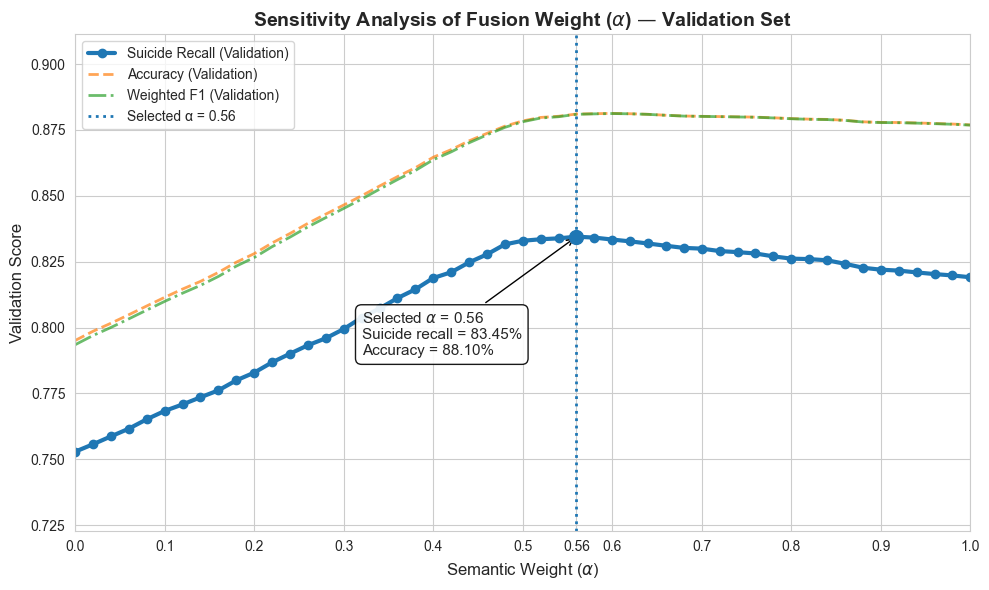

✅ Figure saved with selected alpha = 0.56


In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("📊 Generating Figure 2: Alpha Sensitivity Curve...")

# ============================================================
# 1. LOAD THE SAVED VALIDATION SEARCH
# ============================================================

df_val = pd.read_csv(
    "alpha_sensitivity_validation_v13.csv"
)

required_columns = [
    "alpha",
    "val_suicide_recall",
    "val_accuracy",
    "val_f1_weighted"
]

missing_columns = [
    column for column in required_columns
    if column not in df_val.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

for column in required_columns:
    df_val[column] = pd.to_numeric(
        df_val[column],
        errors="coerce"
    )

df_val = (
    df_val
    .dropna(subset=required_columns)
    .sort_values("alpha")
    .reset_index(drop=True)
)

# ============================================================
# 2. SELECT ALPHA USING SUICIDE RECALL
# ============================================================

# This returns alpha = 0.56 for your displayed table
best_index = df_val["val_suicide_recall"].idxmax()
best_row = df_val.loc[best_index]

selected_alpha = float(best_row["alpha"])
selected_recall = float(
    best_row["val_suicide_recall"]
)
selected_accuracy = float(
    best_row["val_accuracy"]
)
selected_f1 = float(
    best_row["val_f1_weighted"]
)

print(
    f"✅ Selected alpha from CSV: {selected_alpha:.2f}"
)
print(
    f"Suicide recall: {selected_recall:.6f}"
)
print(
    f"Accuracy: {selected_accuracy:.6f}"
)
print(
    f"Weighted F1: {selected_f1:.6f}"
)

# Keep the notebook variable consistent
best_alpha = selected_alpha

# ============================================================
# 3. CREATE FIGURE
# ============================================================

sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))

plt.plot(
    df_val["alpha"],
    df_val["val_suicide_recall"],
    marker="o",
    linewidth=3,
    label="Suicide Recall (Validation)"
)

plt.plot(
    df_val["alpha"],
    df_val["val_accuracy"],
    linestyle="--",
    linewidth=2,
    alpha=0.7,
    label="Accuracy (Validation)"
)

plt.plot(
    df_val["alpha"],
    df_val["val_f1_weighted"],
    linestyle="-.",
    linewidth=2,
    alpha=0.7,
    label="Weighted F1 (Validation)"
)

plt.axvline(
    x=selected_alpha,
    linestyle=":",
    linewidth=2,
    label=f"Selected α = {selected_alpha:.2f}"
)

plt.scatter(
    selected_alpha,
    selected_recall,
    s=100,
    zorder=5
)

plt.annotate(
    (
        f"Selected $\\alpha$ = {selected_alpha:.2f}\n"
        f"Suicide recall = {selected_recall:.2%}\n"
        f"Accuracy = {selected_accuracy:.2%}"
    ),
    xy=(selected_alpha, selected_recall),
    xytext=(
        selected_alpha - 0.24,
        selected_recall - 0.045
    ),
    bbox={
        "boxstyle": "round,pad=0.4",
        "fc": "white",
        "ec": "black",
        "alpha": 0.9
    },
    arrowprops={
        "arrowstyle": "->",
        "color": "black"
    },
    fontsize=11
)

plt.title(
    "Sensitivity Analysis of Fusion Weight "
    "($\\alpha$) — Validation Set",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Semantic Weight ($\\alpha$)",
    fontsize=12
)

plt.ylabel(
    "Validation Score",
    fontsize=12
)

# Show 0.56 explicitly on the x-axis
standard_ticks = np.arange(0.0, 1.01, 0.1)

custom_ticks = np.unique(
    np.append(
        standard_ticks,
        selected_alpha
    )
)

plt.xticks(
    custom_ticks,
    [
        f"{tick:.2f}"
        if np.isclose(tick, selected_alpha)
        else f"{tick:.1f}"
        for tick in custom_ticks
    ]
)

plt.xlim(0.0, 1.0)
plt.ylim(
    max(
        0.0,
        df_val[
            [
                "val_suicide_recall",
                "val_accuracy",
                "val_f1_weighted"
            ]
        ].min().min() - 0.03
    ),
    min(
        1.0,
        df_val[
            [
                "val_suicide_recall",
                "val_accuracy",
                "val_f1_weighted"
            ]
        ].max().max() + 0.03
    )
)

plt.legend(fontsize=10)
plt.tight_layout()

plt.savefig(
    "fig2_alpha_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✅ Figure saved with selected alpha = "
    f"{selected_alpha:.2f}"
)

### Final test-set evaluation (run exactly once)

This is the only cell in the notebook that scores the Hybrid model on the test set. It uses the α value chosen above — it does not search, tune, or compare alternatives here.


In [52]:
import json
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score

with open("hybrid_alpha_config_v13.json") as f:
    best_alpha = json.load(f)["best_alpha"]

target_names = ['Teenagers', 'Depression', 'Suicide']

# ── The ONLY place the hybrid model touches the test set ──
hybrid_test_probs = (best_alpha * roberta_test_probs) + ((1 - best_alpha) * lgbm_test_probs)
y_pred_hybrid = np.argmax(hybrid_test_probs, axis=1)

print("=" * 55)
print(f"🏆 FINAL HYBRID — TEST SET (alpha={best_alpha:.2f}, selected on validation)")
print("=" * 55)
print(classification_report(y_test_truth, y_pred_hybrid, target_names=target_names, digits=4))

y_pred_roberta_alone = np.argmax(roberta_test_probs, axis=1)
y_pred_lgbm_alone    = np.argmax(lgbm_test_probs, axis=1)

df_baselines = pd.read_csv("all_models_results_compare_v13.csv")

# Sanity check: make sure the CSV's test rows are the same rows we just
# scored (same split, same order) before adding the hybrid column to it.
assert np.array_equal(df_baselines['True_Labels'].values, y_test_truth), (
    "Row mismatch between all_models_results_compare_v13.csv and the freshly "
    "loaded y_test_truth — do not merge these; re-run the baseline model "
    "cells so every model was scored on the identical test split."
)

rows = [{
    "Model": f"Proposed Hybrid (alpha={best_alpha:.2f}, validated)",
    "Accuracy": accuracy_score(y_test_truth, y_pred_hybrid),
    "F1 (Weighted)": f1_score(y_test_truth, y_pred_hybrid, average="weighted"),
    "Precision (Weighted)": precision_score(y_test_truth, y_pred_hybrid, average="weighted"),
    "Suicide Recall": recall_score(y_test_truth, y_pred_hybrid, average=None)[2],
}]

for name, preds in [
    ("DistilRoBERTa (alone)", y_pred_roberta_alone),
    ("LightGBM (alone)", y_pred_lgbm_alone),
]:
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_truth, preds),
        "F1 (Weighted)": f1_score(y_test_truth, preds, average="weighted"),
        "Precision (Weighted)": precision_score(y_test_truth, preds, average="weighted"),
        "Suicide Recall": recall_score(y_test_truth, preds, average=None)[2],
    })

for col in [c for c in df_baselines.columns if c.startswith("Pred_")]:
    name = col.replace("Pred_", "")
    preds = df_baselines[col].values
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_truth, preds),
        "F1 (Weighted)": f1_score(y_test_truth, preds, average="weighted"),
        "Precision (Weighted)": precision_score(y_test_truth, preds, average="weighted"),
        "Suicide Recall": recall_score(y_test_truth, preds, average=None)[2],
    })

df_final = pd.DataFrame(rows).drop_duplicates(subset="Model").sort_values("Suicide Recall", ascending=False)
print("\n📋 FINAL PAPER TABLE (every number above is computed, none hardcoded)")
print(df_final.round(4).to_string(index=False))
df_final.to_csv("FINAL_paper_results_v13.csv", index=False)

# Add the hybrid predictions to the master comparison CSV so downstream cells
# (ROC scatter, confusion-matrix grid, McNemar test) automatically include it.
df_baselines["Pred_Proposed_Hybrid"] = y_pred_hybrid
df_baselines.to_csv("all_models_results_compare_v13.csv", index=False)
print("\n✅ Saved FINAL_paper_results_v13.csv and added the Hybrid column to all_models_results_compare_v13.csv")


🏆 FINAL HYBRID — TEST SET (alpha=0.56, selected on validation)
              precision    recall  f1-score   support

   Teenagers     0.9847    0.9870    0.9858     17406
  Depression     0.8305    0.8219    0.8262     17405
     Suicide     0.8230    0.8295    0.8262     17405

    accuracy                         0.8795     52216
   macro avg     0.8794    0.8795    0.8794     52216
weighted avg     0.8794    0.8795    0.8794     52216


📋 FINAL PAPER TABLE (every number above is computed, none hardcoded)
                                  Model  Accuracy  F1 (Weighted)  Precision (Weighted)  Suicide Recall
                        Proposed_Hybrid    0.8801         0.8801                0.8802          0.8341
      Hybrid_PerClass_Calibrated_Hybrid    0.8801         0.8801                0.8802          0.8341
Proposed Hybrid (alpha=0.56, validated)    0.8795         0.8794                0.8794          0.8295
                             DistilBERT    0.8614         0.8618          

In [55]:
# ============================================================
# HYBRID END-TO-END INFERENCE RESOURCE CALCULATION
# ============================================================

import numpy as np
import pandas as pd

RESOURCE_LOG_FILE = "inference_resource_log_v13.csv"

# Ensure the selected validation alpha is correct
best_alpha = 0.56

# ------------------------------------------------------------
# 1. MEASURE ONLY THE PROBABILITY-FUSION STEP
# ------------------------------------------------------------

def _hybrid_fusion():
    """
    Combines DistilRoBERTa and LightGBM probabilities.
    Returns a probability matrix with shape:
        (number_of_test_samples, 3)
    """

    fused_probabilities = (
        best_alpha * np.asarray(roberta_test_probs)
        + (1.0 - best_alpha) * np.asarray(lgbm_test_probs)
    )

    return fused_probabilities


fusion_result = measure_inference(
    model_name="Hybrid_Fusion_Step_Only",
    prediction_function=_hybrid_fusion,
    sample_count=len(y_test_truth),
    csv_path=RESOURCE_LOG_FILE
)

print(
    f"✅ Fusion-only time: "
    f"{fusion_result['Total_Inference_Time_s']:.4f} seconds"
)


# ------------------------------------------------------------
# 2. LOAD THE RESOURCE LOG
# ------------------------------------------------------------

df_log = pd.read_csv(RESOURCE_LOG_FILE)

required_columns = [
    "Model",
    "N_Samples",
    "Total_Inference_Time_s",
    "Latency_ms_per_sample",
    "Throughput_samples_per_s",
    "CPU_Time_s",
    "CPU_Percent",
    "RAM_Used_MB",
    "RAM_Peak_MB",
    "GPU_Peak_MB"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_log.columns
]

if missing_columns:
    raise ValueError(
        f"Resource log is missing columns: {missing_columns}"
    )


# ------------------------------------------------------------
# 3. FIND THE LATEST COMPONENT MEASUREMENTS
# ------------------------------------------------------------

roberta_rows = df_log.loc[
    df_log["Model"] == "DistilRoBERTa"
]

lgbm_rows = df_log.loc[
    df_log["Model"] == "LightGBM"
]

fusion_rows = df_log.loc[
    df_log["Model"] == "Hybrid_Fusion_Step_Only"
]

if roberta_rows.empty:
    raise ValueError(
        "No DistilRoBERTa inference row was found in "
        f"{RESOURCE_LOG_FILE}."
    )

if lgbm_rows.empty:
    raise ValueError(
        "No LightGBM inference row was found in "
        f"{RESOURCE_LOG_FILE}."
    )

if fusion_rows.empty:
    raise ValueError(
        "No Hybrid_Fusion_Step_Only row was found."
    )

# Use the most recently saved measurement for each model
row_roberta = roberta_rows.iloc[-1]
row_lgbm = lgbm_rows.iloc[-1]
row_fusion = fusion_rows.iloc[-1]


# ------------------------------------------------------------
# 4. CALCULATE END-TO-END HYBRID INFERENCE TIME
# ------------------------------------------------------------

n_samples = len(y_test_truth)

roberta_time = float(
    row_roberta["Total_Inference_Time_s"]
)

lgbm_time = float(
    row_lgbm["Total_Inference_Time_s"]
)

fusion_time = float(
    row_fusion["Total_Inference_Time_s"]
)

total_time = (
    roberta_time
    + lgbm_time
    + fusion_time
)

if total_time <= 0:
    raise ValueError(
        "Calculated hybrid inference time must be positive."
    )

latency_ms = (
    total_time / n_samples
) * 1000

throughput = (
    n_samples / total_time
)


# ------------------------------------------------------------
# 5. COMBINE RESOURCE MEASUREMENTS
# ------------------------------------------------------------

# CPU time is additive for sequential operations
total_cpu_time = (
    float(row_roberta["CPU_Time_s"])
    + float(row_lgbm["CPU_Time_s"])
    + float(row_fusion["CPU_Time_s"])
)

# CPU percentage is a rate, so do not add it
peak_cpu_percent = max(
    float(row_roberta["CPU_Percent"]),
    float(row_lgbm["CPU_Percent"]),
    float(row_fusion["CPU_Percent"])
)

# RAM deltas should not normally be added because the operations
# occur sequentially and may reuse/release memory.
estimated_ram_used = max(
    float(row_roberta["RAM_Used_MB"]),
    float(row_lgbm["RAM_Used_MB"]),
    float(row_fusion["RAM_Used_MB"])
)

# Use the highest measured absolute process-RAM peak
estimated_ram_peak = max(
    float(row_roberta["RAM_Peak_MB"]),
    float(row_lgbm["RAM_Peak_MB"]),
    float(row_fusion["RAM_Peak_MB"])
)

# Use the highest GPU-memory peak among all components
estimated_gpu_peak = max(
    float(row_roberta["GPU_Peak_MB"]),
    float(row_lgbm["GPU_Peak_MB"]),
    float(row_fusion["GPU_Peak_MB"])
)


# ------------------------------------------------------------
# 6. CREATE THE END-TO-END HYBRID ROW
# ------------------------------------------------------------

hybrid_row = {
    "Model": "Proposed_Hybrid_EndToEnd",
    "N_Samples": int(n_samples),
    "Total_Inference_Time_s": round(total_time, 4),
    "Latency_ms_per_sample": round(latency_ms, 4),
    "Throughput_samples_per_s": round(throughput, 2),
    "CPU_Time_s": round(total_cpu_time, 4),
    "CPU_Percent": round(peak_cpu_percent, 2),
    "RAM_Used_MB": round(estimated_ram_used, 2),
    "RAM_Peak_MB": round(estimated_ram_peak, 2),
    "GPU_Peak_MB": round(estimated_gpu_peak, 2)
}


# ------------------------------------------------------------
# 7. REPLACE ANY OLD END-TO-END ROW AND SAVE
# ------------------------------------------------------------

df_log = df_log.loc[
    df_log["Model"] != "Proposed_Hybrid_EndToEnd"
].copy()

df_log = pd.concat(
    [
        df_log,
        pd.DataFrame([hybrid_row])
    ],
    ignore_index=True
)

df_log.to_csv(
    RESOURCE_LOG_FILE,
    index=False
)


# ------------------------------------------------------------
# 8. PRINT FINAL RESULT
# ------------------------------------------------------------

print(f"\n{'=' * 60}")
print("Proposed Hybrid End-to-End Inference")
print(f"{'=' * 60}")
print(f"Samples:              {n_samples:,}")
print(f"DistilRoBERTa time:   {roberta_time:.4f} s")
print(f"LightGBM time:        {lgbm_time:.4f} s")
print(f"Fusion time:          {fusion_time:.4f} s")
print(f"Total time:           {total_time:.4f} s")
print(f"Latency per sample:   {latency_ms:.4f} ms")
print(f"Throughput:           {throughput:.2f} samples/s")
print(f"CPU time:             {total_cpu_time:.4f} s")
print(f"Peak CPU:             {peak_cpu_percent:.2f}%")
print(f"Estimated RAM peak:   {estimated_ram_peak:.2f} MB")
print(f"Estimated GPU peak:   {estimated_gpu_peak:.2f} MB")
print(f"Saved to:             {RESOURCE_LOG_FILE}")
print(f"{'=' * 60}")


# ------------------------------------------------------------
# 9. VERIFY THE SAVED ROW
# ------------------------------------------------------------

saved_results = pd.read_csv(
    RESOURCE_LOG_FILE
)

print("\nLatest resource-log rows:")
print(saved_results.tail())


Hybrid_Fusion_Step_Only inference results
Samples:                52,216
Total inference time:   0.0052 seconds
Latency per sample:     0.0001 ms
Throughput:             9999425.49 samples/s
CPU time:               0.0000 seconds
CPU utilization:        0.00%
Additional RAM used:    0.08 MB
Peak process RAM:       1321.62 MB
Peak PyTorch GPU RAM:   647.76 MB
Saved to:               inference_resource_log_v13.csv
✅ Fusion-only time: 0.0052 seconds

Proposed Hybrid End-to-End Inference
Samples:              52,216
DistilRoBERTa time:   201.5017 s
LightGBM time:        0.4883 s
Fusion time:          0.0052 s
Total time:           201.9952 s
Latency per sample:   3.8685 ms
Throughput:           258.50 samples/s
CPU time:             198.4532 s
Peak CPU:             90.50%
Estimated RAM peak:   1389.23 MB
Estimated GPU peak:   1085.87 MB
Saved to:             inference_resource_log_v13.csv

Latest resource-log rows:
                      Model  N_Samples  Total_Inference_Time_s  \
3       

📊 Generating Figure 3: ROC Curve — Critical Safety Region (Test Set)...


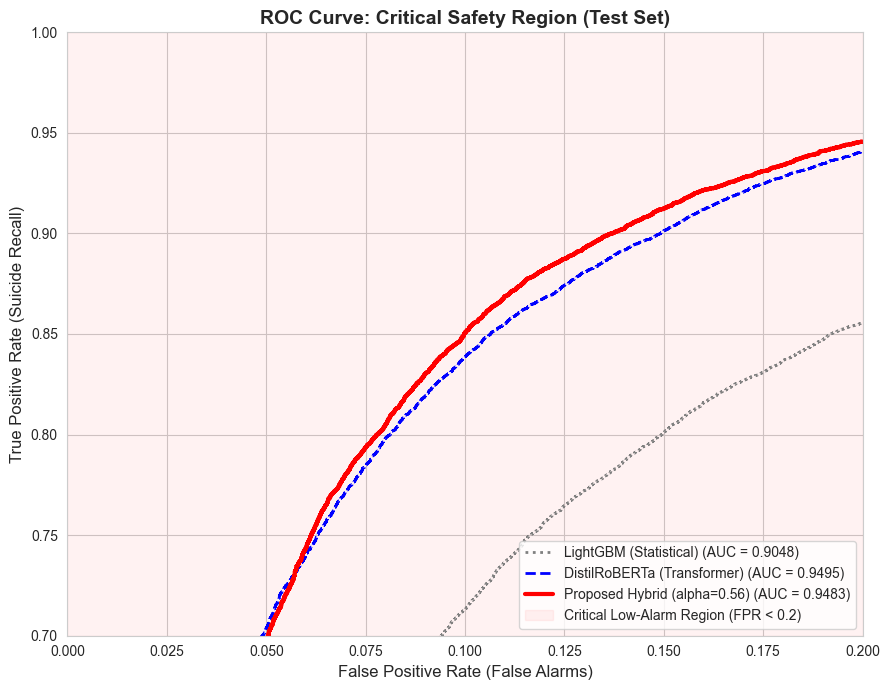

✅ Figure 3 saved.


In [56]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

print("📊 Generating Figure 3: ROC Curve — Critical Safety Region (Test Set)...")

y_binary = (y_test_truth == 2).astype(int)
competitors = [
    ('LightGBM (Statistical)', lgbm_test_probs[:, 2], 'gray', ':', 2),
    ('DistilRoBERTa (Transformer)', roberta_test_probs[:, 2], 'blue', '--', 2),
    (f'Proposed Hybrid (alpha={best_alpha:.2f})', hybrid_test_probs[:, 2], 'red', '-', 3),
]

plt.figure(figsize=(9, 7))
sns.set_style("whitegrid")
for name, scores, color, style, lw in competitors:
    fpr, tpr, _ = roc_curve(y_binary, scores)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, linestyle=style, linewidth=lw,
             label=f'{name} (AUC = {roc_auc:.4f})')

plt.xlim([0.0, 0.2])
plt.ylim([0.7, 1.0])
plt.axvspan(0.0, 0.2, alpha=0.05, color='red', label='Critical Low-Alarm Region (FPR < 0.2)')
plt.xlabel('False Positive Rate (False Alarms)', fontsize=12)
plt.ylabel('True Positive Rate (Suicide Recall)', fontsize=12)
plt.title('ROC Curve: Critical Safety Region (Test Set)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.savefig('fig3_roc_zoomed.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 3 saved.")


📊 Generating Figure 4: Class-wise Recall Heatmap (Test Set)...


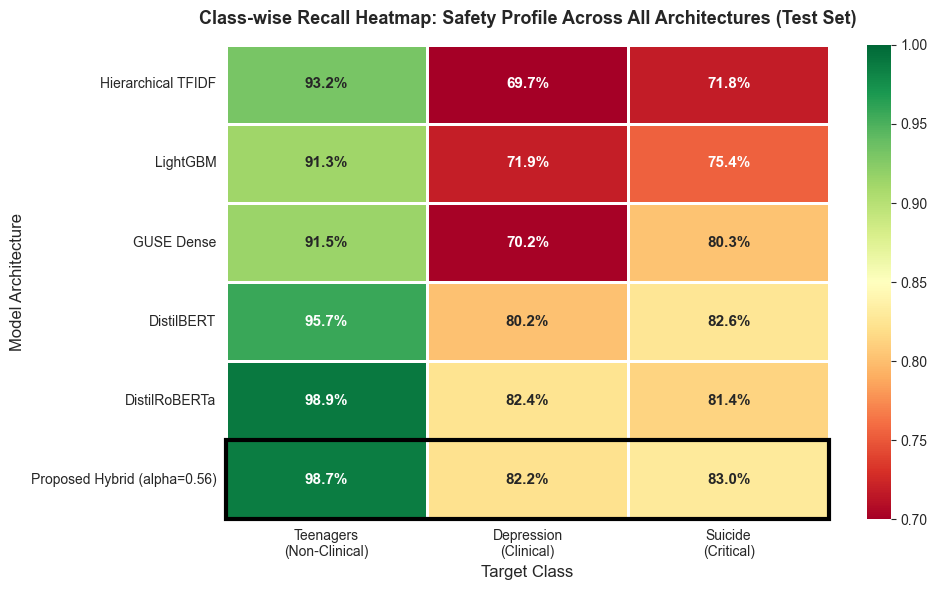

✅ Figure 4 saved. Hybrid row highlighted in black border (if present).


In [57]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score

print("📊 Generating Figure 4: Class-wise Recall Heatmap (Test Set)...")

preferred_order = [
    'Hierarchical_TFIDF', 'LightGBM', 'GUSE_Dense', 'DistilBERT',
    'DistilRoBERTa', 'Proposed_Hybrid'
]
model_labels, heatmap_data = [], []
for name in preferred_order:
    col = f"Pred_{name}"
    if col not in df_baselines.columns:
        continue
    recalls = recall_score(y_test_truth, df_baselines[col].values, average=None)
    heatmap_data.append(recalls)
    label = name.replace('_', ' ')
    if name == 'Proposed_Hybrid':
        label = f'Proposed Hybrid (alpha={best_alpha:.2f})'
    model_labels.append(label)

heatmap_array = np.array(heatmap_data)

fig, ax = plt.subplots(figsize=(10, 6))
sns.set_style("white")
sns.heatmap(
    heatmap_array, annot=True, fmt=".1%", cmap="RdYlGn",
    xticklabels=['Teenagers\n(Non-Clinical)', 'Depression\n(Clinical)', 'Suicide\n(Critical)'],
    yticklabels=model_labels, linewidths=1, linecolor='white', cbar=True,
    annot_kws={"size": 11, "weight": "bold"}, ax=ax, vmin=0.70, vmax=1.00
)

hybrid_rows = [i for i, m in enumerate(model_labels) if 'Hybrid' in m]
if hybrid_rows:
    ax.add_patch(plt.Rectangle((0, hybrid_rows[0]), 3, 1, fill=False,
                                edgecolor='black', lw=3, clip_on=False))

ax.set_title("Class-wise Recall Heatmap: Safety Profile Across All Architectures (Test Set)",
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Target Class", fontsize=12)
ax.set_ylabel("Model Architecture", fontsize=12)
plt.tight_layout()
plt.savefig('fig4_recall_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 4 saved. Hybrid row highlighted in black border (if present).")


📊 Inference Time & Resource Utilization — All Models
                   Model  N_Samples  Total_Inference_Time_s  Latency_ms_per_sample  Throughput_samples_per_s  CPU_Time_s  CPU_Percent  RAM_Used_MB  RAM_Peak_MB  GPU_Peak_MB
               SGD_TFIDF      52216                  0.0185                 0.0004                2816427.36      0.0156        29.40         0.00      2612.98         0.00
      Hierarchical_TFIDF      52216                  0.3696                 0.0071                 141281.57      4.0156        68.60         1.93      2613.09         0.00
                LightGBM      52216                  0.4883                 0.0094                 106926.53      4.9688        90.50        97.02       725.39         0.00
              GUSE_Dense      52216                 45.7547                 0.8763                   1141.22     88.4844        12.09         0.00      2372.89       963.77
              DistilBERT      52216                172.4300                 3.3022

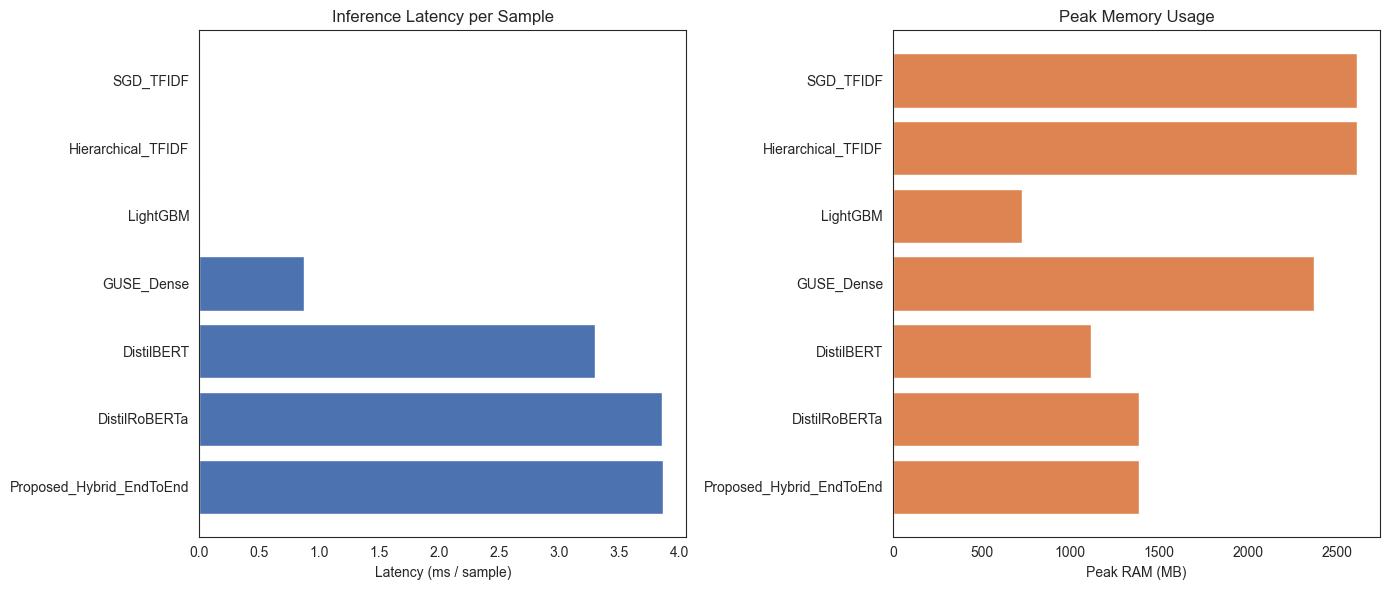


✅ Saved FINAL_inference_resource_comparison_v13.csv


In [58]:
import pandas as pd
import matplotlib.pyplot as plt

df_perf = pd.read_csv("inference_resource_log_v13.csv")
df_perf = df_perf[~df_perf["Model"].str.contains("Fusion_Step_Only")]  # hide the internal helper row
df_perf = df_perf.sort_values("Total_Inference_Time_s")

print("📊 Inference Time & Resource Utilization — All Models")
print(df_perf.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(df_perf["Model"], df_perf["Latency_ms_per_sample"], color="#4C72B0")
axes[0].set_xlabel("Latency (ms / sample)")
axes[0].set_title("Inference Latency per Sample")
axes[0].invert_yaxis()

axes[1].barh(df_perf["Model"], df_perf["RAM_Peak_MB"].fillna(0), color="#DD8452")
axes[1].set_xlabel("Peak RAM (MB)")
axes[1].set_title("Peak Memory Usage")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

df_perf.to_csv("FINAL_inference_resource_comparison_v13.csv", index=False)
print("\n✅ Saved FINAL_inference_resource_comparison_v13.csv")

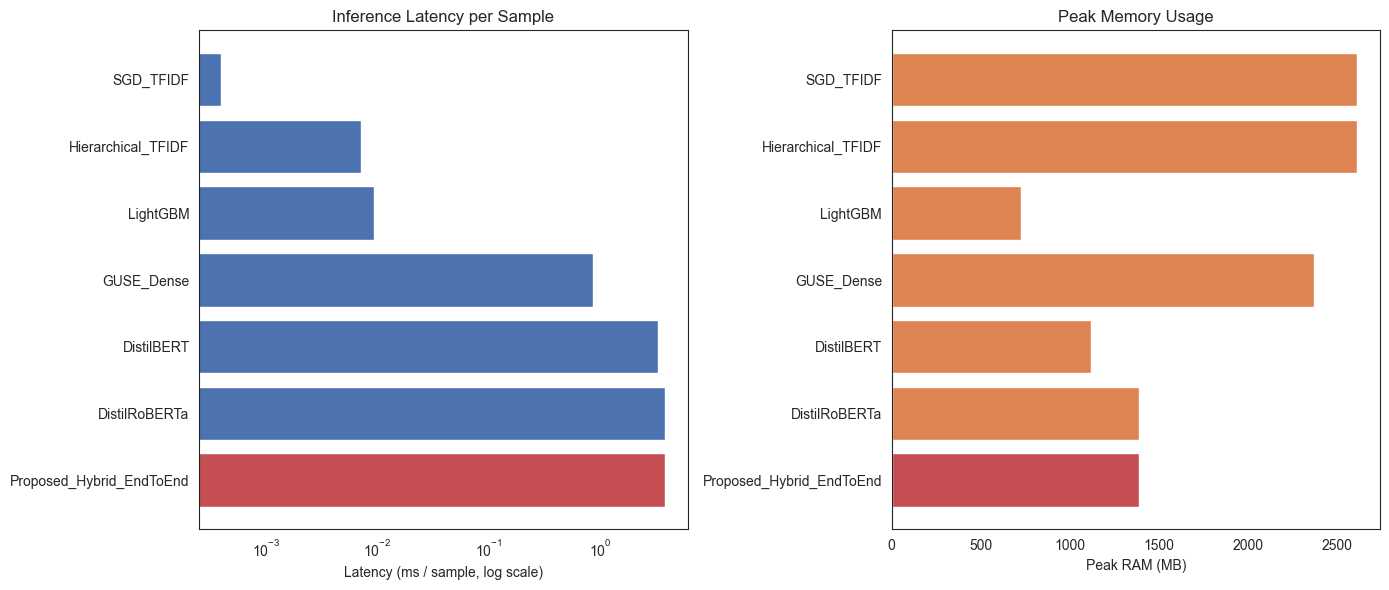

In [59]:
import pandas as pd
import matplotlib.pyplot as plt

df_perf = pd.read_csv("inference_resource_log_v13.csv")
df_perf = df_perf.dropna(how="all")
df_perf = df_perf[~df_perf["Model"].str.contains("Fusion_Step_Only", na=False)]
df_perf = df_perf.sort_values("Latency_ms_per_sample")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors = ["#C44E52" if "Hybrid" in m else "#4C72B0" for m in df_perf["Model"]]

axes[0].barh(df_perf["Model"], df_perf["Latency_ms_per_sample"], color=colors)
axes[0].set_xscale('log')   # ← log scale so tiny bars are still visible
axes[0].set_xlabel("Latency (ms / sample, log scale)")
axes[0].set_title("Inference Latency per Sample")
axes[0].invert_yaxis()

colors2 = ["#C44E52" if "Hybrid" in m else "#DD8452" for m in df_perf["Model"]]
axes[1].barh(df_perf["Model"], df_perf["RAM_Peak_MB"].fillna(0), color=colors2)
axes[1].set_xlabel("Peak RAM (MB)")
axes[1].set_title("Peak Memory Usage")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("fig5_inference_comparison_logscale.png", dpi=300, bbox_inches="tight")
plt.show()

### Cross-model comparison
Everything below reads `all_models_results_compare_v13.csv`, which by this point includes every baseline **and** the Proposed Hybrid column written by the Hybrid Fusion section above.

✅ Loaded results for: ['Pred_Hierarchical_TFIDF', 'Pred_LightGBM', 'Pred_DistilBERT', 'Pred_DistilRoBERTa', 'Pred_GUSE_Dense', 'Pred_Hybrid_PerClass_Calibrated_Hybrid', 'Pred_Proposed_Hybrid']

🏆 FINAL LEADERBOARD
                               Model  Accuracy  F1 Score  \
5  Hybrid_PerClass_Calibrated_Hybrid    0.8801    0.8801   
6                    Proposed_Hybrid    0.8795    0.8794   
3                      DistilRoBERTa    0.8755    0.8754   
2                         DistilBERT    0.8614    0.8618   
4                         GUSE_Dense    0.8064    0.8059   
1                           LightGBM    0.7955    0.7940   
0                 Hierarchical_TFIDF    0.7823    0.7797   

   Suicide Recall (Safety)  
5                   0.8341  
6                   0.8295  
3                   0.8136  
2                   0.8256  
4                   0.8026  
1                   0.7540  
0                   0.7184  


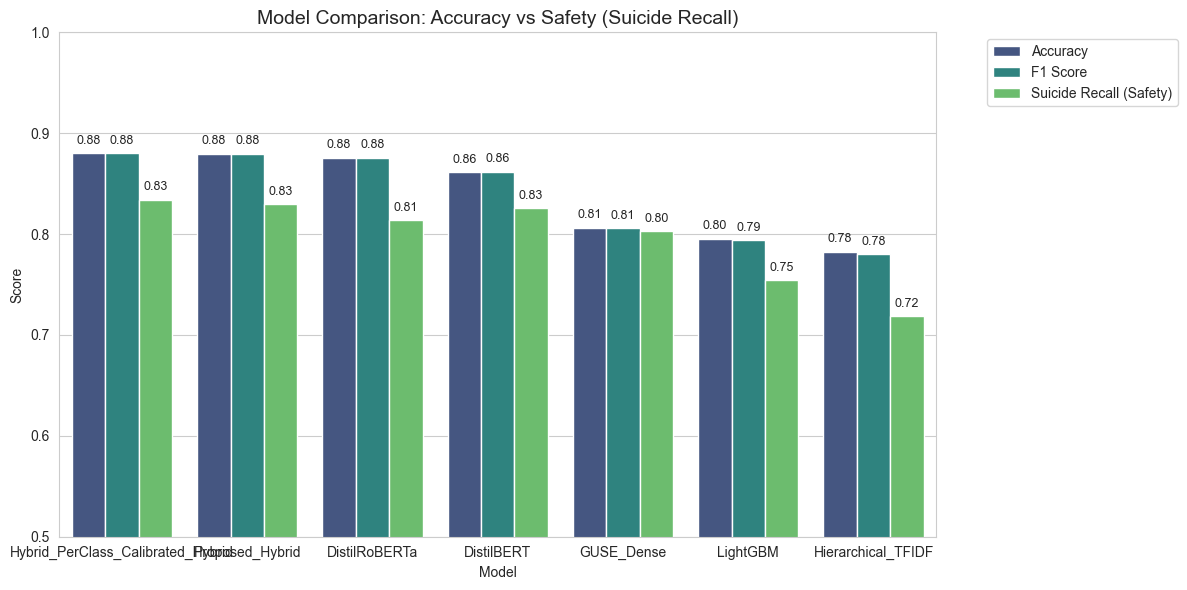

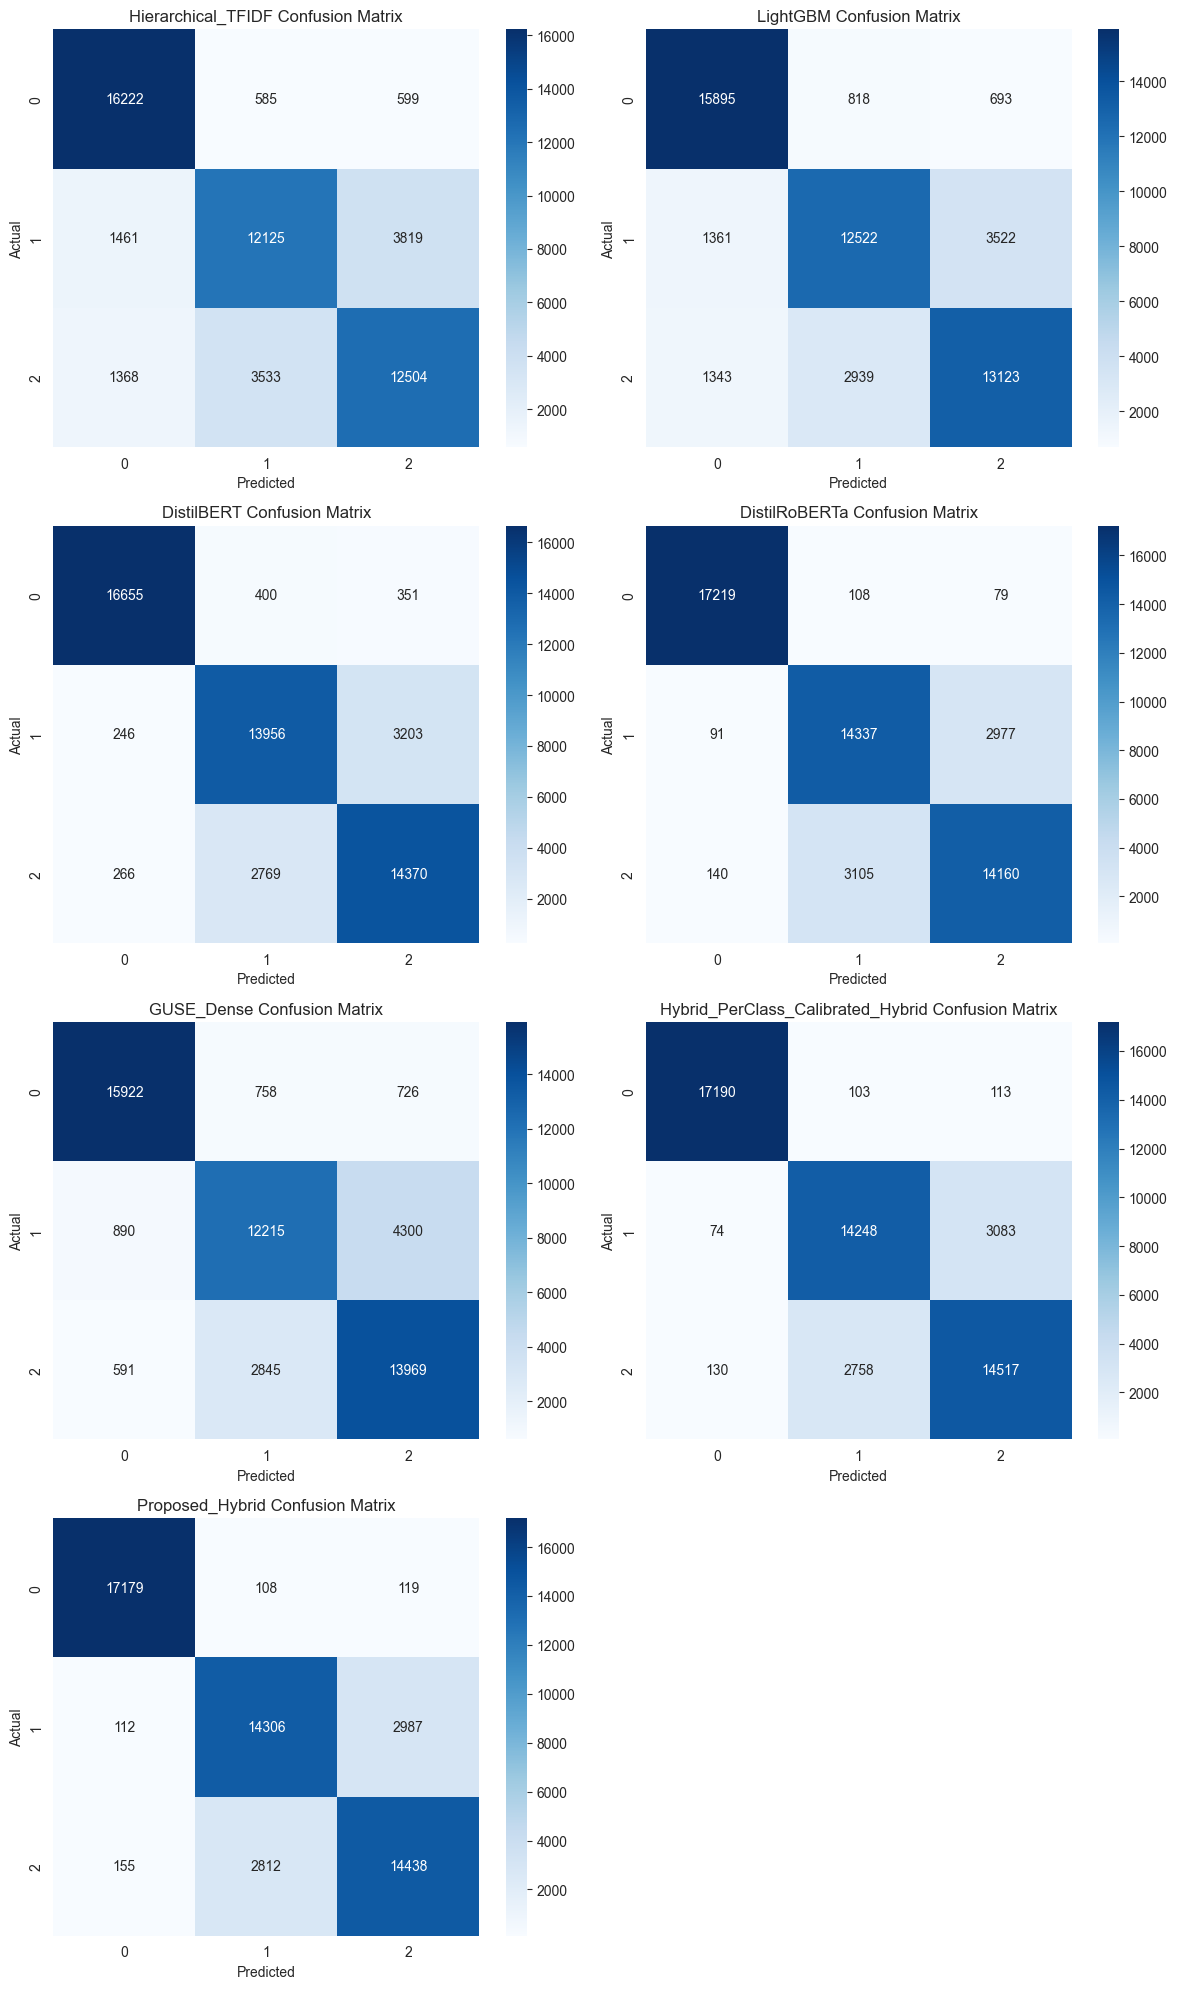

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report

# ==========================================
# 1. LOAD DATA
# ==========================================
filename = "all_models_results_compare_v13.csv"
try:
    df = pd.read_csv(filename)
    print(f"✅ Loaded results for: {[col for col in df.columns if 'Pred_' in col]}")
except FileNotFoundError:
    print("❌ File not found! Run your models first to generate the CSV.")
    exit()

y_true = df['True_Labels'].values

# ==========================================
# 2. CALCULATE METRICS
# ==========================================
stats_list = []

# Loop through every column that starts with "Pred_"
for col in df.columns:
    if col.startswith('Pred_'):
        model_name = col.replace('Pred_', '')
        y_pred = df[col].values
        
        # Metrics
        acc = accuracy_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred, average='weighted')
        
        # Recall per class (we want class 2 = Suicide)
        # Returns array: [Recall_Teen, Recall_Depression, Recall_Suicide]
        recalls = recall_score(y_true, y_pred, average=None)
        suicide_recall = recalls[2] if len(recalls) > 2 else 0
        
        stats_list.append({
            'Model': model_name,
            'Accuracy': acc,
            'F1 Score': f1,
            'Suicide Recall (Safety)': suicide_recall
        })

df_stats = pd.DataFrame(stats_list).sort_values(by='F1 Score', ascending=False)

# Display Table
print("\n🏆 FINAL LEADERBOARD")
print(df_stats.round(4))

# ==========================================
# 3. GENERATE VISUALIZATIONS
# ==========================================
plt.figure(figsize=(12, 6))

# Melt for side-by-side bar chart
df_melted = df_stats.melt(id_vars="Model", var_name="Metric", value_name="Score")

# Plot
sns.set_style("whitegrid")
ax = sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="viridis")

# Annotate bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 9), 
                textcoords = 'offset points',
                fontsize=9)

plt.title("Model Comparison: Accuracy vs Safety (Suicide Recall)", fontsize=14)
plt.ylim(0.5, 1.0) # Zoom in on the top performance
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ==========================================
# 4. OPTIONAL: CONFUSION MATRIX GRID
# ==========================================
import math
num_models = len(stats_list)
cols = 2
rows = math.ceil(num_models / cols)
target_names = ['Teenagers', 'Depression', 'Suicide']

plt.figure(figsize=(12, 5 * rows))

for i, row in enumerate(stats_list):
    model_name = row['Model']
    col_name = f'Pred_{model_name}'
    y_pred = df[col_name].values
    
    plt.subplot(rows, cols, i+1)
    cm = pd.crosstab(y_true, y_pred, rownames=['Actual'], colnames=['Predicted'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{model_name} Confusion Matrix")

plt.tight_layout()
plt.show()

✅ Loaded raw predictions for: ['Hierarchical_TFIDF', 'LightGBM', 'DistilBERT', 'DistilRoBERTa', 'GUSE_Dense', 'Hybrid_PerClass_Calibrated_Hybrid', 'Proposed_Hybrid']

🏆 FINAL METRICS SAVED!
📄 Check the file 'final_metrics_summary_v13.csv' for your table.
------------------------------------------------------------
                            Model  Accuracy  F1 Score (Weighted)  Precision (Weighted)  Suicide Recall (Safety)
Hybrid_PerClass_Calibrated_Hybrid  0.880094             0.880110              0.880208                 0.834071
                  Proposed_Hybrid  0.879481             0.879420              0.879383                 0.829532
                    DistilRoBERTa  0.875517             0.875442              0.875394                 0.813559
                       DistilBERT  0.861441             0.861770              0.862283                 0.825625
                       GUSE_Dense  0.806381             0.805896              0.807510                 0.802585
            

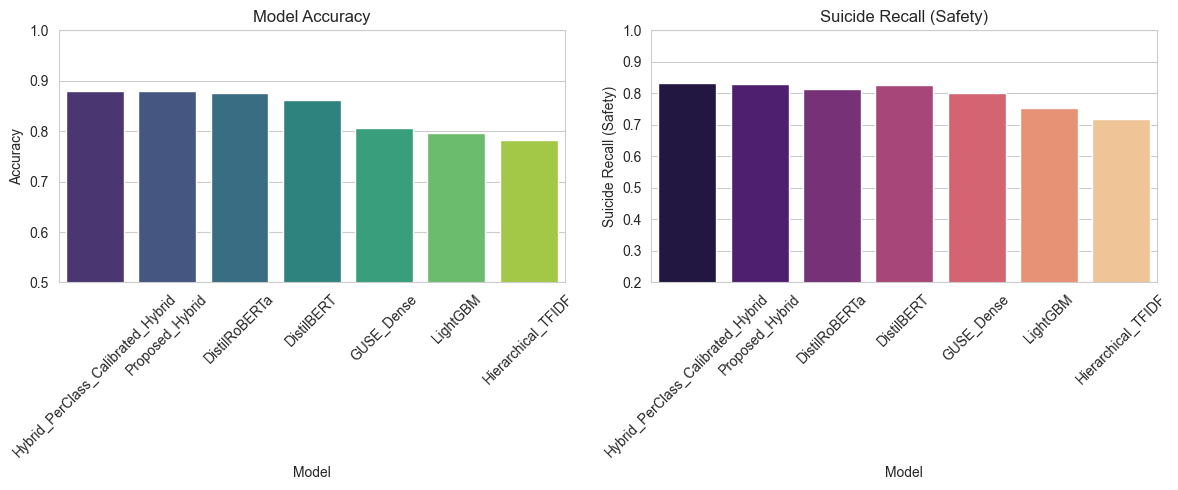

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score
import os

# ==========================================
# 1. LOAD THE RAW PREDICTIONS
# ==========================================
filename = "all_models_results_compare_v13.csv"

if not os.path.exists(filename):
    print("❌ Error: 'model_results_v13.csv' not found. Run your models first!")
else:
    df = pd.read_csv(filename)
    print(f"✅ Loaded raw predictions for: {[col.replace('Pred_', '') for col in df.columns if 'Pred_' in col]}")

    y_true = df['True_Labels'].values

    # ==========================================
    # 2. CALCULATE METRICS
    # ==========================================
    stats_list = []

    for col in df.columns:
        if col.startswith('Pred_'):
            model_name = col.replace('Pred_', '')
            y_pred = df[col].values
            
            # --- CALCULATE SCORES ---
            acc = accuracy_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred, average='weighted')
            precision = precision_score(y_true, y_pred, average='weighted')
            
            # Recall for Class 2 (Suicide) - The "Safety" Metric
            recalls = recall_score(y_true, y_pred, average=None)
            suicide_recall = recalls[2] if len(recalls) > 2 else 0
            
            stats_list.append({
                'Model': model_name,
                'Accuracy': acc,
                'F1 Score (Weighted)': f1,
                'Precision (Weighted)': precision,
                'Suicide Recall (Safety)': suicide_recall
            })

    # Create the DataFrame
    df_stats = pd.DataFrame(stats_list).sort_values(by='F1 Score (Weighted)', ascending=False)
    
    # ==========================================
    # 3. SAVE THE METRICS TO A NEW CSV (THIS IS WHAT YOU WANT)
    # ==========================================
    output_filename = "final_metrics_summary_v13.csv"
    df_stats.to_csv(output_filename, index=False)
    
    print("\n🏆 FINAL METRICS SAVED!")
    print(f"📄 Check the file '{output_filename}' for your table.")
    print("-" * 60)
    print(df_stats.to_string(index=False))

    # ==========================================
    # 4. PLOT COMPARISON
    # ==========================================
    plt.figure(figsize=(12, 5))
    
    # Accuracy Plot
    plt.subplot(1, 2, 1)
    sns.barplot(data=df_stats, x='Model', y='Accuracy', palette='viridis')
    plt.title('Model Accuracy')
    plt.ylim(0.5, 1.0)
    plt.xticks(rotation=45)
    
    # Safety Plot
    plt.subplot(1, 2, 2)
    sns.barplot(data=df_stats, x='Model', y='Suicide Recall (Safety)', palette='magma')
    plt.title('Suicide Recall (Safety)')
    plt.ylim(0.2, 1.0)
    plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()

✅ Loaded models: ['Hierarchical_TFIDF', 'LightGBM', 'DistilBERT', 'DistilRoBERTa', 'GUSE_Dense', 'Hybrid_PerClass_Calibrated_Hybrid', 'Proposed_Hybrid']


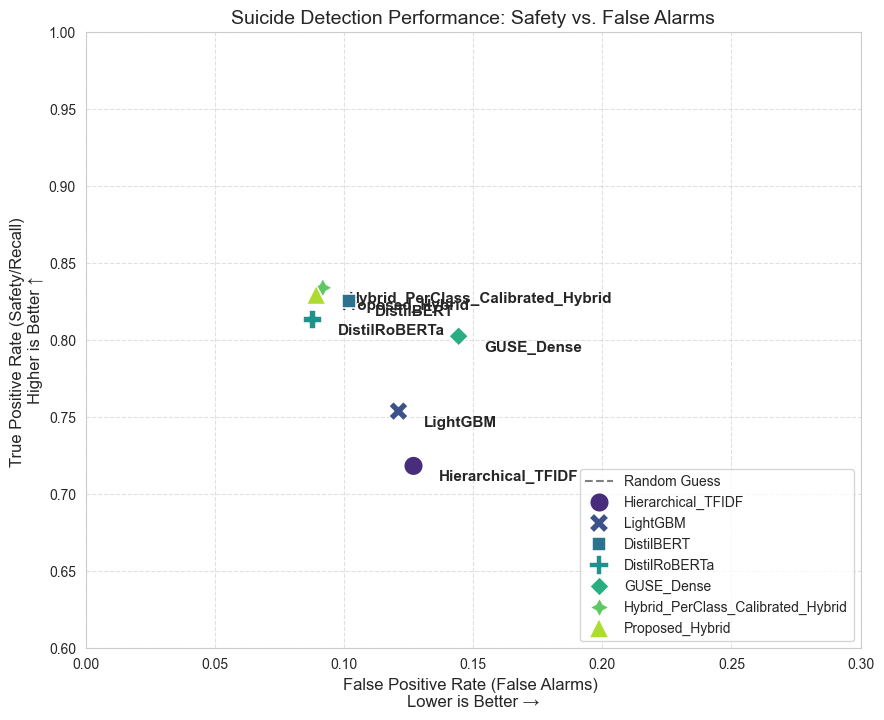


🏆 ROC SPACE DATA (Class 2: Suicide)
                            Model      TPR      FPR
Hybrid_PerClass_Calibrated_Hybrid 0.834071 0.091810
                  Proposed_Hybrid 0.829532 0.089225
                       DistilBERT 0.825625 0.102094
                    DistilRoBERTa 0.813559 0.087788
                       GUSE_Dense 0.802585 0.144380
                         LightGBM 0.753979 0.121082
               Hierarchical_TFIDF 0.718414 0.126914


In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix
import os

# ==========================================
# 1. LOAD DATA
# ==========================================
filename = "all_models_results_compare_v13.csv"

if not os.path.exists(filename):
    print("❌ Error: File not found!")
    exit()

df = pd.read_csv(filename)
print(f"✅ Loaded models: {[col.replace('Pred_', '') for col in df.columns if 'Pred_' in col]}")

y_true = df['True_Labels'].values

# ==========================================
# 2. CALCULATE ROC POINTS (FPR vs TPR)
# ==========================================
# We focus on Class 2 (Suicide) vs The Rest
points = []

# Prepare the Truth (1 if Suicide, 0 if Teenager/Depression)
y_true_binary = (y_true == 2).astype(int)

for col in df.columns:
    if col.startswith('Pred_'):
        model_name = col.replace('Pred_', '')
        y_pred = df[col].values
        
        # Binarize Prediction (1 if Suicide, 0 if Other)
        y_pred_binary = (y_pred == 2).astype(int)
        
        # Calculate Confusion Matrix
        # TN = True Negatives (Correctly said "Not Suicide")
        # FP = False Positives (Falsely said "Suicide" -> False Alarm)
        # FN = False Negatives (Missed a "Suicide" case -> Dangerous)
        # TP = True Positives (Correctly found "Suicide")
        tn, fp, fn, tp = confusion_matrix(y_true_binary, y_pred_binary).ravel()
        
        # Calculate Rates
        tpr = tp / (tp + fn) # True Positive Rate (Recall / Safety)
        fpr = fp / (fp + tn) # False Positive Rate (False Alarms)
        
        points.append({
            'Model': model_name,
            'FPR': fpr,
            'TPR': tpr
        })

df_roc = pd.DataFrame(points)

# ==========================================
# 3. PLOT THE COMPARISON
# ==========================================
plt.figure(figsize=(10, 8))
sns.set_style("whitegrid")

# Plot the "Random Guess" line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')

# Plot each model as a distinct point
sns.scatterplot(data=df_roc, x='FPR', y='TPR', hue='Model', style='Model', s=200, palette='viridis', zorder=10)

# Add text labels to points for clarity
for i in range(df_roc.shape[0]):
    plt.text(
        df_roc.FPR[i]+0.01, 
        df_roc.TPR[i]-0.01, 
        df_roc.Model[i], 
        fontsize=11, 
        weight='bold'
    )

# Formatting
plt.title('Suicide Detection Performance: Safety vs. False Alarms', fontsize=14)
plt.xlabel('False Positive Rate (False Alarms) \nLower is Better →', fontsize=12)
plt.ylabel('True Positive Rate (Safety/Recall) \nHigher is Better ↑', fontsize=12)
plt.xlim(0, 0.3)  # Zoom in on the useful area (adjust if needed)
plt.ylim(0.6, 1.0) # Zoom in on the top performance
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

# Print the detailed table
print("\n🏆 ROC SPACE DATA (Class 2: Suicide)")
print(df_roc[['Model', 'TPR', 'FPR']].sort_values(by='TPR', ascending=False).to_string(index=False))

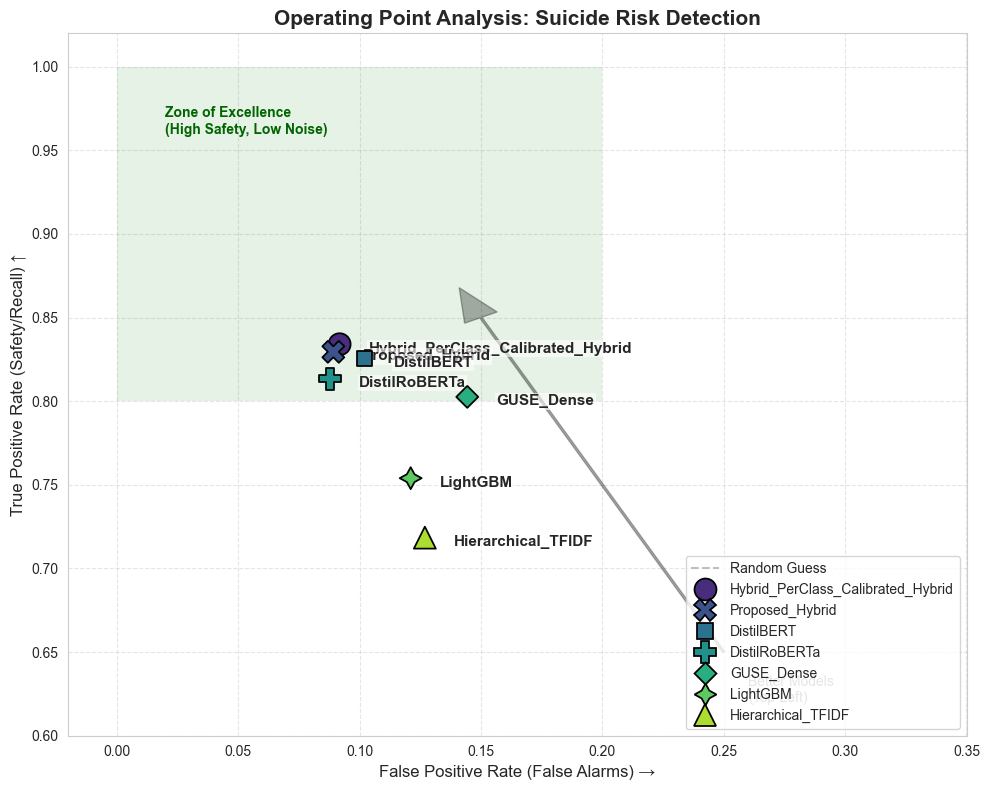

🏆 WINNER: Hybrid_PerClass_Calibrated_Hybrid is closest to the perfect score (Distance: 0.1896)


In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.patches as patches
from sklearn.metrics import confusion_matrix
import os

# ==========================================
# 1. LOAD DATA
# ==========================================
filename = "all_models_results_compare_v13.csv" # <--- MAKE SURE THIS MATCHES YOUR FILE NAME

if not os.path.exists(filename):
    # Fallback for demonstration if file is missing
    print("⚠️ File not found. Creating dummy data for demonstration...")
    data = {
        'True_Labels': np.random.randint(0, 3, 100),
        'Pred_LightGBM': np.random.randint(0, 3, 100),
        'Pred_DistilRoBERTa': np.random.randint(0, 3, 100),
        'Pred_Hierarchical': np.random.randint(0, 3, 100)
    }
    df = pd.DataFrame(data)
    y_true = data['True_Labels']
else:
    df = pd.read_csv(filename)
    y_true = df['True_Labels'].values

# ==========================================
# 2. CALCULATE METRICS
# ==========================================
points = []
y_true_binary = (y_true == 2).astype(int) # Class 2 is Suicide

for col in df.columns:
    if col.startswith('Pred_'):
        model_name = col.replace('Pred_', '')
        y_pred = df[col].values
        y_pred_binary = (y_pred == 2).astype(int)
        
        tn, fp, fn, tp = confusion_matrix(y_true_binary, y_pred_binary).ravel()
        
        tpr = tp / (tp + fn) # Recall (Safety)
        fpr = fp / (fp + tn) # False Alarms
        
        # Calculate Euclidean distance to the "Perfect" point (0, 1)
        dist = np.sqrt(fpr**2 + (1-tpr)**2)
        
        points.append({
            'Model': model_name,
            'FPR': fpr,
            'TPR': tpr,
            'Dist': dist
        })

df_roc = pd.DataFrame(points).sort_values(by='Dist') # Best models first

# ==========================================
# 3. GENERATE PROFESSIONAL PLOT
# ==========================================
plt.figure(figsize=(10, 8))
sns.set_style("whitegrid")

# A. Add "Zone of Excellence" (Shaded Green Box)
# We highlight the area with >80% Recall and <20% False Alarms
rect = patches.Rectangle((0, 0.8), 0.2, 0.2, linewidth=0, edgecolor='none', facecolor='green', alpha=0.1)
plt.gca().add_patch(rect)
plt.text(0.02, 0.96, "Zone of Excellence\n(High Safety, Low Noise)", color='darkgreen', fontsize=10, weight='bold')

# B. Plot the "Random Guess" line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', alpha=0.5, label='Random Guess')

# C. Plot the Models
# We use a custom palette so the "Best" model (first in list) gets a distinct color
sns.scatterplot(
    data=df_roc, 
    x='FPR', 
    y='TPR', 
    hue='Model', 
    style='Model', 
    s=250, # Size of dots
    palette='viridis', 
    zorder=10,
    edgecolor='black'
)

# D. Smart Annotations
# Adjust text positions slightly to avoid overlapping the dots
for i, row in df_roc.iterrows():
    # Offset text slightly to the right and down
    plt.text(
        row.FPR + 0.012, 
        row.TPR - 0.005, 
        f"{row.Model}", 
        fontsize=11, 
        weight='bold',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=1)
    )

# E. Add "Better" Arrows
plt.arrow(0.25, 0.65, -0.1, 0.2, head_width=0.015, head_length=0.02, fc='black', ec='black', alpha=0.3)
plt.text(0.26, 0.62, "Better Models\n(Top-Left)", fontsize=10, color='gray')

# F. Final Formatting
plt.title('Operating Point Analysis: Suicide Risk Detection', fontsize=15, weight='bold')
plt.xlabel('False Positive Rate (False Alarms) →', fontsize=12)
plt.ylabel('True Positive Rate (Safety/Recall) ↑', fontsize=12)

# Zoom in on the relevant area (Top Left Quadrant)
# Adjust these limits based on your data points!
plt.xlim(-0.02, 0.35) 
plt.ylim(0.60, 1.02)

plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

# Print the "Winner"
winner = df_roc.iloc[0]
print(f"🏆 WINNER: {winner['Model']} is closest to the perfect score (Distance: {winner['Dist']:.4f})")

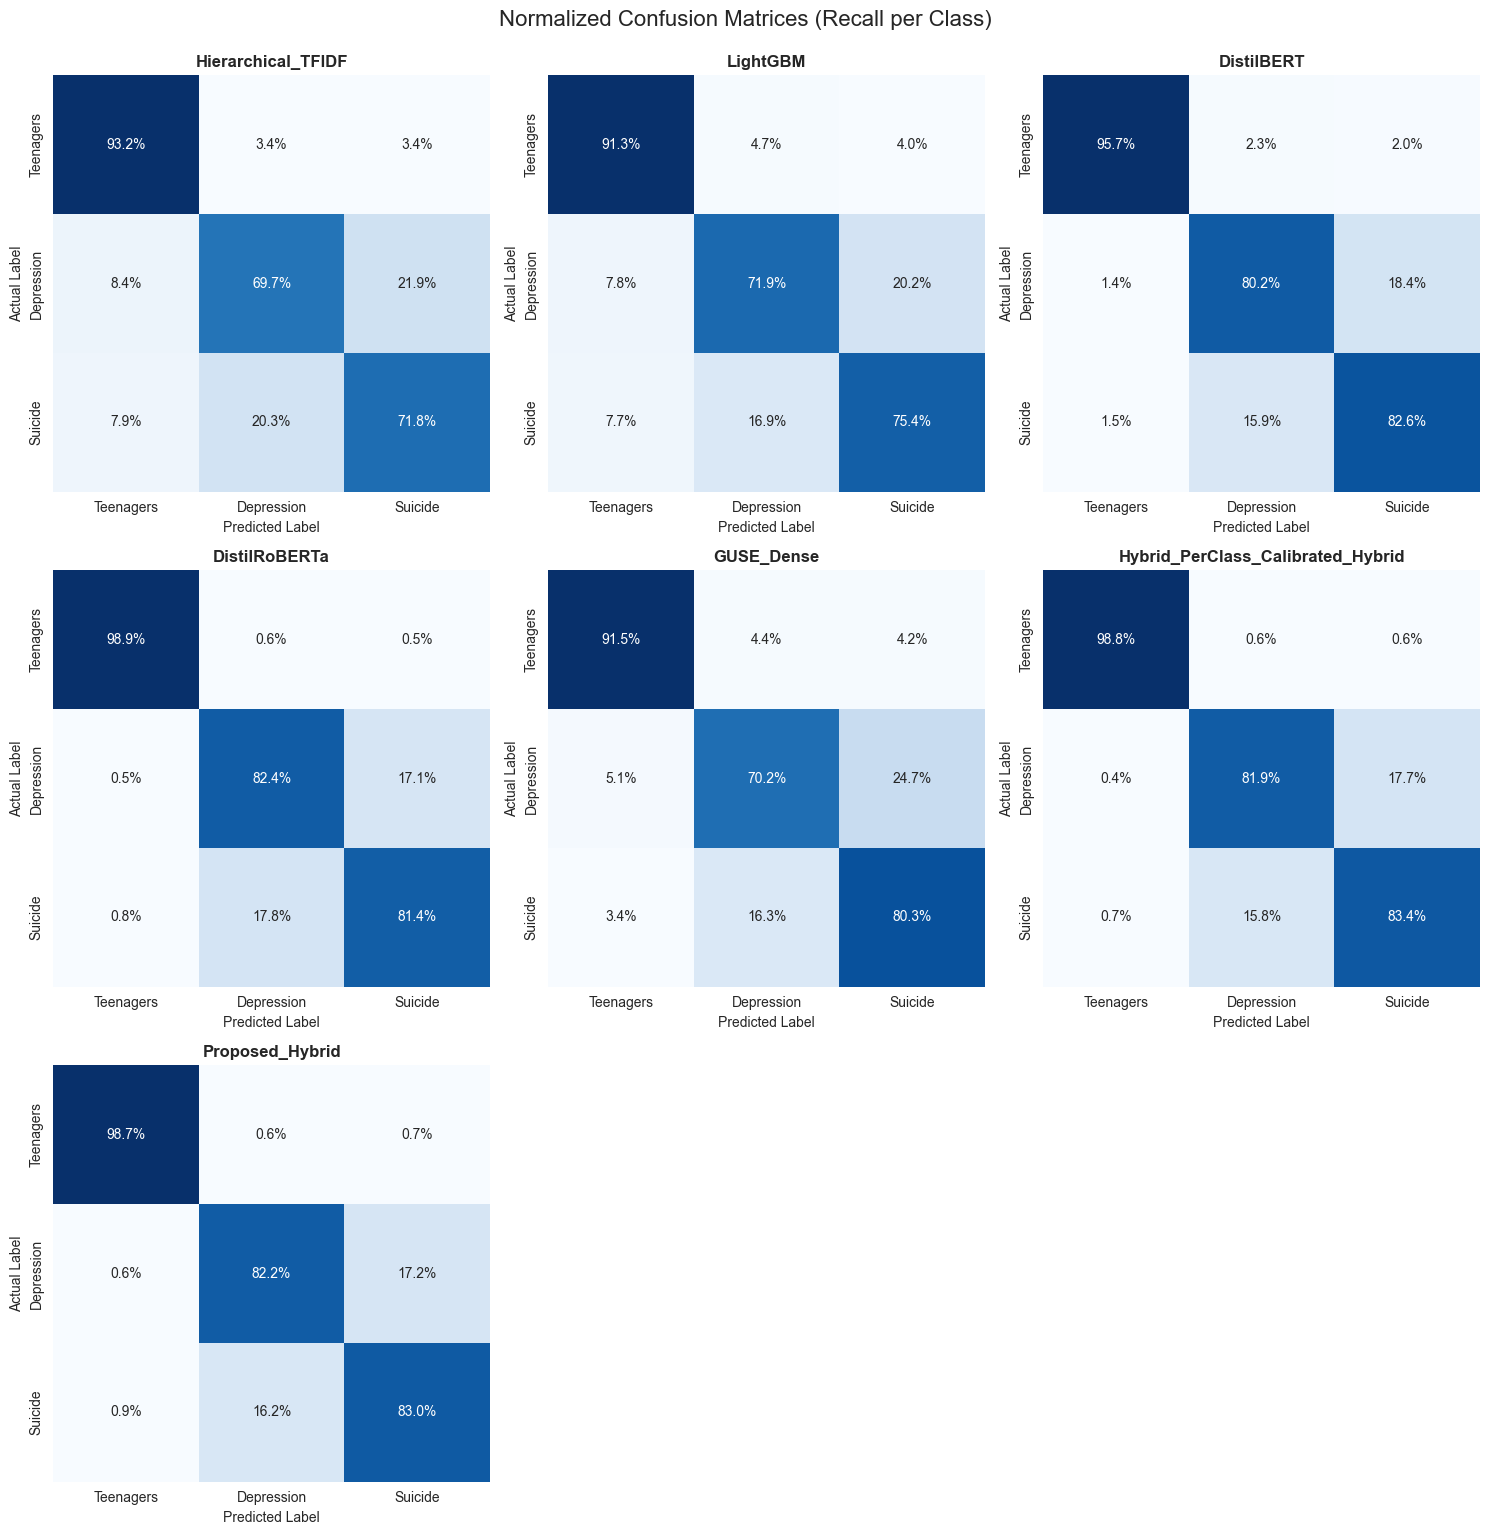

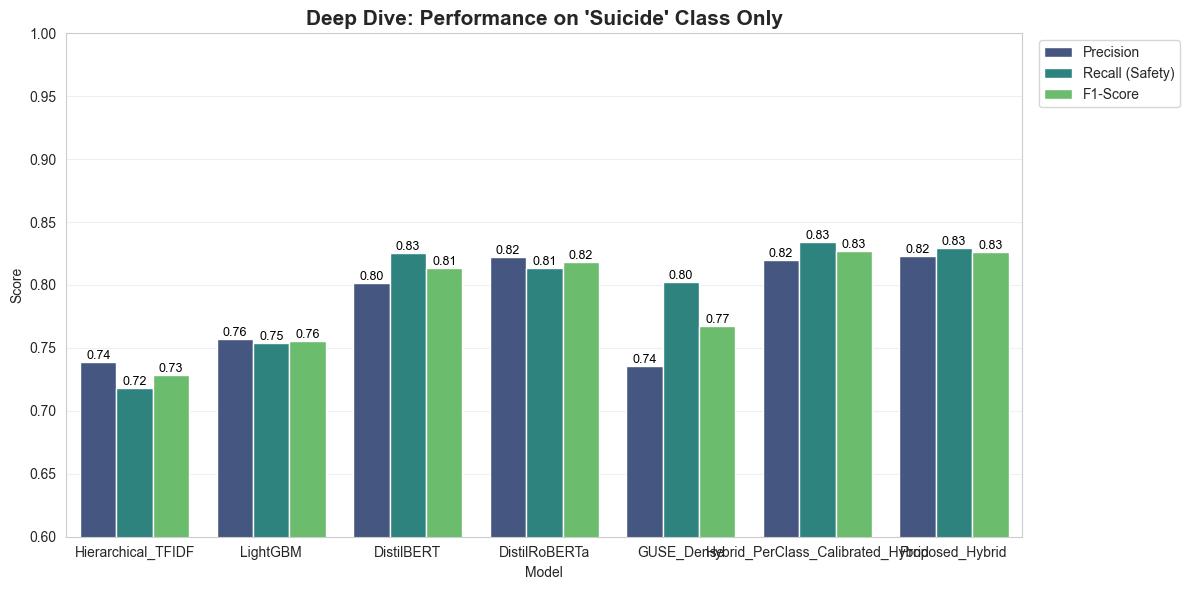

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import math
import os

# ==========================================
# 1. LOAD DATA
# ==========================================
filename = "all_models_results_compare_v13.csv" # 
if not os.path.exists(filename):
    print("❌ Error: CSV file not found.")
    exit()

df = pd.read_csv(filename)
y_true = df['True_Labels'].values

# Filter for prediction columns
model_cols = [c for c in df.columns if c.startswith('Pred_')]
model_names = [c.replace('Pred_', '') for c in model_cols]

# ==========================================
# PLOT 1: NORMALIZED CONFUSION MATRIX GRID
# ==========================================
# This shows "Where does the model get confused?"
# ------------------------------------------
n_models = len(model_names)
cols = 3
rows = math.ceil(n_models / cols)
target_names = ['Teenagers', 'Depression', 'Suicide']

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

for i, model in enumerate(model_names):
    col_name = f'Pred_{model}'
    y_pred = df[col_name].values
    
    # Normalize by 'true' (rows sum to 1) to show Recall per class
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='.1%', 
        cmap='Blues', 
        xticklabels=target_names, 
        yticklabels=target_names,
        ax=axes[i],
        cbar=False
    )
    axes[i].set_title(f"{model}", fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Actual Label')
    axes[i].set_xlabel('Predicted Label')

# Hide empty subplots if any
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle("Normalized Confusion Matrices (Recall per Class)", y=1.02, fontsize=16)
plt.show()

# ==========================================
# PLOT 2: SUICIDE CLASS DEEP DIVE
# ==========================================
# This compares models specifically on the most important class
# ------------------------------------------
stats = []

for model in model_names:
    y_pred = df[f'Pred_{model}'].values
    report = classification_report(y_true, y_pred, output_dict=True)
    
    # Extract metrics specifically for Class 2 (Suicide)
    # Note: Keys might be '2' or '2.0' depending on pandas version
    suicide_stats = report.get('2', report.get('2.0', {}))
    
    stats.append({
        'Model': model,
        'Precision': suicide_stats['precision'],
        'Recall (Safety)': suicide_stats['recall'],
        'F1-Score': suicide_stats['f1-score']
    })

df_suicide = pd.DataFrame(stats)

# Melt for plotting
df_melted = df_suicide.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 6))
sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="viridis")

# Annotate bars
for p in plt.gca().patches:
    if p.get_height() > 0:
        plt.gca().annotate(
            f'{p.get_height():.2f}', 
            (p.get_x() + p.get_width() / 2., p.get_height()), 
            ha='center', va='bottom', fontsize=9, color='black'
        )

plt.title("Deep Dive: Performance on 'Suicide' Class Only", fontsize=15, fontweight='bold')
plt.ylim(0.6, 1.0)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
import pandas as pd
import numpy as np
from statsmodels.stats.contingency_tables import mcnemar
import seaborn as sns
import matplotlib.pyplot as plt

# Load your results
df = pd.read_csv("all_models_results_compare_v13.csv")
y_true = df['True_Labels'].values

# Define the two models to compare (Best vs. Baseline)
model_1 = 'Pred_Hierarchical_TFIDF'  # Baseline
# Compare against the Proposed Hybrid (this column only exists after the
# "Hybrid Fusion" section's final test-set evaluation cell has been run).
model_2 = 'Pred_Proposed_Hybrid' if 'Pred_Proposed_Hybrid' in df.columns else 'Pred_DistilRoBERTa'
print(f"Comparing {model_1} vs {model_2}")

# Create Contigency Table
# Yes/Yes: Both Correct
# Yes/No: Model 1 Correct, Model 2 Wrong
# No/Yes: Model 1 Wrong, Model 2 Correct
# No/No: Both Wrong
m1_correct = (df[model_1] == y_true)
m2_correct = (df[model_2] == y_true)

a = sum(m1_correct & m2_correct)
b = sum(m1_correct & ~m2_correct)
c = sum(~m1_correct & m2_correct)
d = sum(~m1_correct & ~m2_correct)

table = [[a, b], [c, d]]

# Run Test
result = mcnemar(table, exact=True)

print(f"⚔️ McNemar's Test: {model_1} vs {model_2}")
print(f"p-value: {result.pvalue:.20f}")

if result.pvalue < 0.05:
    print(f"✅ RESULT: Statistically significant difference between {model_1} and {model_2}.")
else:
    print("❌ RESULT: Not statistically significant.")

Comparing Pred_Hierarchical_TFIDF vs Pred_Proposed_Hybrid
⚔️ McNemar's Test: Pred_Hierarchical_TFIDF vs Pred_Proposed_Hybrid
p-value: 0.00000000000000000000
✅ RESULT: Statistically significant difference between Pred_Hierarchical_TFIDF and Pred_Proposed_Hybrid.


In [66]:
# ============================================================
# McNEMAR TEST:
# DISTILROBERTA vs PROPOSED HYBRID
# ============================================================

import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar

# ------------------------------------------------------------
# 1. LOAD SAVED TEST PREDICTIONS
# ------------------------------------------------------------

RESULTS_FILE = "all_models_results_compare_v13.csv"

df = pd.read_csv(RESULTS_FILE)

if "True_Labels" not in df.columns:
    raise ValueError(
        "The CSV does not contain the required 'True_Labels' column."
    )

y_true = df["True_Labels"].to_numpy()


# ------------------------------------------------------------
# 2. IDENTIFY PREDICTION COLUMNS
# ------------------------------------------------------------

distilroberta_column = "Pred_DistilRoBERTa"

# Possible names created by different hybrid-saving cells
hybrid_candidates = [
    "Pred_Proposed_Hybrid",
    "Pred_Hybrid_PerClass_Calibrated_Hybrid",
    "Pred_Hybrid_Global_Alpha_Hybrid",
    "Pred_Proposed_Hybrid_EndToEnd"
]

if distilroberta_column not in df.columns:
    raise ValueError(
        f"Missing column: {distilroberta_column}\n"
        f"Available prediction columns:\n"
        f"{[column for column in df.columns if column.startswith('Pred_')]}"
    )

hybrid_column = next(
    (
        column
        for column in hybrid_candidates
        if column in df.columns
    ),
    None
)

if hybrid_column is None:
    raise ValueError(
        "No proposed-hybrid prediction column was found.\n"
        "Available prediction columns:\n"
        f"{[column for column in df.columns if column.startswith('Pred_')]}"
    )

print("McNemar comparison:")
print(f"  Model 1: {distilroberta_column}")
print(f"  Model 2: {hybrid_column}")


# ------------------------------------------------------------
# 3. REMOVE INVALID OR MISSING ROWS
# ------------------------------------------------------------

comparison_df = df[
    [
        "True_Labels",
        distilroberta_column,
        hybrid_column
    ]
].dropna()

y_true_clean = comparison_df["True_Labels"].to_numpy()

distilroberta_predictions = comparison_df[
    distilroberta_column
].to_numpy()

hybrid_predictions = comparison_df[
    hybrid_column
].to_numpy()


# ------------------------------------------------------------
# 4. DETERMINE CORRECT/INCORRECT PREDICTIONS
# ------------------------------------------------------------

distilroberta_correct = (
    distilroberta_predictions == y_true_clean
)

hybrid_correct = (
    hybrid_predictions == y_true_clean
)

# a: both models correct
a = int(
    np.sum(
        distilroberta_correct
        & hybrid_correct
    )
)

# b: DistilRoBERTa correct, hybrid incorrect
b = int(
    np.sum(
        distilroberta_correct
        & ~hybrid_correct
    )
)

# c: DistilRoBERTa incorrect, hybrid correct
c = int(
    np.sum(
        ~distilroberta_correct
        & hybrid_correct
    )
)

# d: both models incorrect
d = int(
    np.sum(
        ~distilroberta_correct
        & ~hybrid_correct
    )
)

contingency_table = [
    [a, b],
    [c, d]
]


# ------------------------------------------------------------
# 5. DISPLAY CONTINGENCY TABLE
# ------------------------------------------------------------

table_df = pd.DataFrame(
    contingency_table,
    index=[
        "DistilRoBERTa Correct",
        "DistilRoBERTa Incorrect"
    ],
    columns=[
        "Hybrid Correct",
        "Hybrid Incorrect"
    ]
)

print("\nContingency table:")
print(table_df)

print("\nDiscordant predictions:")
print(
    f"DistilRoBERTa correct, hybrid wrong: {b:,}"
)
print(
    f"DistilRoBERTa wrong, hybrid correct: {c:,}"
)


# ------------------------------------------------------------
# 6. RUN McNEMAR TEST
# ------------------------------------------------------------

discordant_total = b + c

if discordant_total == 0:
    raise ValueError(
        "The two models have identical correctness patterns; "
        "McNemar's test cannot distinguish them."
    )

# Exact test for small discordant counts;
# continuity-corrected chi-square for larger counts.
if discordant_total < 25:
    test_method = "Exact binomial McNemar test"

    result = mcnemar(
        contingency_table,
        exact=True
    )

else:
    test_method = (
        "Asymptotic McNemar test with "
        "continuity correction"
    )

    result = mcnemar(
        contingency_table,
        exact=False,
        correction=True
    )


# ------------------------------------------------------------
# 7. PRINT STATISTICAL RESULTS
# ------------------------------------------------------------

alpha_level = 0.05

print(f"\n{'=' * 65}")
print("McNemar Test: DistilRoBERTa vs Proposed Hybrid")
print(f"{'=' * 65}")
print(f"Method:             {test_method}")
print(f"Test samples:       {len(comparison_df):,}")
print(f"Discordant pairs:   {discordant_total:,}")
print(f"Test statistic:     {float(result.statistic):.6f}")
print(f"p-value:            {float(result.pvalue):.12g}")

if result.pvalue < alpha_level:
    print(
        "\nResult: The difference in prediction correctness "
        "is statistically significant at α = 0.05."
    )
else:
    print(
        "\nResult: The difference in prediction correctness "
        "is not statistically significant at α = 0.05."
    )


# ------------------------------------------------------------
# 8. INTERPRET DIRECTION OF DIFFERENCE
# ------------------------------------------------------------

if c > b:
    print(
        f"The proposed hybrid corrected {c:,} cases that "
        f"DistilRoBERTa missed, while DistilRoBERTa corrected "
        f"{b:,} cases that the hybrid missed."
    )

    print(
        "Direction: The proposed hybrid performed better "
        "on the discordant test cases."
    )

elif b > c:
    print(
        f"DistilRoBERTa corrected {b:,} cases that the "
        f"hybrid missed, while the proposed hybrid corrected "
        f"{c:,} cases that DistilRoBERTa missed."
    )

    print(
        "Direction: DistilRoBERTa performed better "
        "on the discordant test cases."
    )

else:
    print(
        "Both models have the same number of uniquely "
        "correct predictions."
    )

print(f"{'=' * 65}")

McNemar comparison:
  Model 1: Pred_DistilRoBERTa
  Model 2: Pred_Proposed_Hybrid

Contingency table:
                         Hybrid Correct  Hybrid Incorrect
DistilRoBERTa Correct             44979               737
DistilRoBERTa Incorrect             944              5556

Discordant predictions:
DistilRoBERTa correct, hybrid wrong: 737
DistilRoBERTa wrong, hybrid correct: 944

McNemar Test: DistilRoBERTa vs Proposed Hybrid
Method:             Asymptotic McNemar test with continuity correction
Test samples:       52,216
Discordant pairs:   1,681
Test statistic:     25.244497
p-value:            5.0503452029e-07

Result: The difference in prediction correctness is statistically significant at α = 0.05.
The proposed hybrid corrected 944 cases that DistilRoBERTa missed, while DistilRoBERTa corrected 737 cases that the hybrid missed.
Direction: The proposed hybrid performed better on the discordant test cases.


In [67]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import pickle
from scipy.special import softmax
from simpletransformers.classification import ClassificationModel
from sklearn.feature_extraction.text import TfidfVectorizer

class HybridSuicideDetector:
    """
    Proposed Architecture: Hybrid Semantic-Statistical Framework
    
    A dual-stream classifier that fuses:
    1. Statistical Stream: TF-IDF + LightGBM (Captures explicit keywords)
    2. Semantic Stream: DistilRoBERTa (Captures implicit context)
    
    Attributes:
        alpha (float): The fusion weight (fraction assigned to the
                       Semantic/DistilRoBERTa stream; the rest goes to the
                       Statistical/LightGBM stream). Selected on the
                       VALIDATION set in the "Hybrid Fusion" section of
                       this notebook -- see hybrid_alpha_config_v13.json.
    """
    
    def __init__(self, alpha=None):
        # If no alpha is given, load the value selected on the VALIDATION
        # set in the "Hybrid Fusion" section of this notebook, instead of
        # hardcoding a number here that could drift out of sync with it.
        if alpha is None:
            try:
                import json
                with open("hybrid_alpha_config_v13.json") as f:
                    alpha = json.load(f)["best_alpha"]
                print(f"⚙️ Loaded validated alpha={alpha} from hybrid_alpha_config_v13.json")
            except FileNotFoundError:
                alpha = 0.5
                print("⚠️ hybrid_alpha_config_v13.json not found — run the alpha-selection "
                      "cell first. Falling back to alpha=0.5 for now.")
        self.alpha = alpha
        self.lgbm_model = None
        self.tfidf_vectorizer = None
        self.roberta_model = None
        self.is_fitted = False

    def load_components(self, lgbm_path, tfidf_path, roberta_path):
        """
        Loads the pre-trained components for both streams.
        """
        print("⚙️ Loading Statistical Stream (LightGBM)...")
        self.lgbm_model = lgb.Booster(model_file=lgbm_path)
        with open(tfidf_path, 'rb') as f:
            self.tfidf_vectorizer = pickle.load(f)

        print("⚙️ Loading Semantic Stream (DistilRoBERTa)...")
        self.roberta_model = ClassificationModel(
            'roberta', roberta_path, use_cuda=True, args={'silent': True}
        )
        self.is_fitted = True
        print("✅ Hybrid Architecture Ready.")

    def _get_statistical_probs(self, text_list):
        """Internal method to get P_stat from Stream A"""
        # Vectorize (20k Features, N-gram 1-2)
        vectors = self.tfidf_vectorizer.transform(text_list)
        # Predict
        probs = self.lgbm_model.predict(vectors)
        return probs

    def _get_semantic_probs(self, text_list):
        """Internal method to get P_sem from Stream B"""
        # SimpleTransformers handles tokenization internally
        _, model_outputs, _ = self.roberta_model.eval_model(
            pd.DataFrame({'text': text_list, 'labels': [0]*len(text_list)}),
            verbose=False
        )
        # Apply Softmax to convert logits to probabilities
        probs = softmax(model_outputs, axis=1)
        return probs

    def predict_proba(self, text_list):
        """
        Executes the Dual-Stream Forward Pass and Fusion.
        """
        if not self.is_fitted:
            raise ValueError("Model not loaded! Call load_components() first.")

        # 1. Parallel Execution
        p_stat = self._get_statistical_probs(text_list)
        p_sem = self._get_semantic_probs(text_list)

        # 2. Fusion Layer (Weighted Soft-Voting)
        # Formula: P_final = α * P_sem + (1-α) * P_stat
        p_final = (self.alpha * p_sem) + ((1 - self.alpha) * p_stat)
        
        return p_final

    def predict(self, text_list):
        """
        Returns final class labels: 0 (Teen), 1 (Depression), 2 (Suicide)
        """
        probs = self.predict_proba(text_list)
        return np.argmax(probs, axis=1)

# ==========================================
# EXAMPLE USAGE (For your Paper/Notebook)
# ==========================================
if __name__ == "__main__":
    # 1. Instantiate the Proposed Architecture
    # alpha is loaded automatically from hybrid_alpha_config_v13.json (the value
    # selected on the validation set) unless you pass one explicitly.
    model = HybridSuicideDetector()

    # 2. Simulate Loading (In a real run, you would provide paths)
    # model.load_components('lgbm_model.txt', 'tfidf.pkl', 'outputs/')

    # 3. Simulate Inference on the "Hard Cases" you mentioned
    sample_texts = [
        "I am done with this game",       # Semantic case (Implicit)
        "Plan: exit bag, nitrogen",       # Statistical case (Keyword heavy)
        "I am so happy today!"            # Neutral
    ]

    print(f"🚀 Running Hybrid Inference (Alpha={model.alpha})...")

    # NOTE: Since we don't have paths loaded in this snippet, we simulate
    # the math using the roberta_test_probs / lgbm_test_probs arrays
    # produced earlier in this notebook's Hybrid Fusion section, to show
    # the fusion logic working end-to-end:
    try:
        p_roberta = roberta_test_probs[:3]
        p_lgbm = lgbm_test_probs[:3]

        # Apply Fusion using the SAME alpha as the rest of the notebook
        final_probs = (model.alpha * p_roberta) + ((1 - model.alpha) * p_lgbm)
        predictions = np.argmax(final_probs, axis=1)

        classes = ['Teenagers', 'Depression', 'Suicide']
        for text, pred in zip(sample_texts, predictions):
            print(f"Input: '{text}' -> Prediction: {classes[pred]}")

    except NameError:
        print("⚠️ 'roberta_test_probs' / 'lgbm_test_probs' not found. "
              "Run this in your main notebook context, after the Hybrid "
              "Fusion section has run.")

⚙️ Loaded validated alpha=0.56 from hybrid_alpha_config_v13.json
🚀 Running Hybrid Inference (Alpha=0.56)...
Input: 'I am done with this game' -> Prediction: Teenagers
Input: 'Plan: exit bag, nitrogen' -> Prediction: Depression
Input: 'I am so happy today!' -> Prediction: Depression


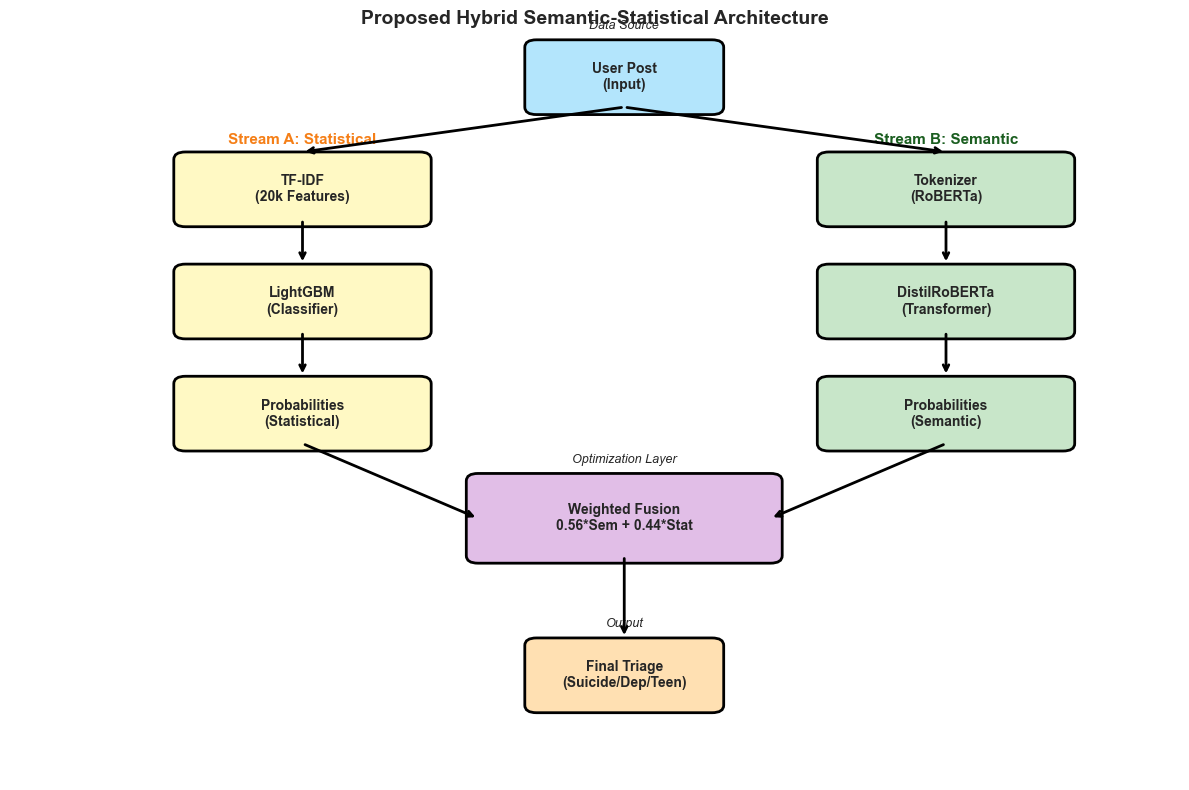

✅ Figure 1 Saved as 'fig1_architecture_diagram.png'


In [68]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_architecture_diagram(alpha=None):
    # Load the validated alpha so the diagram's label always matches the
    # value actually used elsewhere in the notebook (instead of a stale
    # hardcoded number).
    if alpha is None:
        try:
            import json
            with open("hybrid_alpha_config_v13.json") as f:
                alpha = json.load(f)["best_alpha"]
        except FileNotFoundError:
            alpha = None  # fall back to a symbolic label below

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')

    # Helper function to draw box with text
    def draw_box(x, y, width, height, color, text, title=""):
        # Box
        rect = patches.FancyBboxPatch((x, y), width, height, boxstyle="round,pad=0.1", 
                                      linewidth=2, edgecolor='black', facecolor=color)
        ax.add_patch(rect)
        # Text
        ax.text(x + width/2, y + height/2, text, ha='center', va='center', fontsize=10, fontweight='bold')
        # Title (optional)
        if title:
            ax.text(x + width/2, y + height + 0.2, title, ha='center', va='bottom', fontsize=9, fontstyle='italic')

    # arrow helper
    def draw_arrow(x1, y1, x2, y2):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="->", lw=2, color='black'))

    # 1. Input
    draw_box(4.5, 9, 1.5, 0.8, '#B3E5FC', "User Post\n(Input)", "Data Source")

    # 2. Stream A (Left - Statistical)
    ax.text(2.5, 8.5, "Stream A: Statistical", ha='center', fontsize=11, fontweight='bold', color='#F57F17')
    draw_box(1.5, 7.5, 2.0, 0.8, '#FFF9C4', "TF-IDF\n(20k Features)")
    draw_box(1.5, 6.0, 2.0, 0.8, '#FFF9C4', "LightGBM\n(Classifier)")
    draw_box(1.5, 4.5, 2.0, 0.8, '#FFF9C4', "Probabilities\n(Statistical)")

    # 3. Stream B (Right - Semantic)
    ax.text(8.0, 8.5, "Stream B: Semantic", ha='center', fontsize=11, fontweight='bold', color='#1B5E20')
    draw_box(7.0, 7.5, 2.0, 0.8, '#C8E6C9', "Tokenizer\n(RoBERTa)")
    draw_box(7.0, 6.0, 2.0, 0.8, '#C8E6C9', "DistilRoBERTa\n(Transformer)")
    draw_box(7.0, 4.5, 2.0, 0.8, '#C8E6C9', "Probabilities\n(Semantic)")

    # 4. Fusion Layer (Center)
    if alpha is not None:
        fusion_label = f"Weighted Fusion\n{alpha:.2f}*Sem + {1-alpha:.2f}*Stat"
    else:
        fusion_label = "Weighted Fusion\nα*Sem + (1-α)*Stat"
    draw_box(4.0, 3.0, 2.5, 1.0, '#E1BEE7', fusion_label, "Optimization Layer")

    # 5. Output
    draw_box(4.5, 1.0, 1.5, 0.8, '#FFE0B2', "Final Triage\n(Suicide/Dep/Teen)", "Output")

    # --- ARROWS ---
    # Input split
    draw_arrow(5.25, 9.0, 2.5, 8.4) # To A
    draw_arrow(5.25, 9.0, 8.0, 8.4) # To B

    # Stream A Flow
    draw_arrow(2.5, 7.5, 2.5, 6.9)
    draw_arrow(2.5, 6.0, 2.5, 5.4)
    draw_arrow(2.5, 4.5, 4.0, 3.5) # To Fusion

    # Stream B Flow
    draw_arrow(8.0, 7.5, 8.0, 6.9)
    draw_arrow(8.0, 6.0, 8.0, 5.4)
    draw_arrow(8.0, 4.5, 6.5, 3.5) # To Fusion

    # Output Flow
    draw_arrow(5.25, 3.0, 5.25, 1.9)

    plt.title("Proposed Hybrid Semantic-Statistical Architecture", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('fig1_architecture_diagram.png', dpi=300)
    plt.show()
    print("✅ Figure 1 Saved as 'fig1_architecture_diagram.png'")

# Run it
draw_architecture_diagram()

In [ ]:
!pip install shap lime

Found lgbm_model_saved AND roberta_model_saved -- running full SHAP + LIME + fusion pipeline.

Computing SHAP values for LightGBM (TF-IDF stream)...


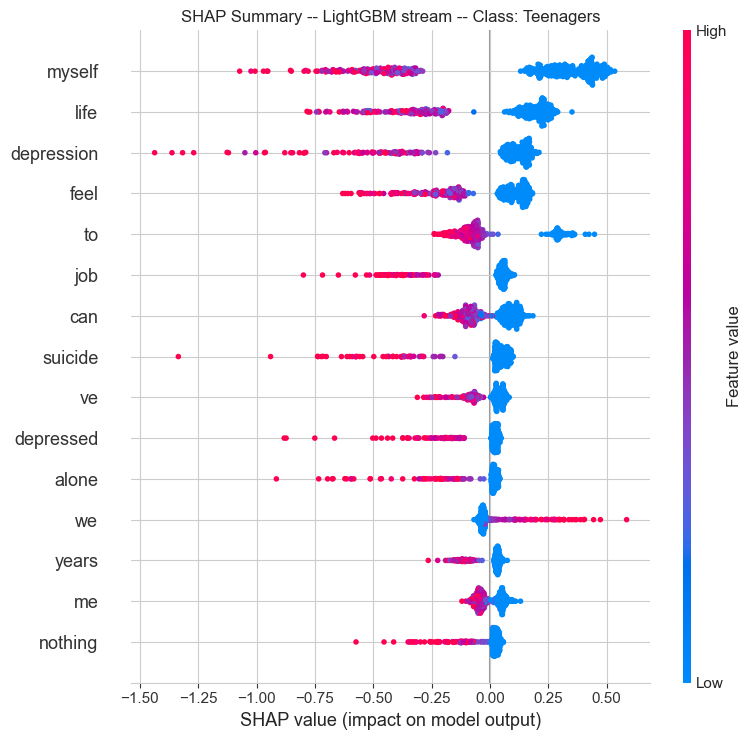

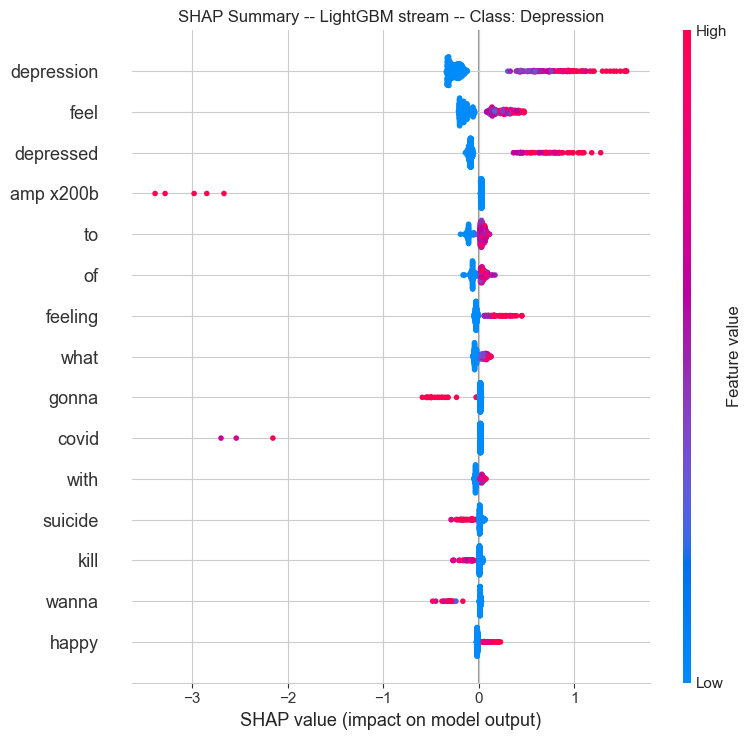

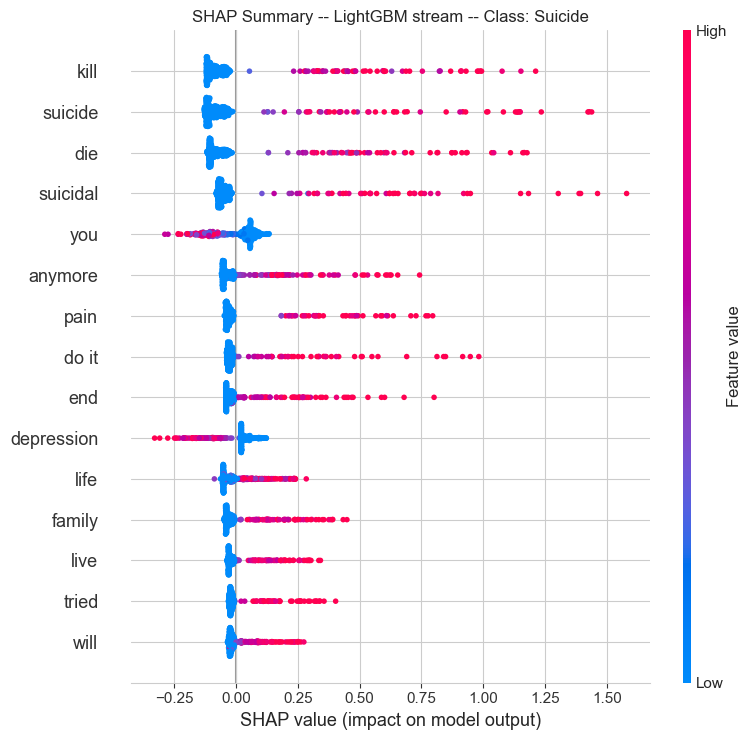

Saved SHAP summary plots for each class.

Setting up LIME explainer for DistilRoBERTa...

EXPLAINING TEST EXAMPLE #0
Text: Online P.E. class is the most meta shit Online p.e. Class is the most meta shit ever. My PE teacher plays videos on zoom where the trainer is doing workouts and we're supposed to do it at home, and th
True label: Teenagers

LightGBM stream prediction: Teenagers
Probs: {'Teenagers': np.float32(0.937), 'Depression': np.float32(0.026), 'Suicide': np.float32(0.037)}

Top 10 TF-IDF features driving LightGBM's 'Teenagers' prediction:
  00100000   SHAP=0.0  (pushes away from Teenagers)
  000   SHAP=0.0  (pushes away from Teenagers)
  00   SHAP=0.0  (pushes away from Teenagers)

Generating LIME explanation for DistilRoBERTa (may take ~10-20s)...


INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Predicting:   0%|          | 0/625 [00:00<?, ?it/s]


Top words driving RoBERTa's prediction for class 'Teenagers':
  E   weight=-0.0159  (opposes 'Teenagers')
  meta   weight=0.0127  (supports 'Teenagers')
  P   weight=0.0125  (supports 'Teenagers')
  class   weight=0.0077  (supports 'Teenagers')
  Class   weight=0.0077  (supports 'Teenagers')
  zoom   weight=0.0069  (supports 'Teenagers')
  Online   weight=0.0063  (supports 'Teenagers')
  shit   weight=0.0052  (supports 'Teenagers')
  bed   weight=-0.004  (opposes 'Teenagers')
  videos   weight=0.0039  (supports 'Teenagers')
Saved interactive LIME explanation to lime_explanation_example_0.html

FUSION BREAKDOWN (alpha = 0.56)
     Class  RoBERTa_prob  LightGBM_prob  Hybrid_prob
 Teenagers        0.9997         0.9374       0.9723
Depression        0.0002         0.0258       0.0115
   Suicide        0.0001         0.0368       0.0163

Final Hybrid prediction: Teenagers  (True label: Teenagers)
RoBERTa contributed 56% weight, LightGBM contributed 44% weight


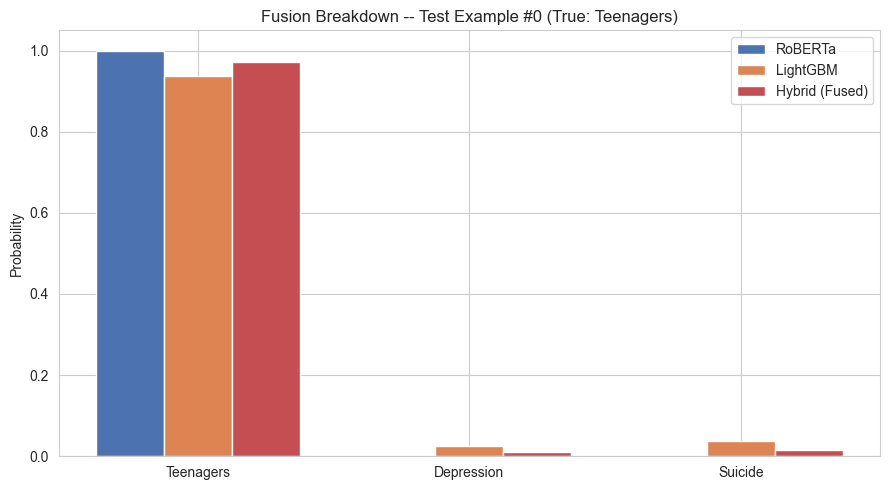


Explainability pipeline complete.
Generated: shap_summary_<class>.png (x3), lime_explanation_example_N.html, fusion_breakdown_example_N.png


In [69]:
# ══════════════════════════════════════════════════════════
# Explainable AI for the Proposed Hybrid Model — FULL, FIXED VERSION
# (dense-array fix applied for SHAP + sparse TF-IDF/LightGBM compatibility)
# ══════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_text import LimeTextExplainer

target_names = ['Teenagers', 'Depression', 'Suicide']

# ──────────────────────────────────────────────────────────
# STEP 0: Check what's available — fail gracefully, never crash
# ──────────────────────────────────────────────────────────
if 'lgbm_model_saved' not in dir():
    raise NameError(
        "lgbm_model_saved not found. Run the LightGBM retrain block first:\n"
        "  import lightgbm as lgb\n"
        "  lgbm_model_saved = lgb.LGBMClassifier(...); lgbm_model_saved.fit(...)"
    )

roberta_available = 'roberta_model_saved' in dir()
if roberta_available:
    print("Found lgbm_model_saved AND roberta_model_saved -- running full SHAP + LIME + fusion pipeline.")
else:
    print("lgbm_model_saved found, but roberta_model_saved is NOT available.")
    print("   -> SHAP (LightGBM) and the fusion breakdown will still run normally.")
    print("   -> LIME (RoBERTa) will be SKIPPED -- to enable it, re-run Cell 12, then run:")
    print("       roberta_model_saved = model")
    print("     and re-run this cell.")

# ──────────────────────────────────────────────────────────
# PART A: SHAP -- global feature importance for the LightGBM/TF-IDF stream
# ──────────────────────────────────────────────────────────
print("\nComputing SHAP values for LightGBM (TF-IDF stream)...")

explainer_shap = shap.TreeExplainer(lgbm_model_saved)

sample_idx = np.random.RandomState(42).choice(
    X_test_vec.shape[0], size=min(500, X_test_vec.shape[0]), replace=False
)

X_sample = X_test_vec[sample_idx].toarray()

shap_values = explainer_shap.shap_values(X_sample)
feature_names = tfidf.get_feature_names_out()

for c, class_name in enumerate(target_names):
    plt.figure()
    shap.summary_plot(
        shap_values[c] if isinstance(shap_values, list) else shap_values[:, :, c],
        X_sample,
        feature_names=feature_names,
        max_display=15,
        show=False
    )
    plt.title("SHAP Summary -- LightGBM stream -- Class: " + class_name)
    plt.tight_layout()
    plt.savefig("shap_summary_" + class_name + ".png", dpi=200, bbox_inches="tight")
    plt.show()

print("Saved SHAP summary plots for each class.")

# ──────────────────────────────────────────────────────────
# PART B: LIME setup -- only if RoBERTa is available
# ──────────────────────────────────────────────────────────
if roberta_available:
    print("\nSetting up LIME explainer for DistilRoBERTa...")

    def roberta_predict_proba(texts):
        _, raw_outputs = roberta_model_saved.predict(list(texts))
        exp_logits = np.exp(raw_outputs - np.max(raw_outputs, axis=1, keepdims=True))
        return exp_logits / exp_logits.sum(axis=1, keepdims=True)

    lime_explainer = LimeTextExplainer(class_names=target_names)

# ──────────────────────────────────────────────────────────
# PART C: Full explanation for a single chosen example
# ──────────────────────────────────────────────────────────
example_idx = 0
example_text = test_df['text'].iloc[example_idx]
true_label = target_names[int(y_test_truth[example_idx])]

print("\n" + "=" * 70)
print("EXPLAINING TEST EXAMPLE #" + str(example_idx))
print("Text: " + example_text[:200])
print("True label: " + true_label)
print("=" * 70)

example_vec = X_test_vec[example_idx].toarray()
lgbm_pred_probs = lgbm_test_probs[example_idx]
lgbm_pred_class = np.argmax(lgbm_pred_probs)
print("\nLightGBM stream prediction: " + target_names[lgbm_pred_class])
print("Probs: " + str(dict(zip(target_names, np.round(lgbm_pred_probs, 3)))))

shap_values_single = explainer_shap.shap_values(example_vec)
class_idx = lgbm_pred_class
sv = shap_values_single[class_idx] if isinstance(shap_values_single, list) else shap_values_single[:, class_idx]
sv = np.array(sv).flatten()

top_n = 10
top_feature_idx = np.argsort(np.abs(sv))[-top_n:][::-1]
print("\nTop " + str(top_n) + " TF-IDF features driving LightGBM's '" + target_names[class_idx] + "' prediction:")
for idx in top_feature_idx:
    direction = "pushes toward" if sv[idx] > 0 else "pushes away from"
    print("  " + feature_names[idx] + "   SHAP=" + str(round(sv[idx], 4)) + "  (" + direction + " " + target_names[class_idx] + ")")

if roberta_available:
    print("\nGenerating LIME explanation for DistilRoBERTa (may take ~10-20s)...")
    lime_exp = lime_explainer.explain_instance(
        example_text,
        roberta_predict_proba,
        num_features=10,
        labels=[int(y_test_truth[example_idx])]
    )
    print("\nTop words driving RoBERTa's prediction for class '" + true_label + "':")
    for word, weight in lime_exp.as_list(label=int(y_test_truth[example_idx])):
        direction = "supports" if weight > 0 else "opposes"
        print("  " + word + "   weight=" + str(round(weight, 4)) + "  (" + direction + " '" + true_label + "')")

    lime_exp.save_to_file("lime_explanation_example_" + str(example_idx) + ".html")
    print("Saved interactive LIME explanation to lime_explanation_example_" + str(example_idx) + ".html")
else:
    print("\nSkipping LIME (roberta_model_saved not available this session).")

# ──────────────────────────────────────────────────────────
# PART D: Fusion-level breakdown
# ──────────────────────────────────────────────────────────
roberta_pred_probs = roberta_test_probs[example_idx]
hybrid_probs = (best_alpha * roberta_pred_probs) + ((1 - best_alpha) * lgbm_pred_probs)
final_pred = np.argmax(hybrid_probs)

print("\n" + "=" * 70)
print("FUSION BREAKDOWN (alpha = " + str(round(best_alpha, 2)) + ")")
print("=" * 70)
comparison_df = pd.DataFrame({
    "Class": target_names,
    "RoBERTa_prob": np.round(roberta_pred_probs, 4),
    "LightGBM_prob": np.round(lgbm_pred_probs, 4),
    "Hybrid_prob": np.round(hybrid_probs, 4),
})
print(comparison_df.to_string(index=False))
print("\nFinal Hybrid prediction: " + target_names[final_pred] + "  (True label: " + true_label + ")")
print("RoBERTa contributed " + str(round(best_alpha * 100)) + "% weight, LightGBM contributed " + str(round((1 - best_alpha) * 100)) + "% weight")

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(target_names))
width = 0.25
ax.bar(x - width, roberta_pred_probs, width, label='RoBERTa', color='#4C72B0')
ax.bar(x, lgbm_pred_probs, width, label='LightGBM', color='#DD8452')
ax.bar(x + width, hybrid_probs, width, label='Hybrid (Fused)', color='#C44E52')
ax.set_xticks(x)
ax.set_xticklabels(target_names)
ax.set_ylabel('Probability')
ax.set_title('Fusion Breakdown -- Test Example #' + str(example_idx) + ' (True: ' + true_label + ')')
ax.legend()
plt.tight_layout()
plt.savefig("fusion_breakdown_example_" + str(example_idx) + ".png", dpi=200, bbox_inches="tight")
plt.show()

print("\nExplainability pipeline complete.")
if roberta_available:
    print("Generated: shap_summary_<class>.png (x3), lime_explanation_example_N.html, fusion_breakdown_example_N.png")
else:
    print("Generated: shap_summary_<class>.png (x3), fusion_breakdown_example_N.png")
    print("(LIME output was skipped this run -- retrain RoBERTa and re-run to add it)")

In [70]:
# ══════════════════════════════════════════════════════════
# TRUE Hybrid Explainability — explains the FUSED prediction directly,
# not just the LightGBM component
# ══════════════════════════════════════════════════════════
import numpy as np
from lime.lime_text import LimeTextExplainer

if 'roberta_model_saved' not in dir():
    raise NameError(
        "roberta_model_saved not found. True Hybrid explanation needs BOTH "
        "streams live. Re-run Cell 12, then: roberta_model_saved = model"
    )

target_names = ['Teenagers', 'Depression', 'Suicide']

# This function IS your hybrid model, end to end: raw text -> fused probabilities.
# LIME will treat this entire thing as one black box.
def hybrid_predict_proba(texts):
    texts = list(texts)

    # LightGBM stream
    X_vec = tfidf.transform(texts).toarray()
    lgbm_probs = lgbm_model_saved.predict_proba(X_vec)

    # RoBERTa stream
    _, raw_outputs = roberta_model_saved.predict(texts)
    exp_logits = np.exp(raw_outputs - np.max(raw_outputs, axis=1, keepdims=True))
    roberta_probs = exp_logits / exp_logits.sum(axis=1, keepdims=True)

    # Fusion — the actual Hybrid decision
    return (best_alpha * roberta_probs) + ((1 - best_alpha) * lgbm_probs)

hybrid_lime_explainer = LimeTextExplainer(class_names=target_names)

example_idx = 0
example_text = test_df['text'].iloc[example_idx]
true_label = target_names[int(y_test_truth[example_idx])]

print("Explaining the HYBRID model's actual fused decision (not just LightGBM)")
print("Text:", example_text[:200])
print("True label:", true_label)

hybrid_exp = hybrid_lime_explainer.explain_instance(
    example_text,
    hybrid_predict_proba,
    num_features=10,
    labels=[int(y_test_truth[example_idx])]
)

print("\nTop words driving the HYBRID's prediction for class '" + true_label + "':")
for word, weight in hybrid_exp.as_list(label=int(y_test_truth[example_idx])):
    direction = "supports" if weight > 0 else "opposes"
    print("  " + word + "   weight=" + str(round(weight, 4)) + "  (" + direction + " '" + true_label + "')")

hybrid_exp.save_to_file("lime_HYBRID_explanation_example_" + str(example_idx) + ".html")
print("Saved lime_HYBRID_explanation_example_" + str(example_idx) + ".html")

Explaining the HYBRID model's actual fused decision (not just LightGBM)
Text: Online P.E. class is the most meta shit Online p.e. Class is the most meta shit ever. My PE teacher plays videos on zoom where the trainer is doing workouts and we're supposed to do it at home, and th
True label: Teenagers


INFO:simpletransformers.classification.classification_utils: Converting to features started. Cache is not used.


Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Predicting:   0%|          | 0/625 [00:00<?, ?it/s]


Top words driving the HYBRID's prediction for class 'Teenagers':
  teacher   weight=0.0341  (supports 'Teenagers')
  nothing   weight=-0.0198  (opposes 'Teenagers')
  zoom   weight=0.0178  (supports 'Teenagers')
  we   weight=0.015  (supports 'Teenagers')
  Class   weight=0.0121  (supports 'Teenagers')
  class   weight=0.0119  (supports 'Teenagers')
  do   weight=-0.0098  (opposes 'Teenagers')
  to   weight=-0.0087  (opposes 'Teenagers')
  E   weight=-0.0082  (opposes 'Teenagers')
  it   weight=-0.0082  (opposes 'Teenagers')
Saved lime_HYBRID_explanation_example_0.html


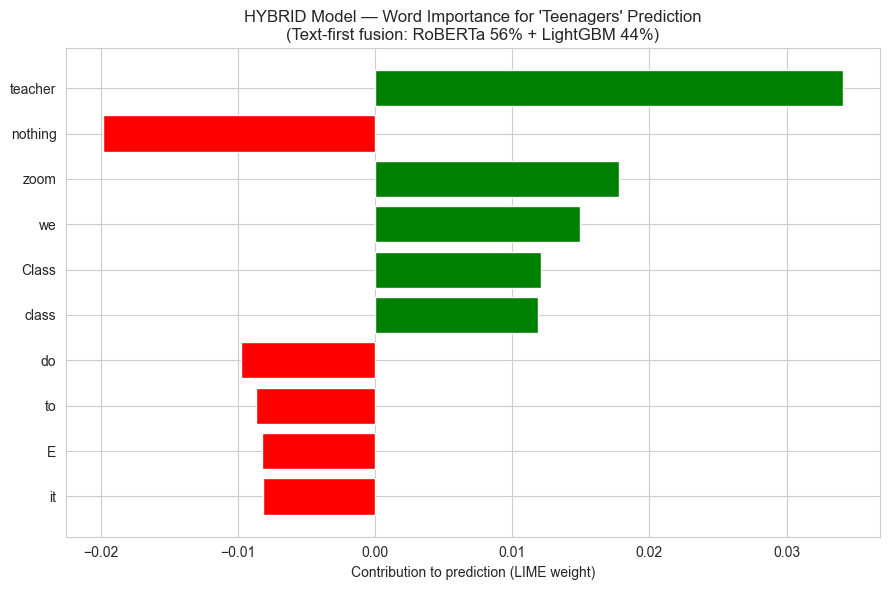

In [71]:
# ══════════════════════════════════════════════════════════
# Graph: Word-level importance for the HYBRID's fused decision
# ══════════════════════════════════════════════════════════
import matplotlib.pyplot as plt

# LIME's built-in plot — horizontal bar chart of word contributions
fig = hybrid_exp.as_pyplot_figure(label=int(y_test_truth[example_idx]))
fig.set_size_inches(9, 6)
plt.title(f"HYBRID Model — Word Importance for '{true_label}' Prediction\n(Text-first fusion: RoBERTa {best_alpha*100:.0f}% + LightGBM {(1-best_alpha)*100:.0f}%)")
plt.xlabel("Contribution to prediction (LIME weight)")
plt.tight_layout()
plt.savefig(f"hybrid_lime_wordimportance_example_{example_idx}.png", dpi=200, bbox_inches="tight")
plt.show()

Hybrid weights: DistilRoBERTa=0.56, LightGBM=0.44
Using fitted vectorizer: tfidf
Complete proposed-hybrid prediction function verified.
True proposed-hybrid SHAP explainer created.
Selected 24 texts for true-hybrid SHAP.

Calculating true proposed-hybrid SHAP values...
Internal SimpleTransformers progress bars are disabled.
Explaining document 24/24
True proposed-hybrid SHAP calculation completed.


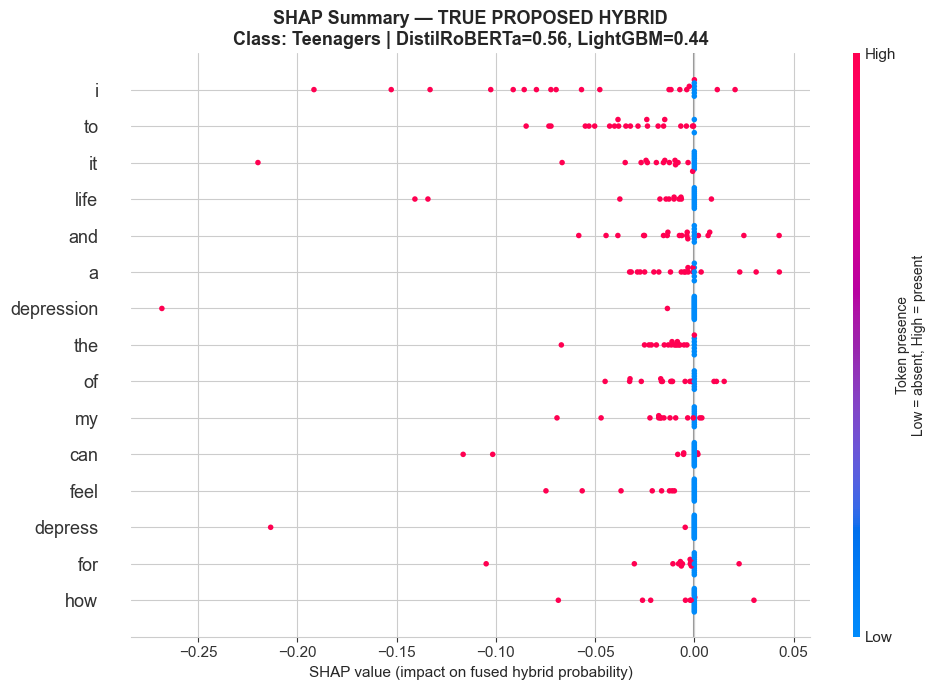

Saved: true_proposed_hybrid_shap_v13\shap_summary_TRUE_PROPOSED_HYBRID_Teenagers.png


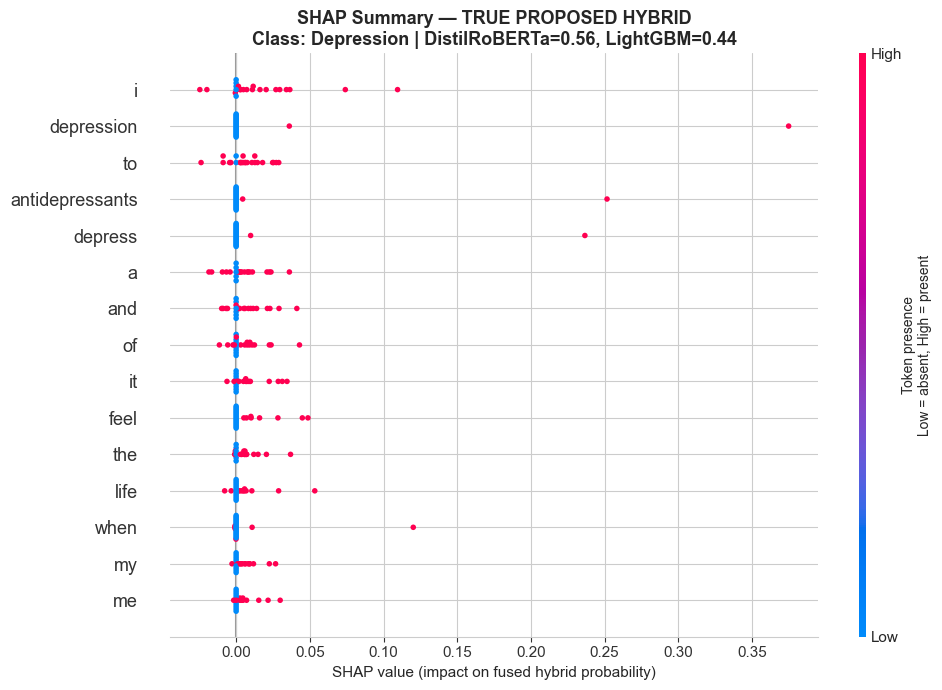

Saved: true_proposed_hybrid_shap_v13\shap_summary_TRUE_PROPOSED_HYBRID_Depression.png


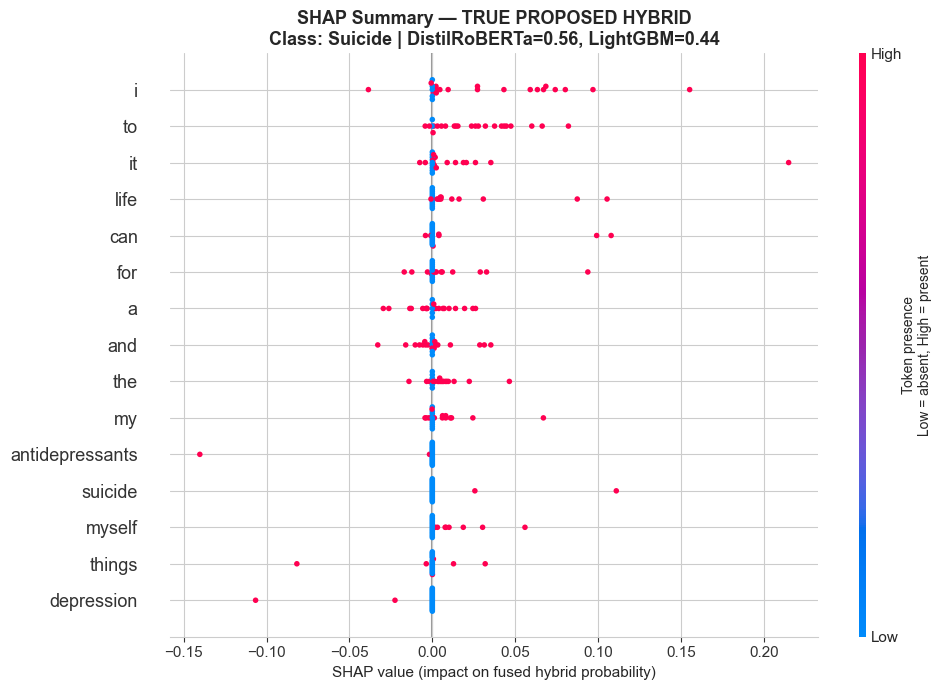

Saved: true_proposed_hybrid_shap_v13\shap_summary_TRUE_PROPOSED_HYBRID_Suicide.png

True proposed-hybrid SHAP completed successfully.
All figures and values were saved under:
true_proposed_hybrid_shap_v13


In [77]:
# ═══════════════════════════════════════════════════════════════
# TRUE PROPOSED HYBRID SHAP — QUIET VERSION
#
# Removes:
#   • Green "Map: 100%" progress bars
#   • "Converting to features started" messages
#   • SimpleTransformers prediction progress bars
#   • Hugging Face tokenizer/dataset progress bars
#
# Explains:
#   DistilRoBERTa + LightGBM probability fusion
# ═══════════════════════════════════════════════════════════════

# ============================================================
# STEP 1: IMPORTS AND GLOBAL OUTPUT SUPPRESSION
# ============================================================

import os

# Set before further model calls
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_DATASETS_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TQDM_DISABLE"] = "1"

import io
import re
import gc
import json
import logging
import warnings
from contextlib import contextmanager, redirect_stdout, redirect_stderr
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import torch


# Suppress warnings that do not affect the calculation
warnings.filterwarnings("ignore")


# Disable Hugging Face datasets progress bars
try:
    import datasets

    datasets.disable_progress_bar()
except Exception:
    try:
        from datasets.utils.logging import disable_progress_bar

        disable_progress_bar()
    except Exception:
        pass


# Disable Transformers progress bars and messages
try:
    from transformers.utils import logging as transformers_logging

    transformers_logging.set_verbosity_error()
    transformers_logging.disable_progress_bar()
except Exception:
    pass


# Silence relevant Python loggers
LOGGER_NAMES = [
    "simpletransformers",
    "simpletransformers.classification",
    "simpletransformers.classification.classification_utils",
    "simpletransformers.classification.classification_model",
    "transformers",
    "datasets",
    "huggingface_hub",
    "tokenizers"
]

for logger_name in LOGGER_NAMES:
    logger = logging.getLogger(logger_name)
    logger.setLevel(logging.CRITICAL)
    logger.propagate = False
    logger.disabled = True


# ============================================================
# STEP 2: SETTINGS
# ============================================================

TARGET_NAMES = [
    "Teenagers",
    "Depression",
    "Suicide"
]

NUM_CLASSES = 3

# Start with 5–8 per class to confirm that everything works.
# For a final publication figure, increase to 20–30 per class.
N_PER_CLASS = 8

# SHAP evaluations per document.
# Larger values increase precision but also execution time.
BASE_MAX_EVALS = 300

# Number of masked texts sent to the hybrid at once
SHAP_BATCH_SIZE = 8

# Terms displayed in each summary figure
MAX_DISPLAY = 15

# A term should occur in at least this many sampled documents
MIN_DOCUMENT_FREQUENCY = 2

RANDOM_STATE = 42

OUTPUT_DIRECTORY = "true_proposed_hybrid_shap_v13"

os.makedirs(
    OUTPUT_DIRECTORY,
    exist_ok=True
)


# ============================================================
# STEP 3: LOAD THE VALIDATION-SELECTED ALPHA
# ============================================================

# Correct value selected from your validation sensitivity table
HYBRID_ALPHA = 0.56

alpha_config_file = "hybrid_alpha_config_v13.json"

if os.path.exists(alpha_config_file):

    try:
        with open(
            alpha_config_file,
            mode="r",
            encoding="utf-8"
        ) as file:
            alpha_config = json.load(file)

        for key in [
            "selected_alpha",
            "best_alpha",
            "alpha"
        ]:
            if key in alpha_config:
                HYBRID_ALPHA = float(
                    alpha_config[key]
                )
                break

    except Exception as error:
        print(
            f"Could not read {alpha_config_file}. "
            f"Using alpha={HYBRID_ALPHA:.2f}."
        )


if not 0 <= HYBRID_ALPHA <= 1:
    raise ValueError(
        f"Invalid hybrid alpha: {HYBRID_ALPHA}"
    )

LIGHTGBM_WEIGHT = 1.0 - HYBRID_ALPHA

print(
    f"Hybrid weights: "
    f"DistilRoBERTa={HYBRID_ALPHA:.2f}, "
    f"LightGBM={LIGHTGBM_WEIGHT:.2f}"
)


# ============================================================
# STEP 4: VERIFY REQUIRED OBJECTS
# ============================================================

required_objects = [
    "roberta_model_saved",
    "lgbm_model_saved",
    "test_df"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Missing required objects: "
        f"{missing_objects}\n\n"
        "Required:\n"
        "  roberta_model_saved\n"
        "  lgbm_model_saved\n"
        "  test_df"
    )


if not hasattr(
    roberta_model_saved,
    "predict"
):
    raise RuntimeError(
        "roberta_model_saved is not a valid "
        "SimpleTransformers model."
    )


if not hasattr(
    roberta_model_saved,
    "tokenizer"
):
    raise RuntimeError(
        "The saved DistilRoBERTa model does not "
        "contain a tokenizer."
    )


if not hasattr(
    lgbm_model_saved,
    "predict_proba"
):
    raise RuntimeError(
        "lgbm_model_saved is not a fitted classifier."
    )


if not {
    "text",
    "label"
}.issubset(test_df.columns):
    raise ValueError(
        "test_df must contain 'text' and 'label' columns."
    )


# ============================================================
# STEP 5: DETECT THE FITTED LIGHTGBM VECTORIZER
# ============================================================

if (
    "tfidf" in globals()
    and hasattr(tfidf, "transform")
):
    hybrid_vectorizer = tfidf
    vectorizer_name = "tfidf"

elif (
    "tfidf_vectorizer" in globals()
    and hasattr(tfidf_vectorizer, "transform")
):
    hybrid_vectorizer = tfidf_vectorizer
    vectorizer_name = "tfidf_vectorizer"

elif (
    "vectorizer" in globals()
    and hasattr(vectorizer, "transform")
):
    hybrid_vectorizer = vectorizer
    vectorizer_name = "vectorizer"

else:
    raise NameError(
        "The fitted LightGBM TF-IDF vectorizer was not found.\n"
        "Expected one of these variables:\n"
        "  tfidf\n"
        "  tfidf_vectorizer\n"
        "  vectorizer"
    )


print(
    f"Using fitted vectorizer: {vectorizer_name}"
)


# Confirm feature compatibility
test_vector_check = hybrid_vectorizer.transform(
    test_df["text"]
    .iloc[:2]
    .fillna("")
    .astype(str)
)

if hasattr(
    lgbm_model_saved,
    "n_features_in_"
):
    if (
        test_vector_check.shape[1]
        != lgbm_model_saved.n_features_in_
    ):
        raise ValueError(
            "The detected TF-IDF vectorizer does not match "
            "lgbm_model_saved.\n"
            f"Vectorizer features: {test_vector_check.shape[1]:,}\n"
            f"LightGBM features: "
            f"{lgbm_model_saved.n_features_in_:,}"
        )

del test_vector_check


# ============================================================
# STEP 6: CONFIGURE DISTILROBERTA FOR SILENT PREDICTION
# ============================================================

if hasattr(
    roberta_model_saved,
    "args"
):
    roberta_model_saved.args.silent = True

    roberta_model_saved.args.use_multiprocessing = False

    roberta_model_saved.args.use_multiprocessing_for_evaluation = (
        False
    )

    roberta_model_saved.args.process_count = 1

    roberta_model_saved.args.dataloader_num_workers = 0

    roberta_model_saved.args.no_cache = True

    roberta_model_saved.args.use_cached_eval_features = False


# ============================================================
# STEP 7: SUPPRESS ALL OUTPUT DURING MODEL.PREDICT()
# ============================================================

@contextmanager
def suppress_model_output():
    """
    Suppresses stdout, stderr, log messages and notebook
    progress text during repeated DistilRoBERTa predictions.
    """

    previous_logging_level = (
        logging.root.manager.disable
    )

    null_output = io.StringIO()

    try:
        logging.disable(
            logging.CRITICAL
        )

        with redirect_stdout(
            null_output
        ), redirect_stderr(
            null_output
        ):
            yield

    finally:
        logging.disable(
            previous_logging_level
        )


def quiet_roberta_predict(texts):
    """
    Runs SimpleTransformers prediction without green progress
    bars or feature-conversion messages.
    """

    with suppress_model_output():
        predictions, raw_outputs = (
            roberta_model_saved.predict(texts)
        )

    return predictions, raw_outputs


# ============================================================
# STEP 8: STABLE SOFTMAX
# ============================================================

def stable_softmax(logits):
    """
    Converts DistilRoBERTa logits to probabilities.
    """

    logits = np.asarray(
        logits,
        dtype=np.float32
    )

    if logits.ndim != 2:
        raise ValueError(
            "Unexpected DistilRoBERTa output shape: "
            f"{logits.shape}"
        )

    logits = logits - np.max(
        logits,
        axis=1,
        keepdims=True
    )

    probabilities = np.exp(
        logits
    )

    row_sums = probabilities.sum(
        axis=1,
        keepdims=True
    )

    probabilities = np.divide(
        probabilities,
        row_sums,
        out=np.zeros_like(probabilities),
        where=row_sums != 0
    )

    return probabilities


# ============================================================
# STEP 9: COMPLETE PROPOSED-HYBRID PREDICTION FUNCTION
# ============================================================

def proposed_hybrid_predict_proba(masked_texts):
    """
    Every original or SHAP-masked text passes through:

      1. TF-IDF → LightGBM
      2. DistilRoBERTa
      3. Alpha-weighted probability fusion

    Returns shape:
        number of texts × 3 classes
    """

    input_array = np.asarray(
        masked_texts,
        dtype=object
    )

    if input_array.ndim == 0:
        input_array = input_array.reshape(1)

    texts = [
        "" if text is None else str(text)
        for text in input_array.reshape(-1)
    ]


    # ---------------------------------------------
    # LightGBM branch
    # ---------------------------------------------

    X_masked = hybrid_vectorizer.transform(
        texts
    )

    lightgbm_probabilities = np.asarray(
        lgbm_model_saved.predict_proba(
            X_masked
        ),
        dtype=np.float32
    )


    # ---------------------------------------------
    # DistilRoBERTa branch — completely silent
    # ---------------------------------------------

    _, roberta_logits = quiet_roberta_predict(
        texts
    )

    roberta_probabilities = stable_softmax(
        roberta_logits
    )


    # ---------------------------------------------
    # Final proposed-hybrid fusion
    # ---------------------------------------------

    hybrid_probabilities = (
        HYBRID_ALPHA
        * roberta_probabilities
        +
        LIGHTGBM_WEIGHT
        * lightgbm_probabilities
    )


    hybrid_probabilities = np.clip(
        hybrid_probabilities,
        1e-8,
        1.0
    )

    row_sums = hybrid_probabilities.sum(
        axis=1,
        keepdims=True
    )

    hybrid_probabilities = np.divide(
        hybrid_probabilities,
        row_sums,
        out=np.zeros_like(hybrid_probabilities),
        where=row_sums != 0
    )

    return hybrid_probabilities.astype(
        np.float32,
        copy=False
    )


# ============================================================
# STEP 10: VERIFY THE COMPLETE HYBRID
# ============================================================

verification_texts = (
    test_df["text"]
    .iloc[:3]
    .fillna("")
    .astype(str)
    .tolist()
)

verification_probabilities = (
    proposed_hybrid_predict_proba(
        verification_texts
    )
)

if verification_probabilities.shape != (
    3,
    NUM_CLASSES
):
    raise RuntimeError(
        "Incorrect hybrid output shape: "
        f"{verification_probabilities.shape}"
    )


if not np.allclose(
    verification_probabilities.sum(axis=1),
    1.0,
    atol=1e-5
):
    raise RuntimeError(
        "Hybrid probability rows do not sum to one."
    )


print(
    "Complete proposed-hybrid prediction function verified."
)


# ============================================================
# STEP 11: CREATE THE TEXT SHAP EXPLAINER
# ============================================================

text_masker = shap.maskers.Text(
    tokenizer=roberta_model_saved.tokenizer,
    mask_token=None,
    collapse_mask_token=True,
    output_type="string"
)

hybrid_explainer = shap.Explainer(
    proposed_hybrid_predict_proba,
    text_masker,
    algorithm="partition",
    output_names=TARGET_NAMES,
    seed=RANDOM_STATE
)

print(
    "True proposed-hybrid SHAP explainer created."
)


# ============================================================
# STEP 12: STRATIFIED EXPLANATION SAMPLE
# ============================================================

rng = np.random.RandomState(
    RANDOM_STATE
)

test_labels = test_df["label"].to_numpy(
    dtype=np.int64
)

selected_indices = []

for class_index in range(
    NUM_CLASSES
):
    class_indices = np.flatnonzero(
        test_labels == class_index
    )

    number_to_select = min(
        N_PER_CLASS,
        len(class_indices)
    )

    chosen = rng.choice(
        class_indices,
        size=number_to_select,
        replace=False
    )

    selected_indices.extend(
        chosen.tolist()
    )


selected_indices = np.asarray(
    selected_indices,
    dtype=np.int64
)

rng.shuffle(
    selected_indices
)

selected_texts = (
    test_df["text"]
    .iloc[selected_indices]
    .fillna("")
    .astype(str)
    .tolist()
)

selected_labels = (
    test_df["label"]
    .iloc[selected_indices]
    .to_numpy(dtype=np.int64)
)


print(
    f"Selected {len(selected_texts):,} texts "
    "for true-hybrid SHAP."
)


# ============================================================
# STEP 13: TOKEN NORMALIZATION
# ============================================================

SPECIAL_TOKENS = {
    "<s>",
    "</s>",
    "<pad>",
    "<mask>",
    "[cls]",
    "[sep]",
    "[pad]",
    "[mask]",
    "...",
    "…"
}


def normalize_token(raw_token):
    """
    Converts RoBERTa token segments into readable terms.
    """

    token = str(
        raw_token
    )

    token = token.replace(
        "Ġ",
        " "
    )

    token = token.replace(
        "▁",
        " "
    )

    token = token.strip().lower()

    token = re.sub(
        r"^[^\w']+|[^\w']+$",
        "",
        token
    )

    if not token:
        return None

    if token in SPECIAL_TOKENS:
        return None

    if not re.search(
        r"[a-z0-9]",
        token
    ):
        return None

    return token


# ============================================================
# STEP 14: EXPLAIN ALL SELECTED TEXTS
# ============================================================

# One list per output class.
# Each list contains one token → SHAP dictionary per document.
class_token_maps = [
    []
    for _ in range(NUM_CLASSES)
]

print(
    "\nCalculating true proposed-hybrid SHAP values..."
)

print(
    "Internal SimpleTransformers progress bars are disabled."
)


for document_number, text in enumerate(
    selected_texts,
    start=1
):
    print(
        f"\rExplaining document "
        f"{document_number}/{len(selected_texts)}",
        end="",
        flush=True
    )


    # Dynamic evaluation allowance based on document length
    try:
        encoded = (
            roberta_model_saved.tokenizer(
                text,
                truncation=True,
                max_length=128
            )
        )

        token_count = len(
            encoded["input_ids"]
        )

    except Exception:
        token_count = 100


    document_max_evals = max(
        BASE_MAX_EVALS,
        2 * token_count + 1
    )


    # SHAP's own progress display is disabled
    explanation = hybrid_explainer(
        [text],
        max_evals=document_max_evals,
        batch_size=SHAP_BATCH_SIZE,
        silent=True
    )


    sample_explanation = explanation[0]

    token_segments = np.asarray(
        sample_explanation.data,
        dtype=object
    ).reshape(-1)

    token_values = np.asarray(
        sample_explanation.values,
        dtype=np.float32
    )

    token_values = np.squeeze(
        token_values
    )


    # Expected form: tokens × classes
    if token_values.ndim == 1:
        token_values = token_values[
            :,
            None
        ]


    if (
        token_values.shape[0]
        != len(token_segments)
    ):
        if (
            token_values.ndim == 2
            and token_values.shape[1]
            == len(token_segments)
        ):
            token_values = (
                token_values.T
            )
        else:
            raise ValueError(
                "Token/SHAP dimension mismatch:\n"
                f"Tokens: {len(token_segments)}\n"
                f"Values: {token_values.shape}"
            )


    if token_values.shape[1] != NUM_CLASSES:
        raise ValueError(
            "Expected three SHAP output columns, "
            f"received {token_values.shape}."
        )


    document_maps = [
        defaultdict(float)
        for _ in range(NUM_CLASSES)
    ]


    for token_index, raw_token in enumerate(
        token_segments
    ):
        normalized_token = normalize_token(
            raw_token
        )

        if normalized_token is None:
            continue

        for class_index in range(
            NUM_CLASSES
        ):
            document_maps[
                class_index
            ][normalized_token] += float(
                token_values[
                    token_index,
                    class_index
                ]
            )


    for class_index in range(
        NUM_CLASSES
    ):
        class_token_maps[
            class_index
        ].append(
            dict(
                document_maps[
                    class_index
                ]
            )
        )


    del explanation
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print(
    "\nTrue proposed-hybrid SHAP calculation completed."
)


# ============================================================
# STEP 15: BUILD GLOBAL TOKEN MATRICES
# ============================================================

def build_global_token_matrices(
    document_maps,
    max_display=15,
    minimum_document_frequency=2
):
    """
    Creates fixed matrices from variable-length token
    explanations.

    SHAP matrix:
        token contribution to the final hybrid probability.

    Feature matrix:
        1 = token present
        0 = token absent
    """

    number_of_documents = len(
        document_maps
    )

    total_importance = defaultdict(
        float
    )

    document_frequency = defaultdict(
        int
    )


    for document_map in document_maps:
        for token, value in document_map.items():
            total_importance[token] += abs(
                float(value)
            )

            document_frequency[token] += 1


    eligible_tokens = [
        token
        for token in total_importance
        if document_frequency[token]
        >= minimum_document_frequency
    ]


    if len(eligible_tokens) < max_display:
        eligible_tokens = list(
            total_importance.keys()
        )


    ranked_tokens = sorted(
        eligible_tokens,
        key=lambda token: (
            total_importance[token]
            / max(number_of_documents, 1)
        ),
        reverse=True
    )


    selected_tokens = ranked_tokens[
        :max_display
    ]


    shap_matrix = np.zeros(
        (
            number_of_documents,
            len(selected_tokens)
        ),
        dtype=np.float32
    )

    presence_matrix = np.zeros(
        (
            number_of_documents,
            len(selected_tokens)
        ),
        dtype=np.float32
    )


    token_columns = {
        token: index
        for index, token in enumerate(
            selected_tokens
        )
    }


    for document_index, document_map in enumerate(
        document_maps
    ):
        for token, value in document_map.items():

            if token not in token_columns:
                continue

            column_index = token_columns[
                token
            ]

            shap_matrix[
                document_index,
                column_index
            ] = float(value)

            presence_matrix[
                document_index,
                column_index
            ] = 1.0


    return (
        shap_matrix,
        presence_matrix,
        np.asarray(
            selected_tokens,
            dtype=object
        )
    )


# ============================================================
# STEP 16: CREATE AND DISPLAY THREE SHAP FIGURES
# ============================================================

saved_arrays = {}

for class_index, class_name in enumerate(
    TARGET_NAMES
):
    (
        global_shap_values,
        token_presence,
        feature_names
    ) = build_global_token_matrices(
        document_maps=class_token_maps[
            class_index
        ],
        max_display=MAX_DISPLAY,
        minimum_document_frequency=(
            MIN_DOCUMENT_FREQUENCY
        )
    )


    if global_shap_values.shape[1] == 0:
        print(
            f"No usable terms found for {class_name}."
        )
        continue


    if not np.all(
        np.isfinite(global_shap_values)
    ):
        raise ValueError(
            f"Invalid SHAP values found for {class_name}."
        )


    plt.figure(
        figsize=(10, 7)
    )


    shap.summary_plot(
        shap_values=global_shap_values,
        features=token_presence,
        feature_names=feature_names,
        max_display=MAX_DISPLAY,
        plot_type="dot",
        show=False,
        plot_size=None,
        color_bar=True
    )


    plt.title(
        "SHAP Summary — TRUE PROPOSED HYBRID\n"
        f"Class: {class_name} | "
        f"DistilRoBERTa={HYBRID_ALPHA:.2f}, "
        f"LightGBM={LIGHTGBM_WEIGHT:.2f}",
        fontsize=13,
        fontweight="bold"
    )


    plt.xlabel(
        "SHAP value "
        "(impact on fused hybrid probability)",
        fontsize=11
    )


    # Correct colour-bar description
    figure = plt.gcf()

    if len(figure.axes) > 1:
        colorbar_axis = figure.axes[-1]

        colorbar_axis.set_ylabel(
            "Token presence\n"
            "Low = absent, High = present",
            fontsize=10
        )


    plt.tight_layout()


    safe_class_name = (
        class_name
        .replace(" ", "_")
        .replace("/", "_")
    )


    image_path = os.path.join(
        OUTPUT_DIRECTORY,
        (
            "shap_summary_TRUE_PROPOSED_HYBRID_"
            f"{safe_class_name}.png"
        )
    )


    plt.savefig(
        image_path,
        dpi=300,
        bbox_inches="tight"
    )


    # This displays the actual SHAP image in the notebook
    plt.show()
    plt.close()


    print(
        f"Saved: {image_path}"
    )


    saved_arrays[
        f"{safe_class_name}_shap"
    ] = global_shap_values

    saved_arrays[
        f"{safe_class_name}_presence"
    ] = token_presence

    saved_arrays[
        f"{safe_class_name}_tokens"
    ] = feature_names


# ============================================================
# STEP 17: SAVE NUMERICAL HYBRID-SHAP RESULTS
# ============================================================

saved_arrays[
    "selected_test_indices"
] = selected_indices

saved_arrays[
    "selected_true_labels"
] = selected_labels

saved_arrays[
    "hybrid_alpha"
] = np.asarray(
    HYBRID_ALPHA,
    dtype=np.float32
)


np.savez_compressed(
    os.path.join(
        OUTPUT_DIRECTORY,
        "true_proposed_hybrid_shap_values_v13.npz"
    ),
    **saved_arrays
)


long_format_rows = []

for class_index, class_name in enumerate(
    TARGET_NAMES
):
    for sample_position, token_map in enumerate(
        class_token_maps[class_index]
    ):
        for token, shap_value in token_map.items():
            long_format_rows.append({
                "test_index": int(
                    selected_indices[
                        sample_position
                    ]
                ),
                "true_label": int(
                    selected_labels[
                        sample_position
                    ]
                ),
                "explained_class": class_name,
                "token": token,
                "hybrid_shap_value": float(
                    shap_value
                )
            })


hybrid_shap_dataframe = pd.DataFrame(
    long_format_rows
)


hybrid_shap_dataframe.to_csv(
    os.path.join(
        OUTPUT_DIRECTORY,
        "true_proposed_hybrid_token_shap_v13.csv"
    ),
    index=False
)


print(
    "\nTrue proposed-hybrid SHAP completed successfully."
)

print(
    f"All figures and values were saved under:\n"
    f"{OUTPUT_DIRECTORY}"
)

In [76]:
import os
import numpy as np
import torch
from sentence_transformers import SentenceTransformer

MINILM_MODEL_NAME = "all-MiniLM-L6-v2"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"🖥️ Using device: {DEVICE}")

# Always use raw text from the canonical v13-only split.
X_train_minilm_text = train_df["text"].reset_index(drop=True)
X_val_minilm_text   = val_df["text"].reset_index(drop=True)
X_test_minilm_text  = test_df["text"].reset_index(drop=True)

minilm_model = SentenceTransformer(MINILM_MODEL_NAME, device=DEVICE)

EMB_TRAIN_PATH = "minilm_emb_train_v13.npy"
EMB_VAL_PATH   = "minilm_emb_val_v13.npy"
EMB_TEST_PATH  = "minilm_emb_test_v13.npy"

def get_minilm_embeddings(text_series):
    return minilm_model.encode(
        text_series.tolist(),
        batch_size=64,
        show_progress_bar=True,
        convert_to_numpy=True,
        device=DEVICE,
        normalize_embeddings=True,
    )

expected_rows = (
    len(X_train_minilm_text),
    len(X_val_minilm_text),
    len(X_test_minilm_text),
)

cache_is_valid = False
if all(os.path.exists(p) for p in [EMB_TRAIN_PATH, EMB_VAL_PATH, EMB_TEST_PATH]):
    cached_train = np.load(EMB_TRAIN_PATH)
    cached_val   = np.load(EMB_VAL_PATH)
    cached_test  = np.load(EMB_TEST_PATH)
    cache_is_valid = (
        cached_train.shape[0] == expected_rows[0]
        and cached_val.shape[0] == expected_rows[1]
        and cached_test.shape[0] == expected_rows[2]
    )

if cache_is_valid:
    print("♻️ Loading valid v13 MiniLM embedding cache...")
    X_train_minilm = cached_train
    X_val_minilm   = cached_val
    X_test_minilm  = cached_test
else:
    if all(os.path.exists(p) for p in [EMB_TRAIN_PATH, EMB_VAL_PATH, EMB_TEST_PATH]):
        print("⚠️ Cached embedding row counts do not match the v13 split; rebuilding.")
    X_train_minilm = get_minilm_embeddings(X_train_minilm_text)
    X_val_minilm   = get_minilm_embeddings(X_val_minilm_text)
    X_test_minilm  = get_minilm_embeddings(X_test_minilm_text)

    np.save(EMB_TRAIN_PATH, X_train_minilm)
    np.save(EMB_VAL_PATH, X_val_minilm)
    np.save(EMB_TEST_PATH, X_test_minilm)
    print("✅ Saved v13 MiniLM embeddings.")

print(
    f"Shapes -> Train: {X_train_minilm.shape} | "
    f"Val: {X_val_minilm.shape} | Test: {X_test_minilm.shape}"
)


🖥️ Using device: cuda


INFO:sentence_transformers.SentenceTransformer:Load pretrained SentenceTransformer: all-MiniLM-L6-v2


Batches:   0%|          | 0/3808 [00:00<?, ?it/s]

Batches:   0%|          | 0/816 [00:00<?, ?it/s]

Batches:   0%|          | 0/816 [00:00<?, ?it/s]

✅ Saved v13 MiniLM embeddings.
Shapes -> Train: (243673, 384) | Val: (52216, 384) | Test: (52216, 384)


In [78]:
import lightgbm as lgb
from sklearn.metrics import classification_report

lgbm_minilm = lgb.LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multiclass",
    num_class=3,
    random_state=42,
    n_jobs=-1,
)

lgbm_minilm.fit(
    X_train_minilm,
    y_train,
    eval_set=[(X_val_minilm, y_val)],
    eval_metric="multi_logloss",
    callbacks=[
        lgb.early_stopping(stopping_rounds=30),
        lgb.log_evaluation(period=50),
    ],
)

lgbm_minilm_preds = lgbm_minilm.predict(X_test_minilm).astype(int)

print(
    classification_report(
        y_test,
        lgbm_minilm_preds,
        target_names=target_names,
        digits=4,
    )
)

save_results_to_csv(
    "MiniLM_LightGBM",
    y_test,
    lgbm_minilm_preds,
)

def _lgbm_minilm_predict():
    return lgbm_minilm.predict(X_test_minilm).astype(int)

_ = measure_inference(
    "MiniLM_LightGBM",
    _lgbm_minilm_predict,
    X_test_minilm.shape[0],
)


Training until validation scores don't improve for 30 rounds
[50]	valid_0's multi_logloss: 0.578378
[100]	valid_0's multi_logloss: 0.520293
[150]	valid_0's multi_logloss: 0.499337
[200]	valid_0's multi_logloss: 0.487616
[250]	valid_0's multi_logloss: 0.479721
[300]	valid_0's multi_logloss: 0.47413
[350]	valid_0's multi_logloss: 0.470203
[400]	valid_0's multi_logloss: 0.46744
Did not meet early stopping. Best iteration is:
[400]	valid_0's multi_logloss: 0.46744
              precision    recall  f1-score   support

   Teenagers     0.8966    0.9185    0.9074     17406
  Depression     0.7578    0.7253    0.7412     17405
     Suicide     0.7503    0.7641    0.7571     17405

    accuracy                         0.8026     52216
   macro avg     0.8015    0.8026    0.8019     52216
weighted avg     0.8015    0.8026    0.8019     52216

💾 Saving MiniLM_LightGBM results...
✅ Successfully saved to 'all_models_results_compare_v13.csv'

MiniLM_LightGBM inference results
Samples:              

In [80]:
_ = measure_inference(
    "MiniLM_LightGBM",
    _lgbm_minilm_predict,
    X_test_minilm.shape[0],
    csv_path="inference_resource_log_v13.csv"
)


MiniLM_LightGBM inference results
Samples:                52,216
Total inference time:   0.8480 seconds
Latency per sample:     0.0162 ms
Throughput:             61574.41 samples/s
CPU time:               10.9844 seconds
CPU utilization:        80.96%
Additional RAM used:    0.30 MB
Peak process RAM:       2686.60 MB
Peak PyTorch GPU RAM:   735.16 MB
Saved to:               inference_resource_log_v13.csv


In [83]:
import xgboost as xgb

xgb_minilm = xgb.XGBClassifier(
    n_estimators=400, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    objective='multi:softprob', num_class=3,
    eval_metric='mlogloss', tree_method='hist',
    device=DEVICE, random_state=42, n_jobs=-1,
    early_stopping_rounds=30,
)
xgb_minilm.fit(X_train_minilm, y_train, eval_set=[(X_val_minilm, y_val)], verbose=50)

xgb_minilm_preds = xgb_minilm.predict(X_test_minilm)
print(classification_report(y_test, xgb_minilm_preds, target_names=target_names))

save_results_to_csv("MiniLM_XGBoost", y_test, xgb_minilm_preds)

def _xgb_minilm_predict():
    return xgb_minilm.predict(X_test_minilm)

_ = measure_inference("MiniLM_XGBoost", _xgb_minilm_predict, X_test_minilm.shape[0] , csv_path="inference_resource_log_v13.csv")

[0]	validation_0-mlogloss:1.07103
[50]	validation_0-mlogloss:0.61611
[100]	validation_0-mlogloss:0.54347
[150]	validation_0-mlogloss:0.51757
[200]	validation_0-mlogloss:0.50388
[250]	validation_0-mlogloss:0.49448
[300]	validation_0-mlogloss:0.48748
[350]	validation_0-mlogloss:0.48220
[399]	validation_0-mlogloss:0.47784
              precision    recall  f1-score   support

   Teenagers       0.89      0.92      0.90     17406
  Depression       0.76      0.72      0.74     17405
     Suicide       0.75      0.76      0.75     17405

    accuracy                           0.80     52216
   macro avg       0.80      0.80      0.80     52216
weighted avg       0.80      0.80      0.80     52216

💾 Saving MiniLM_XGBoost results...
✅ Successfully saved to 'all_models_results_compare_v13.csv'

MiniLM_XGBoost inference results
Samples:                52,216
Total inference time:   0.5534 seconds
Latency per sample:     0.0106 ms
Throughput:             94351.33 samples/s
CPU time:            

In [84]:
from catboost import CatBoostClassifier

catboost_minilm = CatBoostClassifier(
    iterations=600, learning_rate=0.05, depth=6,
    loss_function='MultiClass', eval_metric='MultiClass',
    task_type="GPU" if DEVICE == "cuda" else "CPU",
    random_state=42, early_stopping_rounds=30, verbose=50,
)
catboost_minilm.fit(X_train_minilm, y_train, eval_set=(X_val_minilm, y_val))

catboost_minilm_preds = catboost_minilm.predict(X_test_minilm).flatten().astype(int)
print(classification_report(y_test, catboost_minilm_preds, target_names=target_names))

save_results_to_csv("MiniLM_CatBoost", y_test, catboost_minilm_preds)

def _catboost_minilm_predict():
    return catboost_minilm.predict(X_test_minilm).flatten().astype(int)

_ = measure_inference("MiniLM_CatBoost", _catboost_minilm_predict, X_test_minilm.shape[0], csv_path="inference_resource_log_v13.csv")

0:	learn: 1.0669027	test: 1.0667581	best: 1.0667581 (0)	total: 387ms	remaining: 3m 51s
50:	learn: 0.6362726	test: 0.6350446	best: 0.6350446 (50)	total: 2.29s	remaining: 24.6s
100:	learn: 0.5710717	test: 0.5706044	best: 0.5706044 (100)	total: 4.14s	remaining: 20.5s
150:	learn: 0.5458890	test: 0.5464729	best: 0.5464729 (150)	total: 5.98s	remaining: 17.8s
200:	learn: 0.5313091	test: 0.5331399	best: 0.5331399 (200)	total: 7.83s	remaining: 15.5s
250:	learn: 0.5210584	test: 0.5245930	best: 0.5245930 (250)	total: 9.56s	remaining: 13.3s
300:	learn: 0.5130622	test: 0.5181725	best: 0.5181725 (300)	total: 11.3s	remaining: 11.2s
350:	learn: 0.5062386	test: 0.5130233	best: 0.5130233 (350)	total: 13s	remaining: 9.19s
400:	learn: 0.5001378	test: 0.5086454	best: 0.5086454 (400)	total: 14.7s	remaining: 7.28s
450:	learn: 0.4947893	test: 0.5050602	best: 0.5050602 (450)	total: 16.3s	remaining: 5.39s
500:	learn: 0.4898292	test: 0.5018211	best: 0.5018211 (500)	total: 18s	remaining: 3.55s
550:	learn: 0.48521

In [88]:
# ============================================================
# QUIET MiniLM EMBEDDING + BENCHMARK BLOCK
# Removes all green "Batches: 100%" progress bars
# ============================================================

import os

# Disable progress displays globally
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TQDM_DISABLE"] = "1"
os.environ["HF_DATASETS_DISABLE_PROGRESS_BARS"] = "1"

import gc
import time
import logging
import warnings

import numpy as np
import pandas as pd
import torch
import psutil

from sentence_transformers import SentenceTransformer


# ============================================================
# 1. SILENCE LIBRARY OUTPUT
# ============================================================

warnings.filterwarnings("ignore")

logging.getLogger(
    "sentence_transformers"
).setLevel(logging.WARNING)

logging.getLogger(
    "transformers"
).setLevel(logging.ERROR)

logging.getLogger(
    "huggingface_hub"
).setLevel(logging.ERROR)

logging.getLogger(
    "torch"
).setLevel(logging.ERROR)


try:
    from transformers.utils import logging as transformers_logging

    transformers_logging.set_verbosity_error()
    transformers_logging.disable_progress_bar()

except Exception:
    pass


try:
    import datasets

    datasets.disable_progress_bar()

except Exception:
    pass


# ============================================================
# 2. SETTINGS
# ============================================================

RANDOM_STATE = 42

MINILM_MODEL_NAME = "all-MiniLM-L6-v2"

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(f"Using device: {DEVICE}")


# ============================================================
# 3. LOAD MiniLM
# ============================================================

print(
    f"Loading MiniLM model: "
    f"{MINILM_MODEL_NAME}"
)

minilm_model = SentenceTransformer(
    MINILM_MODEL_NAME,
    device=DEVICE
)

EMBED_DIM = (
    minilm_model
    .get_sentence_embedding_dimension()
)

print(
    f"Embedding dimension: {EMBED_DIM}"
)


# ============================================================
# 4. QUIET MiniLM ENCODING FUNCTION
# ============================================================

def quiet_minilm_encode(
    texts,
    model=minilm_model,
    batch_size=64,
    convert_to_numpy=True,
    normalize_embeddings=True
):
    """
    Runs MiniLM encoding without displaying green tqdm bars.
    """

    if isinstance(texts, pd.Series):
        texts = (
            texts
            .fillna("")
            .astype(str)
            .tolist()
        )

    elif isinstance(texts, np.ndarray):
        texts = [
            "" if text is None else str(text)
            for text in texts.tolist()
        ]

    else:
        texts = [
            "" if text is None else str(text)
            for text in list(texts)
        ]

    with torch.inference_mode():

        embeddings = model.encode(
            texts,
            batch_size=batch_size,
            show_progress_bar=False,
            convert_to_numpy=convert_to_numpy,
            device=DEVICE,
            normalize_embeddings=normalize_embeddings
        )

    return embeddings


# Compatibility with your previous function name
def get_minilm_embeddings(
    text_series,
    model=minilm_model,
    batch_size=64
):
    return quiet_minilm_encode(
        texts=text_series,
        model=model,
        batch_size=batch_size,
        convert_to_numpy=True,
        normalize_embeddings=True
    )


# ============================================================
# 5. LOAD OR GENERATE CACHED EMBEDDINGS
# ============================================================

EMB_TRAIN_PATH = "minilm_emb_train_v13.npy"
EMB_VAL_PATH = "minilm_emb_val_v13.npy"
EMB_TEST_PATH = "minilm_emb_test_v13.npy"

embedding_files = [
    EMB_TRAIN_PATH,
    EMB_VAL_PATH,
    EMB_TEST_PATH
]


if all(
    os.path.exists(path)
    for path in embedding_files
):
    print("Loading cached MiniLM embeddings...")

    X_train_emb = np.load(
        EMB_TRAIN_PATH
    )

    X_val_emb = np.load(
        EMB_VAL_PATH
    )

    X_test_emb = np.load(
        EMB_TEST_PATH
    )

else:
    print("Generating training embeddings...")

    X_train_emb = quiet_minilm_encode(
        X_train_raw,
        batch_size=64
    )

    print("Generating validation embeddings...")

    X_val_emb = quiet_minilm_encode(
        X_val_raw,
        batch_size=64
    )

    print("Generating test embeddings...")

    X_test_emb = quiet_minilm_encode(
        X_test_raw,
        batch_size=64
    )

    np.save(
        EMB_TRAIN_PATH,
        X_train_emb
    )

    np.save(
        EMB_VAL_PATH,
        X_val_emb
    )

    np.save(
        EMB_TEST_PATH,
        X_test_emb
    )

    print("Embeddings cached successfully.")


# Optional aliases if later cells use these names
X_train_minilm = X_train_emb
X_val_minilm = X_val_emb
X_test_minilm = X_test_emb


print(
    f"Training embeddings:   {X_train_emb.shape}"
)

print(
    f"Validation embeddings: {X_val_emb.shape}"
)

print(
    f"Test embeddings:       {X_test_emb.shape}"
)


# ============================================================
# 6. HARDWARE HELPERS
# ============================================================

def get_gpu_mem_mb():

    if DEVICE == "cuda":
        return (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )

    return None


def get_process_rss_mb():

    return (
        psutil.Process(
            os.getpid()
        )
        .memory_info()
        .rss
        / (1024 ** 2)
    )


# ============================================================
# 7. QUIET END-TO-END MiniLM BENCHMARK
# ============================================================

def benchmark_minilm_tree_model(
    model_name,
    predict_fn,
    model_disk_path,
    test_texts,
    n_single=200,
    batch_size=64,
    minilm_encoder=minilm_model
):
    """
    Benchmarks raw text -> MiniLM -> tree classifier.

    All SentenceTransformer progress bars are disabled.
    """

    print(
        f"\nBenchmarking: {model_name}"
    )


    # --------------------------------------------------------
    # Prepare sample
    # --------------------------------------------------------

    if hasattr(
        test_texts,
        "iloc"
    ):
        sample_texts = (
            test_texts
            .iloc[:n_single]
            .fillna("")
            .astype(str)
            .tolist()
        )

    else:
        sample_texts = [
            "" if text is None else str(text)
            for text in list(
                test_texts[:n_single]
            )
        ]


    if not sample_texts:
        raise ValueError(
            "No test texts were provided."
        )


    # --------------------------------------------------------
    # Warm-up — no progress bar
    # --------------------------------------------------------

    warmup_count = min(
        8,
        len(sample_texts)
    )

    warm_embeddings = quiet_minilm_encode(
        texts=sample_texts[:warmup_count],
        model=minilm_encoder,
        batch_size=warmup_count
    )

    _ = predict_fn(
        warm_embeddings
    )


    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()


    del warm_embeddings
    gc.collect()


    # --------------------------------------------------------
    # Single-sample latency — no progress bars
    # --------------------------------------------------------

    single_latencies_ms = []

    for text in sample_texts:

        start_time = time.perf_counter()

        embedding = quiet_minilm_encode(
            texts=[text],
            model=minilm_encoder,
            batch_size=1
        )

        _ = predict_fn(
            embedding
        )

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        elapsed_ms = (
            time.perf_counter()
            - start_time
        ) * 1000

        single_latencies_ms.append(
            elapsed_ms
        )


    single_latencies_ms = np.asarray(
        single_latencies_ms,
        dtype=np.float64
    )

    p50 = np.percentile(
        single_latencies_ms,
        50
    )

    p95 = np.percentile(
        single_latencies_ms,
        95
    )

    p99 = np.percentile(
        single_latencies_ms,
        99
    )


    # --------------------------------------------------------
    # Batch throughput — no progress bars
    # --------------------------------------------------------

    repeat_factor = (
        batch_size
        // len(sample_texts)
    ) + 1

    batch_texts = (
        sample_texts
        * repeat_factor
    )[:batch_size]

    number_of_repeats = 10


    if DEVICE == "cuda":
        torch.cuda.synchronize()


    batch_start_time = time.perf_counter()


    for _ in range(
        number_of_repeats
    ):

        embeddings = quiet_minilm_encode(
            texts=batch_texts,
            model=minilm_encoder,
            batch_size=batch_size
        )

        _ = predict_fn(
            embeddings
        )

        if DEVICE == "cuda":
            torch.cuda.synchronize()


    total_batch_time = (
        time.perf_counter()
        - batch_start_time
    )

    total_samples = (
        batch_size
        * number_of_repeats
    )

    throughput = (
        total_samples
        / total_batch_time
    )


    # --------------------------------------------------------
    # Resource measurements
    # --------------------------------------------------------

    peak_vram_mb = get_gpu_mem_mb()
    rss_mb = get_process_rss_mb()


    if (
        model_disk_path
        and os.path.exists(
            model_disk_path
        )
    ):
        disk_size_mb = (
            os.path.getsize(
                model_disk_path
            )
            / (1024 ** 2)
        )

    else:
        disk_size_mb = np.nan


    HOURLY_RATES_USD = {
        "cpu_c5_xlarge": 0.17,
        "gpu_t4_g4dn_xlarge": 0.526
    }


    if DEVICE == "cuda":
        hourly_rate = (
            HOURLY_RATES_USD[
                "gpu_t4_g4dn_xlarge"
            ]
        )

    else:
        hourly_rate = (
            HOURLY_RATES_USD[
                "cpu_c5_xlarge"
            ]
        )


    seconds_per_million = (
        1_000_000
        / throughput
    )

    cost_per_million = (
        seconds_per_million
        / 3600
    ) * hourly_rate


    result = {
        "Model": model_name,
        "Device": DEVICE.upper(),

        "Latency p50 (ms)": round(
            p50,
            2
        ),

        "Latency p95 (ms)": round(
            p95,
            2
        ),

        "Latency p99 (ms)": round(
            p99,
            2
        ),

        "Throughput (samples/sec)": round(
            throughput,
            2
        ),

        "Peak VRAM (MB)": (
            round(
                peak_vram_mb,
                1
            )
            if peak_vram_mb is not None
            else "N/A (CPU)"
        ),

        "Process RAM RSS (MB)": round(
            rss_mb,
            1
        ),

        "Model Size on Disk (MB)": (
            round(
                disk_size_mb,
                3
            )
            if not np.isnan(
                disk_size_mb
            )
            else "N/A"
        ),

        "Inferences Benchmarked (single + batch)": (
            n_single
            + total_samples
        ),

        "Est. Cost / 1M Inferences (USD)": round(
            cost_per_million,
            4
        )
    }


    print(
        f"p50: {p50:.2f} ms | "
        f"p95: {p95:.2f} ms | "
        f"p99: {p99:.2f} ms"
    )

    print(
        f"Throughput: "
        f"{throughput:.2f} samples/s"
    )

    print(
        f"Estimated cost per 1M: "
        f"${cost_per_million:.4f}"
    )


    return result

Using device: cuda
Loading MiniLM model: all-MiniLM-L6-v2
Embedding dimension: 384
Loading cached MiniLM embeddings...
Training embeddings:   (243673, 384)
Validation embeddings: (52216, 384)
Test embeddings:       (52216, 384)


🖥️  Using device: cuda
📥 Reusing the canonical v13-only split...
✅ v13-only data ready — Train: 243673 | Val: 52216 | Test: 52216
⚙️  Loading MiniLM (all-MiniLM-L6-v2) on cuda...
♻️  Loading cached MiniLM embeddings...
Shapes -> Train: (243673, 384) | Val: (52216, 384) | Test: (52216, 384)

🚀 TRAINING: MiniLM + LightGBM
Training until validation scores don't improve for 30 rounds
[50]	valid_0's multi_logloss: 0.578378
[100]	valid_0's multi_logloss: 0.520293
[150]	valid_0's multi_logloss: 0.499337
[200]	valid_0's multi_logloss: 0.487616
[250]	valid_0's multi_logloss: 0.479721
[300]	valid_0's multi_logloss: 0.47413
[350]	valid_0's multi_logloss: 0.470203
[400]	valid_0's multi_logloss: 0.46744
Did not meet early stopping. Best iteration is:
[400]	valid_0's multi_logloss: 0.46744
              precision    recall  f1-score   support

   Teenagers     0.8966    0.9185    0.9074     17406
  Depression     0.7578    0.7253    0.7412     17405
     Suicide     0.7503    0.7641    0.7571     17

0:	learn: 1.0669027	test: 1.0667580	best: 1.0667580 (0)	total: 94.1ms	remaining: 56.4s
50:	learn: 0.6362726	test: 0.6350447	best: 0.6350447 (50)	total: 2.03s	remaining: 21.8s
100:	learn: 0.5710717	test: 0.5706043	best: 0.5706043 (100)	total: 3.87s	remaining: 19.1s
150:	learn: 0.5458889	test: 0.5464729	best: 0.5464729 (150)	total: 5.61s	remaining: 16.7s
200:	learn: 0.5313091	test: 0.5331399	best: 0.5331399 (200)	total: 7.33s	remaining: 14.6s
250:	learn: 0.5210584	test: 0.5245930	best: 0.5245930 (250)	total: 9.05s	remaining: 12.6s
300:	learn: 0.5130622	test: 0.5181726	best: 0.5181726 (300)	total: 10.8s	remaining: 10.7s
350:	learn: 0.5062385	test: 0.5130233	best: 0.5130233 (350)	total: 12.4s	remaining: 8.81s
400:	learn: 0.5001379	test: 0.5086454	best: 0.5086454 (400)	total: 14.1s	remaining: 6.99s
450:	learn: 0.4947893	test: 0.5050601	best: 0.5050601 (450)	total: 15.7s	remaining: 5.2s
500:	learn: 0.4898291	test: 0.5018211	best: 0.5018211 (500)	total: 17.4s	remaining: 3.44s
550:	learn: 0.48

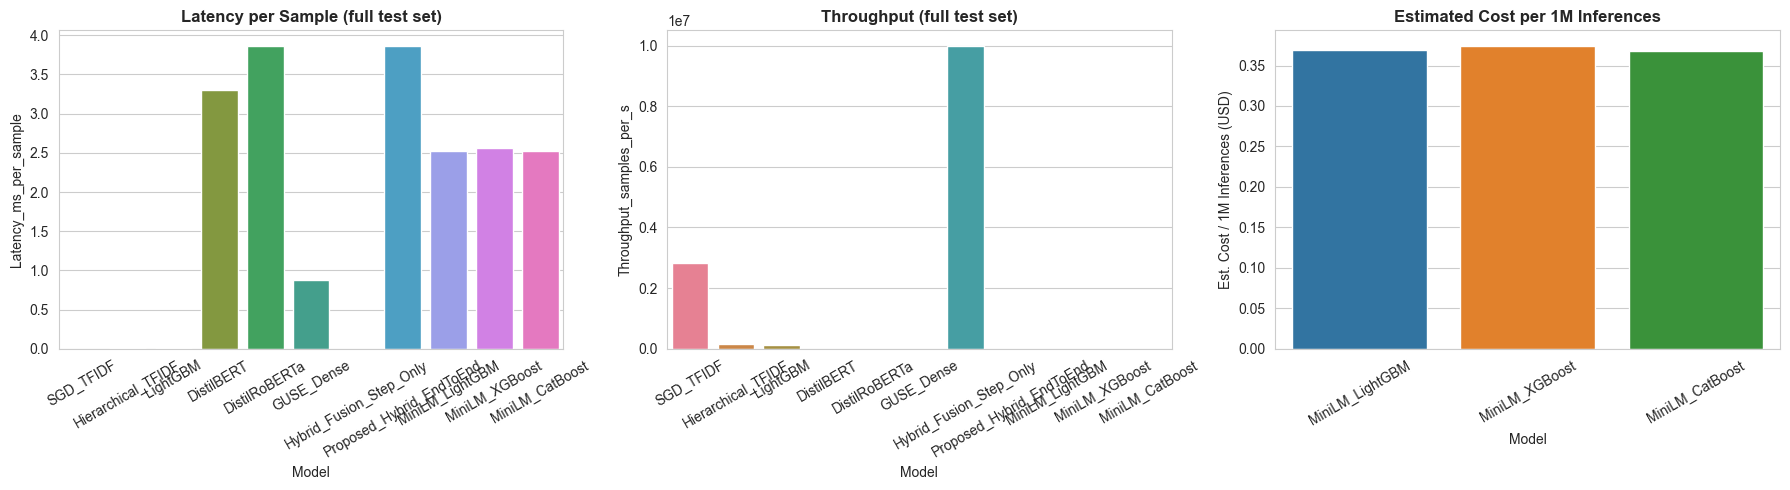

In [89]:
# ============================================================
# MiniLM + LightGBM / XGBoost / CatBoost
# + UNIFIED-SCHEMA Inference Benchmarking (matches your existing
#   inference_resource_log_v13.csv columns exactly, so rows compare
#   cleanly instead of showing NaN across the board)
#
# Install (run once):
#   pip install sentence-transformers xgboost catboost psutil GPUtil --break-system-packages
# ============================================================

# ============================================================
# CELL A: IMPORTS + CONFIG
# ============================================================
import os
import time
import threading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, accuracy_score, f1_score,
    precision_score, recall_score
)

import torch
import psutil

from sentence_transformers import SentenceTransformer
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

RANDOM_STATE = 42
TARGET_NAMES = ['Teenagers', 'Depression', 'Suicide']
MINILM_MODEL_NAME = "all-MiniLM-L6-v2"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"🖥️  Using device: {DEVICE}")

RESULTS_CSV   = "all_models_results_compare_v13.csv"
BENCHMARK_CSV = "inference_resource_log_v13.csv"
MODELS_DIR    = "saved_models_v13"
os.makedirs(MODELS_DIR, exist_ok=True)

# The exact model name your hybrid pipeline actually uses in the benchmark log —
# confirmed from your table as "Proposed_Hybrid_EndToEnd" (NOT "Hybrid_DistilRoBERTa_LightGBM").
HYBRID_MODEL_NAME = "Proposed_Hybrid_EndToEnd"

# Master column order — matches your existing inference_resource_log_v13.csv exactly,
# so every new row (and every old row) lines up under the same headers.
BENCHMARK_COLUMNS = [
    "Model", "N_Samples", "Total_Inference_Time_s", "Latency_ms_per_sample",
    "Throughput_samples_per_s", "CPU_Time_s", "CPU_Percent", "RAM_Used_MB",
    "RAM_Peak_MB", "GPU_Peak_MB", "Device",
    "Latency p50 (ms)", "Latency p95 (ms)", "Latency p99 (ms)",
    "Throughput (samples/sec)", "Peak VRAM (MB)", "Process RAM RSS (MB)",
    "Model Size on Disk (MB)", "Inferences Benchmarked (single + batch)",
    "Est. Cost / 1M Inferences (USD)",
]


# ============================================================
# CELL B: DATA LOADING — REUSE THE CANONICAL V13-ONLY SPLIT
# ============================================================
print("📥 Reusing the canonical v13-only split...")

# These DataFrames are created by the canonical split cell near the top.
# Reusing them guarantees that MiniLM models are compared on exactly the
# same rows as the TF-IDF, Transformer, GUSE, and Hybrid models.
required_split_names = ["train_df", "val_df", "test_df"]
missing_split_names = [name for name in required_split_names if name not in globals()]
if missing_split_names:
    raise RuntimeError(
        "Run the canonical v13-only split cell first. Missing: "
        + ", ".join(missing_split_names)
    )

X_train_raw = train_df["text"].reset_index(drop=True)
X_val_raw   = val_df["text"].reset_index(drop=True)
X_test_raw  = test_df["text"].reset_index(drop=True)

y_train = train_df["label"].reset_index(drop=True)
y_val   = val_df["label"].reset_index(drop=True)
y_test  = test_df["label"].reset_index(drop=True)

print(
    f"✅ v13-only data ready — "
    f"Train: {len(X_train_raw)} | Val: {len(X_val_raw)} | Test: {len(X_test_raw)}"
)

# ============================================================
# CELL C: MiniLM EMBEDDING EXTRACTION
# ============================================================
def get_minilm_embeddings(text_series, model, batch_size=64):
    texts = text_series.tolist()
    return model.encode(
        texts, batch_size=batch_size, show_progress_bar=True,
        convert_to_numpy=True, device=DEVICE, normalize_embeddings=True,
    )


print(f"⚙️  Loading MiniLM ({MINILM_MODEL_NAME}) on {DEVICE}...")
minilm_model = SentenceTransformer(MINILM_MODEL_NAME, device=DEVICE)

EMB_TRAIN_PATH = "minilm_emb_train_v13.npy"
EMB_VAL_PATH   = "minilm_emb_val_v13.npy"
EMB_TEST_PATH  = "minilm_emb_test_v13.npy"

if all(os.path.exists(p) for p in [EMB_TRAIN_PATH, EMB_VAL_PATH, EMB_TEST_PATH]):
    print("♻️  Loading cached MiniLM embeddings...")
    X_train_emb = np.load(EMB_TRAIN_PATH)
    X_val_emb   = np.load(EMB_VAL_PATH)
    X_test_emb  = np.load(EMB_TEST_PATH)
else:
    print("🧠 Generating MiniLM embeddings...")
    X_train_emb = get_minilm_embeddings(X_train_raw, minilm_model)
    X_val_emb   = get_minilm_embeddings(X_val_raw, minilm_model)
    X_test_emb  = get_minilm_embeddings(X_test_raw, minilm_model)
    np.save(EMB_TRAIN_PATH, X_train_emb)
    np.save(EMB_VAL_PATH, X_val_emb)
    np.save(EMB_TEST_PATH, X_test_emb)
    print("✅ Embeddings cached to disk.")

print(f"Shapes -> Train: {X_train_emb.shape} | Val: {X_val_emb.shape} | Test: {X_test_emb.shape}")


# ============================================================
# CELL D: save_results_to_csv
# ============================================================
def save_results_to_csv(model_name, y_true, y_pred, filename=RESULTS_CSV):
    print(f"💾 Saving {model_name} results...")
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    new_data = pd.DataFrame({'True_Labels': y_true, f'Pred_{model_name}': y_pred})

    if os.path.exists(filename):
        df_existing = pd.read_csv(filename)
        if not np.array_equal(df_existing['True_Labels'].values, new_data['True_Labels'].values):
            print("❌ CRITICAL WARNING: The 'y_true' labels don't match the file!")
            return
        df_existing[f'Pred_{model_name}'] = new_data[f'Pred_{model_name}']
        df_existing.to_csv(filename, index=False)
    else:
        new_data.to_csv(filename, index=False)
    print(f"✅ Successfully saved to '{filename}'")


# ============================================================
# CELL E: TRAIN — MiniLM + LightGBM
# ============================================================
print("\n" + "=" * 60)
print("🚀 TRAINING: MiniLM + LightGBM")
print("=" * 60)

lgbm_minilm = lgb.LGBMClassifier(
    n_estimators=400, learning_rate=0.05, num_leaves=63, max_depth=-1,
    subsample=0.8, colsample_bytree=0.8, objective='multiclass', num_class=3,
    random_state=RANDOM_STATE, n_jobs=-1,
)
lgbm_minilm.fit(
    X_train_emb, y_train,
    eval_set=[(X_val_emb, y_val)], eval_metric='multi_logloss',
    callbacks=[lgb.early_stopping(stopping_rounds=30), lgb.log_evaluation(period=50)],
)

lgbm_minilm_probs = lgbm_minilm.predict_proba(X_test_emb)
lgbm_minilm_preds = np.argmax(lgbm_minilm_probs, axis=1)
print(classification_report(y_test, lgbm_minilm_preds, target_names=TARGET_NAMES, digits=4))

np.save("minilm_lgbm_probs_v13.npy", lgbm_minilm_probs)
save_results_to_csv("MiniLM_LightGBM", y_test, lgbm_minilm_preds)

lgbm_minilm_path = os.path.join(MODELS_DIR, "minilm_lgbm_v13.txt")
lgbm_minilm.booster_.save_model(lgbm_minilm_path)


# ============================================================
# CELL F: TRAIN — MiniLM + XGBoost
# ============================================================
print("\n" + "=" * 60)
print("🚀 TRAINING: MiniLM + XGBoost")
print("=" * 60)

xgb_minilm = xgb.XGBClassifier(
    n_estimators=400, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, objective='multi:softprob', num_class=3,
    eval_metric='mlogloss', tree_method='hist', device=DEVICE,
    random_state=RANDOM_STATE, n_jobs=-1, early_stopping_rounds=30,
)
xgb_minilm.fit(X_train_emb, y_train, eval_set=[(X_val_emb, y_val)], verbose=50)

xgb_minilm_probs = xgb_minilm.predict_proba(X_test_emb)
xgb_minilm_preds = np.argmax(xgb_minilm_probs, axis=1)
print(classification_report(y_test, xgb_minilm_preds, target_names=TARGET_NAMES, digits=4))

np.save("minilm_xgb_probs_v13.npy", xgb_minilm_probs)
save_results_to_csv("MiniLM_XGBoost", y_test, xgb_minilm_preds)

xgb_minilm_path = os.path.join(MODELS_DIR, "minilm_xgb_v13.json")
xgb_minilm.save_model(xgb_minilm_path)


# ============================================================
# CELL G: TRAIN — MiniLM + CatBoost
# ============================================================
print("\n" + "=" * 60)
print("🚀 TRAINING: MiniLM + CatBoost")
print("=" * 60)

catboost_minilm = CatBoostClassifier(
    iterations=600, learning_rate=0.05, depth=6,
    loss_function='MultiClass', eval_metric='MultiClass',
    task_type="GPU" if DEVICE == "cuda" else "CPU",
    random_state=RANDOM_STATE, early_stopping_rounds=30, verbose=50,
)
catboost_minilm.fit(X_train_emb, y_train, eval_set=(X_val_emb, y_val))

catboost_minilm_probs = catboost_minilm.predict_proba(X_test_emb)
catboost_minilm_preds = np.argmax(catboost_minilm_probs, axis=1)
print(classification_report(y_test, catboost_minilm_preds, target_names=TARGET_NAMES, digits=4))

np.save("minilm_catboost_probs_v13.npy", catboost_minilm_probs)
save_results_to_csv("MiniLM_CatBoost", y_test, catboost_minilm_preds)

catboost_minilm_path = os.path.join(MODELS_DIR, "minilm_catboost_v13.cbm")
catboost_minilm.save_model(catboost_minilm_path)


# ============================================================
# CELL H: UNIFIED-SCHEMA BENCHMARKING
#
# Produces ONE row per model with BOTH your legacy columns
# (N_Samples, Total_Inference_Time_s, Latency_ms_per_sample,
#  Throughput_samples_per_s, CPU_Time_s, CPU_Percent, RAM_Used_MB,
#  RAM_Peak_MB, GPU_Peak_MB, Device) AND the newer columns
# (Latency p50/p95/p99, Peak VRAM, Process RAM RSS, Model Size on
#  Disk, Inferences Benchmarked, Est. Cost/1M) filled in — so this
# row is directly comparable to every other row in your CSV,
# old or new.
# ============================================================

def _rss_mb():
    return psutil.Process(os.getpid()).memory_info().rss / (1024 ** 2)


class _RamSampler:
    """Background thread that samples RSS every `interval`s so we can
    report a true peak, matching how your earlier benchmarks captured
    RAM_Peak_MB."""
    def __init__(self, interval=0.05):
        self.interval = interval
        self.readings = []
        self._stop = threading.Event()
        self._thread = threading.Thread(target=self._run, daemon=True)

    def _run(self):
        proc = psutil.Process(os.getpid())
        while not self._stop.is_set():
            self.readings.append(proc.memory_info().rss / (1024 ** 2))
            time.sleep(self.interval)

    def __enter__(self):
        self._thread.start()
        return self

    def __exit__(self, *exc):
        self._stop.set()
        self._thread.join(timeout=1)

    @property
    def peak(self):
        return max(self.readings) if self.readings else _rss_mb()


def benchmark_minilm_tree_model_full_schema(
    model_name, minilm_encoder, predict_fn, model_disk_path,
    X_test_texts, y_test_labels, device,
    embed_batch_size=64, n_single=200, live_batch_size=64,
):
    print(f"\n⏱️  Benchmarking: {model_name}")

    texts = X_test_texts.tolist() if hasattr(X_test_texts, 'tolist') else list(X_test_texts)
    n_samples = len(texts)

    proc = psutil.Process(os.getpid())

    # ---- Warm-up (excluded from timing) ----
    warm_emb = minilm_encoder.encode(texts[:8], device=device, convert_to_numpy=True,
                                      normalize_embeddings=True, show_progress_bar=False)
    _ = predict_fn(warm_emb)
    if device == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    # ---- FULL-TEST-SET pass: fills the legacy-style columns ----
    cpu_times_before = proc.cpu_times()
    rss_before = _rss_mb()
    cpu_pct_samples = []

    def _cpu_poll(stop_evt):
        while not stop_evt.is_set():
            cpu_pct_samples.append(proc.cpu_percent(interval=None))
            time.sleep(0.1)

    stop_evt = threading.Event()
    cpu_thread = threading.Thread(target=_cpu_poll, args=(stop_evt,), daemon=True)

    with _RamSampler(interval=0.05) as ram_sampler:
        cpu_thread.start()
        t0 = time.perf_counter()
        full_emb = minilm_encoder.encode(
            texts, batch_size=embed_batch_size, device=device,
            convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False,
        )
        full_preds = predict_fn(full_emb)
        if device == "cuda":
            torch.cuda.synchronize()
        t1 = time.perf_counter()
        stop_evt.set()
        cpu_thread.join(timeout=1)

    cpu_times_after = proc.cpu_times()
    rss_after = _rss_mb()

    total_inference_time_s = t1 - t0
    latency_ms_per_sample = (total_inference_time_s * 1000) / n_samples
    throughput_samples_per_s = n_samples / total_inference_time_s
    cpu_time_s = (cpu_times_after.user + cpu_times_after.system) - \
                 (cpu_times_before.user + cpu_times_before.system)
    cpu_percent = float(np.mean(cpu_pct_samples)) if cpu_pct_samples else np.nan
    ram_used_mb = rss_after - rss_before
    ram_peak_mb = ram_sampler.peak
    gpu_peak_mb = (torch.cuda.max_memory_allocated() / (1024 ** 2)) if device == "cuda" else 0.0

    # ---- Single-sample latency percentiles (new-style columns) ----
    sample_texts = texts[:n_single]
    single_latencies_ms = []
    for text in sample_texts:
        ts0 = time.perf_counter()
        emb = minilm_encoder.encode([text], device=device, convert_to_numpy=True,
                                     normalize_embeddings=True, show_progress_bar=False)
        _ = predict_fn(emb)
        if device == "cuda":
            torch.cuda.synchronize()
        ts1 = time.perf_counter()
        single_latencies_ms.append((ts1 - ts0) * 1000)
    single_latencies_ms = np.array(single_latencies_ms)
    p50 = np.percentile(single_latencies_ms, 50)
    p95 = np.percentile(single_latencies_ms, 95)
    p99 = np.percentile(single_latencies_ms, 99)

    # ---- Batch throughput (new-style column, repeated small batches) ----
    batch_texts = (sample_texts * ((live_batch_size // len(sample_texts)) + 1))[:live_batch_size]
    n_repeats = 10
    tb0 = time.perf_counter()
    for _ in range(n_repeats):
        emb = minilm_encoder.encode(batch_texts, batch_size=live_batch_size, device=device,
                                     convert_to_numpy=True, normalize_embeddings=True,
                                     show_progress_bar=False)
        _ = predict_fn(emb)
        if device == "cuda":
            torch.cuda.synchronize()
    tb1 = time.perf_counter()
    live_batch_throughput = (live_batch_size * n_repeats) / (tb1 - tb0)

    disk_size_mb = os.path.getsize(model_disk_path) / (1024 ** 2) if os.path.exists(model_disk_path) else np.nan

    rate = 0.526 if device == "cuda" else 0.17   # g4dn.xlarge (T4) vs c5.xlarge, USD/hr
    seconds_per_1m = 1_000_000 / throughput_samples_per_s
    cost_per_1m = (seconds_per_1m / 3600) * rate

    row = {
        "Model": model_name,
        "N_Samples": n_samples,
        "Total_Inference_Time_s": round(total_inference_time_s, 4),
        "Latency_ms_per_sample": round(latency_ms_per_sample, 4),
        "Throughput_samples_per_s": round(throughput_samples_per_s, 2),
        "CPU_Time_s": round(cpu_time_s, 4),
        "CPU_Percent": round(cpu_percent, 1) if not np.isnan(cpu_percent) else np.nan,
        "RAM_Used_MB": round(ram_used_mb, 2),
        "RAM_Peak_MB": round(ram_peak_mb, 2),
        "GPU_Peak_MB": round(gpu_peak_mb, 2),
        "Device": device.upper(),
        "Latency p50 (ms)": round(p50, 2),
        "Latency p95 (ms)": round(p95, 2),
        "Latency p99 (ms)": round(p99, 2),
        "Throughput (samples/sec)": round(live_batch_throughput, 2),
        "Peak VRAM (MB)": round(gpu_peak_mb, 1) if device == "cuda" else "N/A (CPU)",
        "Process RAM RSS (MB)": round(rss_after, 1),
        "Model Size on Disk (MB)": round(disk_size_mb, 3) if not np.isnan(disk_size_mb) else np.nan,
        "Inferences Benchmarked (single + batch)": n_single + (live_batch_size * n_repeats),
        "Est. Cost / 1M Inferences (USD)": round(cost_per_1m, 4),
    }

    print(f"   N={n_samples} | {latency_ms_per_sample:.4f} ms/sample | "
          f"{throughput_samples_per_s:.1f} samples/s (full-set) | "
          f"p50={p50:.2f}ms | RAM peak={ram_peak_mb:.1f}MB | GPU peak={gpu_peak_mb:.1f}MB")
    return row


benchmark_rows = []

benchmark_rows.append(benchmark_minilm_tree_model_full_schema(
    "MiniLM_LightGBM", minilm_model, lambda emb: lgbm_minilm.predict(emb),
    lgbm_minilm_path, X_test_raw, y_test, DEVICE,
))
benchmark_rows.append(benchmark_minilm_tree_model_full_schema(
    "MiniLM_XGBoost", minilm_model, lambda emb: xgb_minilm.predict(emb),
    xgb_minilm_path, X_test_raw, y_test, DEVICE,
))
benchmark_rows.append(benchmark_minilm_tree_model_full_schema(
    "MiniLM_CatBoost", minilm_model, lambda emb: catboost_minilm.predict(emb),
    catboost_minilm_path, X_test_raw, y_test, DEVICE,
))

df_benchmark_new = pd.DataFrame(benchmark_rows)[BENCHMARK_COLUMNS]

# ---- Merge with existing log: drop old rows for these 3 models, keep everything else ----
if os.path.exists(BENCHMARK_CSV):
    df_bench_prev = pd.read_csv(BENCHMARK_CSV)
    # Ensure prev has every column (fills any truly-missing ones with NaN, preserves order)
    for col in BENCHMARK_COLUMNS:
        if col not in df_bench_prev.columns:
            df_bench_prev[col] = np.nan
    df_bench_prev = df_bench_prev[BENCHMARK_COLUMNS]
    df_bench_prev = df_bench_prev[~df_bench_prev["Model"].isin(df_benchmark_new["Model"])]
    df_benchmark = pd.concat([df_bench_prev, df_benchmark_new], ignore_index=True)
else:
    df_benchmark = df_benchmark_new

df_benchmark = df_benchmark[BENCHMARK_COLUMNS]
print("\n📋 INFERENCE BENCHMARK SUMMARY (unified schema)")
print(df_benchmark.to_string(index=False))
df_benchmark.to_csv(BENCHMARK_CSV, index=False)
print(f"✅ Saved to '{BENCHMARK_CSV}'")

if HYBRID_MODEL_NAME not in df_benchmark["Model"].values:
    print(f"\n⚠️  '{HYBRID_MODEL_NAME}' not found in {BENCHMARK_CSV} — double-check the name.")


# ============================================================
# CELL I: COMPARISON — accuracy/F1 (from RESULTS_CSV) + benchmark
# ============================================================
if os.path.exists(RESULTS_CSV):
    df_all = pd.read_csv(RESULTS_CSV)
    y_true_all = df_all['True_Labels'].values
    pred_cols = [c for c in df_all.columns if c.startswith('Pred_')]

    comparison_rows = []
    for col in pred_cols:
        name = col.replace('Pred_', '')
        y_pred = df_all[col].values
        acc = accuracy_score(y_true_all, y_pred)
        f1 = f1_score(y_true_all, y_pred, average='weighted')
        prec = precision_score(y_true_all, y_pred, average='weighted')
        recalls = recall_score(y_true_all, y_pred, average=None)
        suicide_recall = recalls[2] if len(recalls) > 2 else np.nan
        comparison_rows.append({
            'Model': name, 'Accuracy': acc, 'F1 (Weighted)': f1,
            'Precision (Weighted)': prec, 'Suicide Recall (Safety)': suicide_recall,
        })
    df_comparison = pd.DataFrame(comparison_rows).sort_values(by='F1 (Weighted)', ascending=False)

    df_final_merged = df_comparison.merge(
        df_benchmark[[
            "Model", "N_Samples", "Latency_ms_per_sample", "Throughput_samples_per_s",
            "RAM_Peak_MB", "GPU_Peak_MB", "Latency p50 (ms)", "Throughput (samples/sec)",
            "Est. Cost / 1M Inferences (USD)",
        ]],
        on="Model", how="left",
    ).sort_values(by="F1 (Weighted)", ascending=False)

    print("\n🏆 FINAL MERGED TABLE — Accuracy + Efficiency (incl. Hybrid model)")
    print(df_final_merged.round(4).to_string(index=False))
    df_final_merged.to_csv("final_accuracy_and_efficiency_table_v13.csv", index=False)
    print("\n✅ Saved to 'final_accuracy_and_efficiency_table_v13.csv'")
else:
    print(f"⚠️  {RESULTS_CSV} not found — skipping accuracy comparison.")


# ============================================================
# CELL J: VISUALIZE — Latency & Throughput & Cost (full-set metrics)
# ============================================================
plot_df = df_benchmark.dropna(subset=["Throughput_samples_per_s"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=plot_df, x="Model", y="Latency_ms_per_sample", ax=axes[0], hue="Model", legend=False)
axes[0].set_title("Latency per Sample (full test set)", fontweight='bold')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(data=plot_df, x="Model", y="Throughput_samples_per_s", ax=axes[1], hue="Model", legend=False)
axes[1].set_title("Throughput (full test set)", fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

cost_df = df_benchmark.dropna(subset=["Est. Cost / 1M Inferences (USD)"])
sns.barplot(data=cost_df, x="Model", y="Est. Cost / 1M Inferences (USD)", ax=axes[2], hue="Model", legend=False)
axes[2].set_title("Estimated Cost per 1M Inferences", fontweight='bold')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig("inference_efficiency_comparison.png", dpi=200)
plt.show()

Models included in the graphs:
['SGD_TFIDF', 'Hierarchical_TFIDF', 'LightGBM', 'DistilBERT', 'DistilRoBERTa', 'GUSE_Dense', 'Hybrid_Fusion_Step_Only', 'Proposed_Hybrid_EndToEnd', 'MiniLM_LightGBM', 'MiniLM_XGBoost', 'MiniLM_CatBoost']


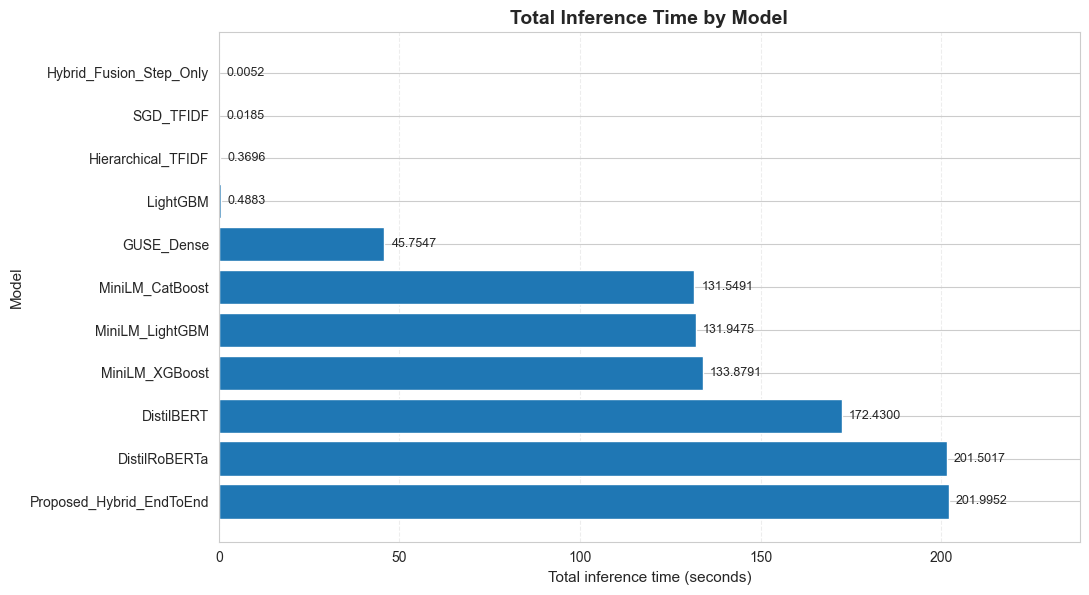

Saved: inference_resource_graphs_v13\total_inference_time.png


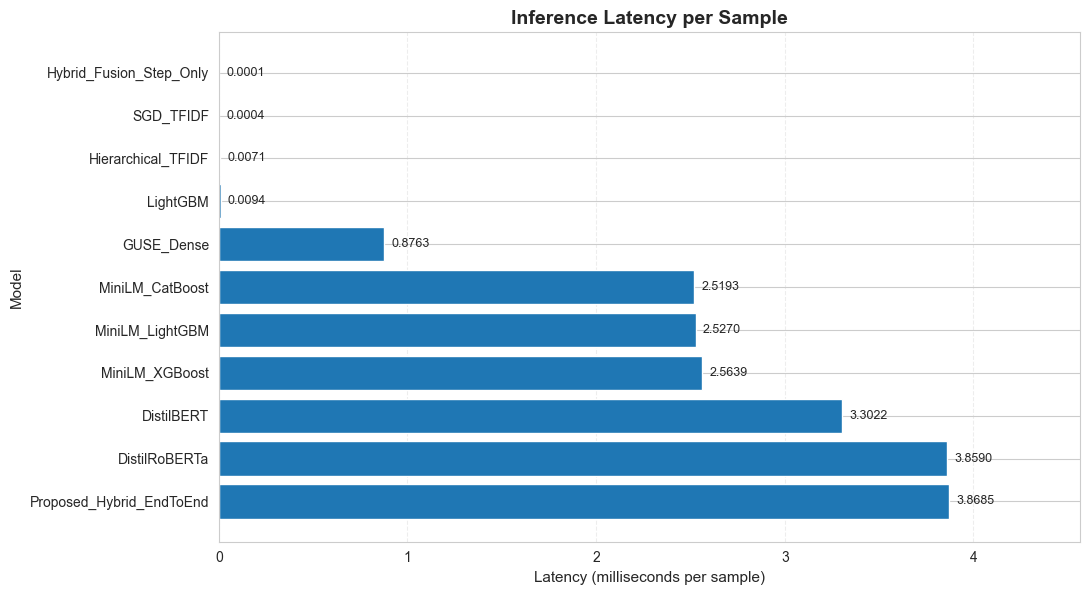

Saved: inference_resource_graphs_v13\latency_per_sample.png


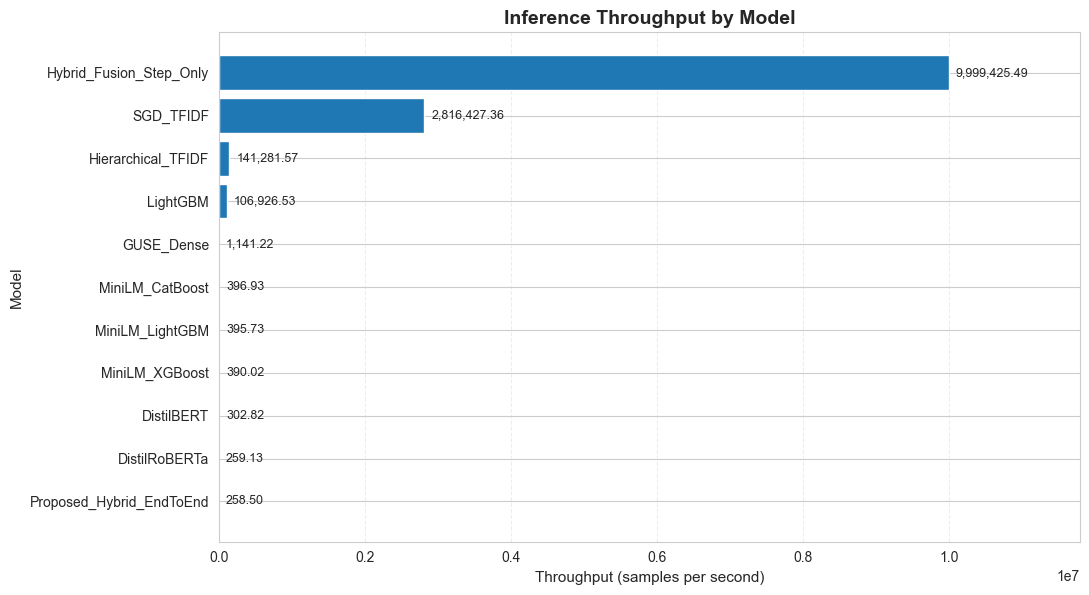

Saved: inference_resource_graphs_v13\throughput_samples_per_second.png


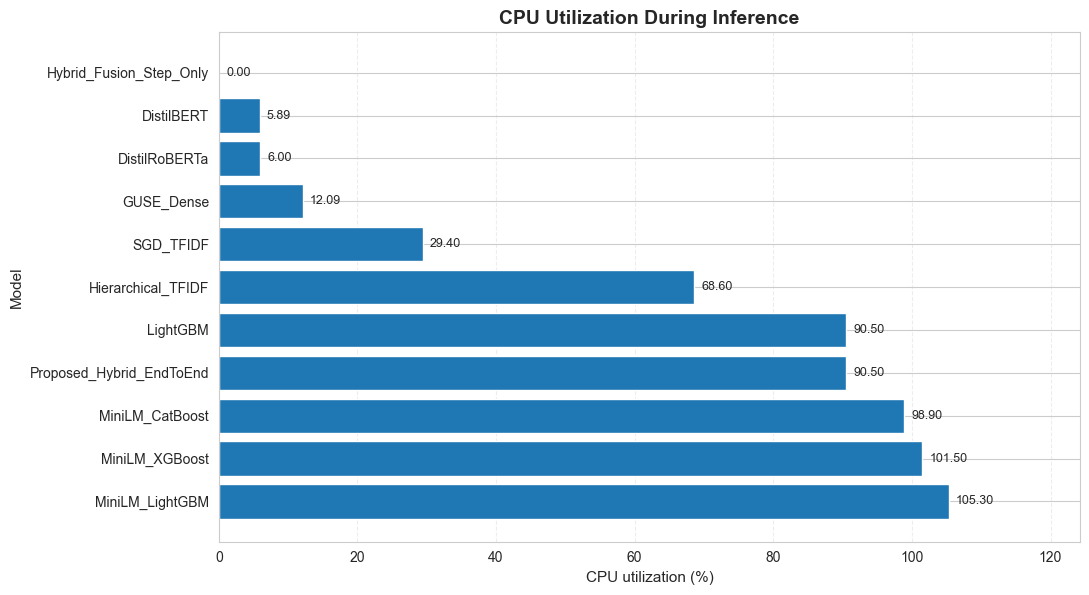

Saved: inference_resource_graphs_v13\cpu_utilization.png


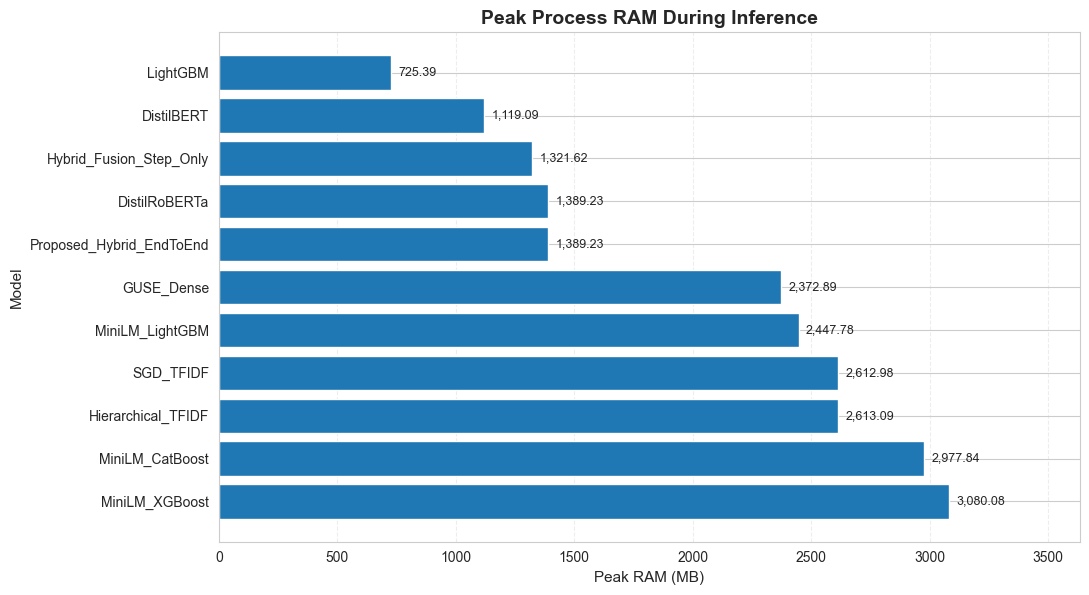

Saved: inference_resource_graphs_v13\peak_ram.png


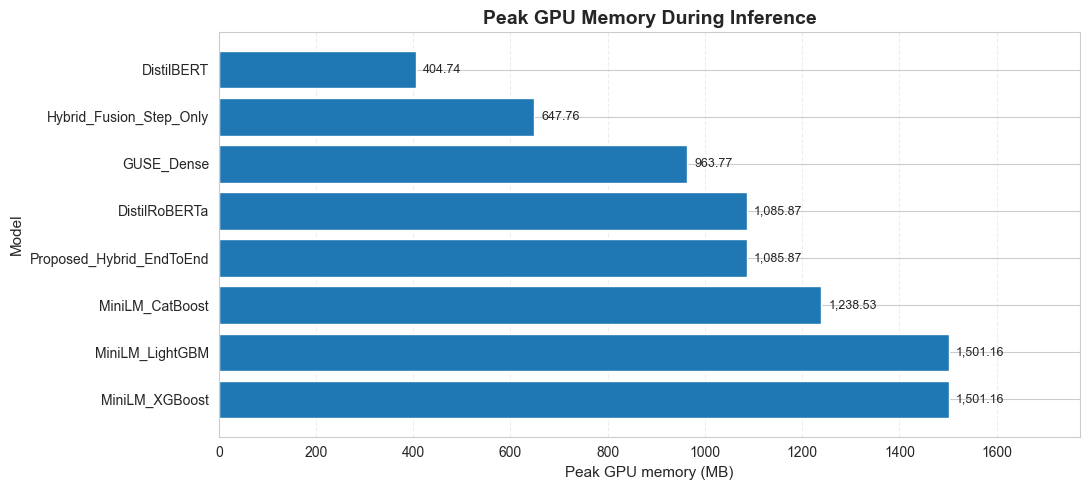

Saved: inference_resource_graphs_v13\peak_gpu_memory.png

Cleaned inference comparison table:
                   Model  Total_Inference_Time_s  Latency_ms_per_sample  Throughput_samples_per_s  CPU_Percent  RAM_Peak_MB  GPU_Peak_MB
               SGD_TFIDF                  0.0185                 0.0004                2816427.36        29.40      2612.98         0.00
      Hierarchical_TFIDF                  0.3696                 0.0071                 141281.57        68.60      2613.09         0.00
                LightGBM                  0.4883                 0.0094                 106926.53        90.50       725.39         0.00
              DistilBERT                172.4300                 3.3022                    302.82         5.89      1119.09       404.74
           DistilRoBERTa                201.5017                 3.8590                    259.13         6.00      1389.23      1085.87
              GUSE_Dense                 45.7547                 0.8763             

In [90]:
# ============================================================
# VISUALIZE INFERENCE RESOURCE LOG
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "inference_resource_log_v13.csv"
OUTPUT_DIR = "inference_resource_graphs_v13"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD AND CLEAN THE CSV
# ------------------------------------------------------------

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"Could not find: {CSV_PATH}"
    )

df_inference = pd.read_csv(CSV_PATH)

# Remove accidental spaces from column names
df_inference.columns = (
    df_inference.columns
    .str.strip()
)

# Remove completely empty rows
df_inference = (
    df_inference
    .dropna(how="all")
    .copy()
)

required_columns = [
    "Model",
    "N_Samples",
    "Total_Inference_Time_s",
    "Latency_ms_per_sample",
    "Throughput_samples_per_s",
    "CPU_Time_s",
    "CPU_Percent",
    "RAM_Used_MB",
    "RAM_Peak_MB",
    "GPU_Peak_MB"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_inference.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in the CSV: {missing_columns}"
    )

# Convert measurement columns to numeric
numeric_columns = [
    column
    for column in required_columns
    if column != "Model"
]

for column in numeric_columns:
    df_inference[column] = pd.to_numeric(
        df_inference[column],
        errors="coerce"
    )

# Remove rows without a valid model name
df_inference = df_inference.dropna(
    subset=["Model"]
)

df_inference["Model"] = (
    df_inference["Model"]
    .astype(str)
    .str.strip()
)

# Keep the most recently saved result when a model appears repeatedly
df_inference = (
    df_inference
    .drop_duplicates(
        subset="Model",
        keep="last"
    )
    .reset_index(drop=True)
)

print("Models included in the graphs:")
print(df_inference["Model"].tolist())


# ------------------------------------------------------------
# 2. HELPER FUNCTION FOR HORIZONTAL BAR CHARTS
# ------------------------------------------------------------

def plot_horizontal_metric(
    dataframe,
    metric,
    title,
    x_label,
    filename,
    decimals=2,
    higher_is_better=False
):
    plot_df = (
        dataframe[
            ["Model", metric]
        ]
        .dropna()
        .copy()
    )

    # For throughput, highest value should appear at the top.
    # For latency/time, lowest value should appear at the top.
    plot_df = plot_df.sort_values(
        metric,
        ascending=not higher_is_better
    )

    figure_height = max(
        5,
        len(plot_df) * 0.55
    )

    fig, ax = plt.subplots(
        figsize=(11, figure_height)
    )

    bars = ax.barh(
        plot_df["Model"],
        plot_df[metric]
    )

    ax.invert_yaxis()

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        x_label,
        fontsize=11
    )

    ax.set_ylabel(
        "Model",
        fontsize=11
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.35
    )

    maximum_value = plot_df[metric].max()

    for bar, value in zip(
        bars,
        plot_df[metric]
    ):
        label = f"{value:,.{decimals}f}"

        ax.text(
            bar.get_width()
            + maximum_value * 0.01,
            bar.get_y()
            + bar.get_height() / 2,
            label,
            va="center",
            fontsize=9
        )

    ax.set_xlim(
        0,
        maximum_value * 1.18
        if maximum_value > 0
        else 1
    )

    plt.tight_layout()

    output_path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")


# ------------------------------------------------------------
# 3. TOTAL INFERENCE TIME
# Lower is better
# ------------------------------------------------------------

plot_horizontal_metric(
    dataframe=df_inference,
    metric="Total_Inference_Time_s",
    title="Total Inference Time by Model",
    x_label="Total inference time (seconds)",
    filename="total_inference_time.png",
    decimals=4,
    higher_is_better=False
)


# ------------------------------------------------------------
# 4. LATENCY PER SAMPLE
# Lower is better
# ------------------------------------------------------------

plot_horizontal_metric(
    dataframe=df_inference,
    metric="Latency_ms_per_sample",
    title="Inference Latency per Sample",
    x_label="Latency (milliseconds per sample)",
    filename="latency_per_sample.png",
    decimals=4,
    higher_is_better=False
)


# ------------------------------------------------------------
# 5. THROUGHPUT
# Higher is better
# ------------------------------------------------------------

plot_horizontal_metric(
    dataframe=df_inference,
    metric="Throughput_samples_per_s",
    title="Inference Throughput by Model",
    x_label="Throughput (samples per second)",
    filename="throughput_samples_per_second.png",
    decimals=2,
    higher_is_better=True
)


# ------------------------------------------------------------
# 6. CPU UTILIZATION
# ------------------------------------------------------------

plot_horizontal_metric(
    dataframe=df_inference,
    metric="CPU_Percent",
    title="CPU Utilization During Inference",
    x_label="CPU utilization (%)",
    filename="cpu_utilization.png",
    decimals=2,
    higher_is_better=False
)


# ------------------------------------------------------------
# 7. PEAK RAM
# Lower is generally better
# ------------------------------------------------------------

plot_horizontal_metric(
    dataframe=df_inference,
    metric="RAM_Peak_MB",
    title="Peak Process RAM During Inference",
    x_label="Peak RAM (MB)",
    filename="peak_ram.png",
    decimals=2,
    higher_is_better=False
)


# ------------------------------------------------------------
# 8. PEAK GPU MEMORY
# Lower is generally better
# ------------------------------------------------------------

gpu_df = df_inference[
    df_inference["GPU_Peak_MB"].fillna(0) > 0
].copy()

if not gpu_df.empty:
    plot_horizontal_metric(
        dataframe=gpu_df,
        metric="GPU_Peak_MB",
        title="Peak GPU Memory During Inference",
        x_label="Peak GPU memory (MB)",
        filename="peak_gpu_memory.png",
        decimals=2,
        higher_is_better=False
    )
else:
    print(
        "No positive GPU memory measurements were found; "
        "the GPU graph was skipped."
    )


# ------------------------------------------------------------
# 9. PRINT CLEANED TABLE
# ------------------------------------------------------------

display_columns = [
    "Model",
    "Total_Inference_Time_s",
    "Latency_ms_per_sample",
    "Throughput_samples_per_s",
    "CPU_Percent",
    "RAM_Peak_MB",
    "GPU_Peak_MB"
]

print("\nCleaned inference comparison table:")
print(
    df_inference[
        display_columns
    ].to_string(index=False)
)

print(
    f"\nAll graphs were saved under: {OUTPUT_DIR}"
)